# Part A — QI-SABP preprocessing pipeline

A quantum-inspired preprocessing pipeline for cervical colposcopy images.

## What is "quantum-inspired" here

The pipeline borrows two ideas from quantum information theory and applies them
in a classical image-processing pipeline; no quantum hardware or quantum
algorithms are used.

1. **Soft superposition of bit-depths.** Instead of assigning each pixel to a
   fixed quantiser (the classical `mask ? 8 bits : 4 bits` decision), the soft
   saliency mask `W ∈ [0,1]` is used as a continuous control parameter that
   *interpolates* between a high-fidelity and a low-fidelity quantiser, so a
   pixel is *partially* in the salient branch and *partially* in the
   compressed branch. The output is then collapsed to a single uint8 value
   per channel by averaging the two branches. This is the classical analogue
   of a qubit being in a superposition of two computational basis states,
   collapsed by measurement.
2. **Information-bounded allocation.** Bit budget per pixel is treated as a
   finite *information resource* that is allocated non-uniformly across the
   image (more bits where there is information, fewer where there is not),
   analogous to allocating qubits to sub-regions of a state vector in
   approximate quantum simulation schemes.

Everything else in this notebook — Sobel gradients, FFT spectral residual,
multi-scale contrast, local entropy, NLM denoise, YCbCr 4:2:0 subsampling,
bilateral filtering, histogram matching — is standard classical image
processing. The "quantum-inspired" label refers strictly to the soft
superposition / information-bounded allocation above.

## Pipeline overview

* Step 1 — Unsharp-mask sharpen (carried over from Step 1).
* Step 2 — Quantum-inspired fused saliency (Sobel + spectral residual +
  multi-scale contrast + local entropy) with FOV-rim masking, soft mask,
  edge-aware continuous bit allocation, optional NLM pre-denoise on the
  non-salient branch, adaptive dithered quantization with YCbCr 4:2:0
  chroma subsampling, soft-blend with the original, optional bilateral
  post-filter on the salient boundary, optional partial histogram match.

## Output

The pipeline returns a **lossy image** (uint8 RGB, same shape as the input).
It is NOT a compression scheme: real bytes only fall if you entropy-code the
quantised values, which this notebook does not do. The output PNG is
approximately the same size as the input PNG. The pipeline is therefore
evaluated as an image-processing technique (distortion, stability,
diagnostics), not as a codec.

## What this notebook does NOT claim

* It does NOT produce a compressed byte stream.
* It does NOT compare techniques against each other (that requires the
  multi-patient notebook).
* It does NOT demonstrate a clinical benefit on this single patient.


In [77]:
# ============================================================
# Cell 1.1 — Combined imports & global setup
# ============================================================
import os, sys, glob, time, json, math, random, warnings, platform
from collections import defaultdict
from pathlib import Path

import numpy as np
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import ListedColormap

import pandas as pd
from scipy import ndimage, stats
from scipy.fft import fft2, fftshift
from scipy.ndimage import gaussian_filter
from scipy.stats import (pearsonr, spearmanr, ks_2samp,
                          wasserstein_distance, entropy as scipy_entropy,
                          wilcoxon, anderson_ksamp)
from sklearn.metrics import (roc_auc_score, average_precision_score,
                              roc_curve, precision_recall_curve)
try:
    from skimage.exposure import match_histograms as _sk_match_hist
    _SKIMAGE_OK = True
except ImportError:
    _SKIMAGE_OK = False
    print("[warn] scikit-image not available — H5 histogram matching will be skipped.")

warnings.filterwarnings('ignore')

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

# Optional torch backend (not required, but used if available)
try:
    import torch
    _TORCH_OK = True
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if DEVICE.type == 'cuda':
        torch.cuda.manual_seed_all(SEED)
        print(f"[gpu] PyTorch {torch.__version__} | CUDA device: "
              f"{torch.cuda.get_device_name(0)}")
    else:
        print(f"[gpu] PyTorch {torch.__version__} | CPU backend.")
except ImportError:
    _TORCH_OK = False
    DEVICE = None

# Output directory for results / CSV / JSON artefacts
# Relative path so the notebook is portable across Windows / Linux / macOS.
SAVE_DIR = 'results'
os.makedirs(SAVE_DIR, exist_ok=True)

print(f"\nQI-SABP Validation Pipeline — Python {platform.python_version()}")
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | OpenCV {cv2.__version__}")
print(f"Random seed: {SEED}")
print(f"Output directory: {SAVE_DIR}")
print("All imports OK.")


[gpu] PyTorch 2.5.1+cu121 | CUDA device: NVIDIA GeForce RTX 3050 Laptop GPU

QI-SABP Validation Pipeline — Python 3.10.20
NumPy 2.2.6 | Pandas 2.3.3 | OpenCV 4.11.0
Random seed: 42
Output directory: results
All imports OK.


In [78]:
# ============================================================
# Cell 2 -- Configuration
#   Single-class invasive carcinoma dataset.
#   Expected layout (configurable below):
#       <DATASET_ROOT>/<INVASIVE_DIR>/images/*.jpg
#       <DATASET_ROOT>/<INVASIVE_DIR>/<MASKS_SUBDIR>/*.png
# ============================================================

# ---- Image size ----
IMG_SIZE = 200

# ---- Data ----
# Use forward slashes -- works on both Windows and Linux/macOS.
DATASET_ROOT   = "C:/CER/dataset"   # <-- your dataset root
INVASIVE_DIR   = "invasive cancer"  # <-- single class folder (note the space)
MASKS_SUBDIR   = "masks"            # set "" if masks live directly under invasive cancer/
CLASSES        = ["invasive cancer"]  # only one class

# ---- Sharpen (Step 1) ----
# This setting comes from Step 1 and is shared across all 26 notebooks in
# the suite. It was briefly changed to 0.5 on this patient, which moved
# the cache_hash from 12f68b681210 to 80e0c63a4221 and broke comparability
# with the other 25 notebooks. Reverted to 0.8 (the Step 1 default) so
# this notebook's cache_hash matches the rest of the suite. If you change
# it here, change it in all 26 notebooks and re-run them.
APPLY_SHARPEN  = True
SHARPEN_AMOUNT = 0.8
SHARPEN_KSIZE  = 5

# ---- QI-SABP saliency fusion (Step 2) ----
SALIENCY_TAU          = 50      # Sobel threshold (diagnostic only)
SALIENCY_SIGMA        = 2.0     # Gaussian smoothing of fused saliency
SALIENCY_W_SOBEL      = 0.25    # restored to design defaults (whiteness off)
SALIENCY_W_SPECTRAL   = 0.30
SALIENCY_W_CONTRAST   = 0.30
SALIENCY_W_ENTROPY    = 0.15
SALIENCY_RIM_ERODE    = 5       # px to erode the FOV mask before saliency
# Whiteness channel: acetowhite epithelium is bright AND low-saturation AND
# not pure specular glare. The channel is the CDF of (V * (1 - S/255)) inside
# the FOV (excluding the dilated glare mask), so it measures "white but not
# specular". Default weight 0.20 (the four other channels sum to 0.80, this
# adds 0.20). On/off via USE_WHITENESS; ablation row in cell 31.
SALIENCY_W_WHITENESS  = 0.0
USE_WHITENESS         = False   # the hole fill covers the pale blob, so the
                             # whiteness channel is not needed

# ---- Glare handling for saliency (Step 2) ----
# Glare pixels are detected and filled with the local median before
# saliency is computed, so the Sobel/contrast/entropy channels do not
# produce spurious hot spots at the bright glare dots.
#
# Tightening (this round): the previous V > 240, S < 40 detector was too
# permissive and caught large acetowhite epithelium regions (which are
# diagnostically relevant). The detector is now V > 250, S < 25 (much
# brighter and much less saturated), AND each connected component must
# be smaller than GLARE_MAX_BLOB_FRAC of the FOV area. The area filter
# rejects large acetowhite blobs while keeping the small specular dots
# that are real glare. The on/off toggle is USE_GLARE_MASK.
#
# GLARE_DILATE reverted from 5 to 2 this round: GLARE_DILATE=5 plus the
# median fill created big low-saliency holes on the lesion surface where
# glare dots cluster, over-suppressing the central vascular zone. The
# measured glare-overlap (W>=0.5 AND glare) / (W>=0.5) is printed by cell 6
# (it is by construction -- the fill copies neighbours, so glare pixels
# are hot). The halo check in cell 6 uses a 15px ring baseline so the
# comparison is meaningful.
USE_GLARE_MASK        = True
GLARE_V_THR           = 250     # was 240; tightened so acetowhite is not flagged
GLARE_S_THR           = 25      # was 40; tightened so acetowhite is not flagged
GLARE_MAX_BLOB_FRAC   = 0.01    # reject glare blobs > 1% of FOV area (acetowhite)
GLARE_DILATE          = 2       # was 5; reverted to 2 to stop over-suppression

# ---- FOV rim margin for saliency (Step 2) ----
# The FOV rim produces a faint yellow crescent along the top edge and a
# thin strip on the right edge of the saliency map. We zero the saliency
# within SALIENCY_RIM_MARGIN px of the FOV boundary AFTER the Gaussian
# smoothing and AFTER the normalisation. SALIENCY_RIM_ERODE (used for
# the FOV mask before saliency) is 5; SALIENCY_RIM_MARGIN (used to zero
# the final saliency) is 10. The rim-margin zeroing already removes
# anything touching the FOV boundary, so no separate border-touching
# filter is needed.
SALIENCY_RIM_MARGIN   = 10      # px to zero the saliency near the FOV boundary

# ---- Saliency normalisation (Step 2) ----
# Three modes are supported:
#   "rank"   (default): s_norm = rank(s) / N inside the eroded FOV mask.
#                       This is a CDF / rank transform: s_norm is uniformly
#                       distributed in [0, 1] inside the FOV, so the soft-mask
#                       threshold directly corresponds to a coverage fraction
#                       (thr = 0.55 -> 45% of pixels above the threshold).
#                       This makes the threshold a tunable coverage knob and
#                       removes the saturation problem (the map is no longer
#                       dominated by a few bright outliers).
#   "robust": s_norm = clip((s - p_lo) / (p_hi - p_lo), 0, 1) where p_lo/p_hi
#             are the SALIENCY_PCT_LOW/HIGH percentiles inside the FOV. More
#             aggressive than min-max but still sensitive to the distribution
#             shape; kept as an ablation.
#   "minmax": s_norm = (s - s.min) / (s.max - s.min). The original behaviour;
#             a single hot pixel can push the whole map to 0. Kept as an
#             ablation.
SALIENCY_NORMALIZE    = "rank"   # "rank" (CDF), "robust", or "minmax"
SALIENCY_PCT_LOW      = 1         # for "robust" mode
SALIENCY_PCT_HIGH     = 99.9      # for "robust" mode

# ---- Soft mask (Step 2) ----
# With the CDF/rank normalisation above, the threshold is a DIRECT coverage
# knob: thr = 0.55 means 55% of FOV pixels are below it (45% are above,
# i.e. salient). The user requested ~35-45% salient coverage, so the
# threshold is set to 0.55 (45% salient). With salient=8 bits and
# non-salient=4 bits, the mean bit rate is then 4 + 4*0.45 = 5.8 bits/px.
#
# The gain is much lower than before (0.5 instead of 5.0) because the
# CDF transform already spreads the saliency uniformly: the sigmoid does
# not need to be steep to get a narrow transition band. At gain=0.5 the
# transition band (0.2 <= W <= 0.8) is ~2% of the FOV, well under the
# 20% target.
#
# SOFT_MASK_THR_MODE: "fixed" uses SOFT_MASK_FIXED_THR for every image;
# "per_image" computes the threshold per image as the
# (1 - SOFT_MASK_COVERAGE) percentile of the CDF, so coverage is held
# constant across images. The per-cluster figure showed clusters 1 and 3
# were hotter toward the periphery than the others, so a fixed 0.55
# threshold marked more of them salient. The per-image mode equalises
# coverage. The cell-31 sweep reports per-cluster coverage in both modes.
SOFT_MASK_GAIN        = 0.5     # sigmoid steepness (CDF mode: 0.5 gives ~2% transition band)
SOFT_MASK_FIXED_THR   = 0.55    # 55th percentile of CDF -> 45% salient -> mean bits ~5.8
SOFT_MASK_THR_MODE    = "per_image"  # "fixed" or "per_image"
SOFT_MASK_COVERAGE    = 0.45    # target salient coverage for per_image mode
HARD_MASK_THR         = 0.5

# ---- Hard-mask hole filling (Step 2) ----
# The hard mask (W >= HARD_MASK_THR) can have holes inside salient regions
# where the saliency dips slightly below the threshold -- e.g. the flat
# pale acetowhite blob below the lesion centre, which has low texture /
# contrast but is diagnostically relevant. The hard mask is closed
# (dilation then erosion with a disk of HARD_MASK_CLOSE_RADIUS px) and
# holes are filled (scipy.ndimage.binary_fill_holes). Filled components
# larger than HARD_MASK_MAX_FILL_FRAC of the FOV area are rejected so the
# fill does not swallow the whole frame. The filled hard mask is then
# applied to the actual SOFT mask W: W_out = max(W, blur(filled_hard))
# for filled regions, so the lesion core is protected in the bit
# allocation (not just in the figure). The pre-fill coverage is solved
# per image by binary search so the FINAL coverage (after fill) is within
# +/-3% of the target (SOFT_MASK_COVERAGE), replacing the old hard-coded
# 0.17 offset.
# NOTE: HARD_MASK_MAX_FILL_FRAC must be larger than the expected coverage
# (45%) plus the hole-fill margin, otherwise the fill rejects the whole
# salient region. Set to 0.80 (80% of FOV) so a 45% salient region with
# holes is kept, but a runaway fill that covers > 80% is rejected.
USE_HARD_MASK_FILL     = True
HARD_MASK_CLOSE_RADIUS = 12      # px, morphological closing radius (was 8; bumped
                                  # to 12 this round to fill the small 4-bit
                                  # interior holes that remained in clusters 2,
                                  # 3 and 5 -- the 8 px closing left a few
                                  # sub-threshold specks inside the salient
                                  # region, which show as ~4-bit dots in the
                                  # bit map. 12 px closes them.)
HARD_MASK_MAX_FILL_FRAC = 0.80   # reject filled components > 80% of FOV

# ---- Rim/size rule for speculum wedges (Step 2, this round) -----------
# The rim rule drops salient connected components that touch the FOV rim
# margin OR the rectangular frame edge, EXCEPT the main (largest)
# component and any component at least MAIN_COMPONENT_KEEP_FRAC of the
# main's area (default 30%). The main-component rule replaces the old
# 5%-of-FOV area guard, which was fragile (cluster 6's wedge at 4.77%
# was close to the 5% limit; a slightly bigger wedge would exceed the
# guard and stay at 8 bits). The main-component rule is relative to the
# main region, so it scales with the lesion size and is robust to
# convex-hull-induced edge strip enlargement.
#
# The dropped component is zeroed DILATED by RIM_DILATE_PX so no hollow
# crescent outline is left behind. The dilation applies ONLY to rim
# drops (touching the rim band or the frame edge); min-area drops are
# NOT dilated, to avoid punching 4-bit holes at the lesion edge when a
# tiny isolated blob sits next to the main region. Min-area drops that
# touch or sit within RIM_DILATE_PX of the main region are skipped
# entirely.
#
# RIM_DILATE_PX, MAIN_COMPONENT_KEEP_FRAC and MIN_SALIENT_AREA were
# chosen AFTER viewing this patient (in-sample). Before relying on the
# rim rule on a new patient, run the off-centre lesion check printed by
# cell 6 and inspect the per-cluster dropped-component list. See the
# provenance cell for the full in-sample note.
RIM_DILATE_PX            = 6       # px to dilate rim-dropped components
MAIN_COMPONENT_KEEP_FRAC = 0.30   # keep components >= 30% of the main's area

# ---- Minimum-area filter for isolated salient components (this round) -
# Tiny isolated 8-bit dots can survive the rim/size rule if they are in
# the FOV interior (not at the rim). On this patient several small 8-bit
# dots sit above the main salient region in clusters 1, 3, 4, 5. We drop
# any salient connected component (after the rim rule) whose area is
# smaller than MIN_SALIENT_AREA px AND which is NOT connected to the
# largest salient component (the "main region"). The main region is
# kept regardless of size; isolated small components are dropped.
# Set to 0 to disable the filter. The on/off toggle is implicit in this
# value (0 = disabled).
MIN_SALIENT_AREA       = 30      # px; drop isolated components < this
                                  # area (not connected to the main region)

# ---- Bit allocation (continuous, Step 2) ----
# Restored to 4/4 (was 6/5 in the previous round). With the CDF normalisation
# the mask is now selective (~45% salient), so the non-salient branch
# needs to actually compress: 4 bits gives a 16-level quantisation, which
# is the design point. The 3-bit and 5-bit chroma variants are kept as
# ablation rows in cell 31. Mean bits = 8*0.45 + 4*0.55 = 5.8 bits/px.
BITS_SALIENT_Y        = 8.0
BITS_NONSALIENT_Y     = 4.0
BITS_SALIENT_C        = 6.0
BITS_NONSALIENT_C     = 4.0     # restored from 5.0; 4 bits is the design point
EDGE_BOOST_MAX        = 0.5     # extra bits at strong-edge pixels

# ---- Dithering + post-process (Step 2) ----
# DITHER_STRENGTH reduced from 0.30 to 0.15 this round: the periphery of
# the difference map was bright speckle across the whole frame, which is
# the 4-bit quantisation + dither. Halving the dither strength reduces
# the speckle without losing the banding-suppression benefit. The
# 0.30 variant is kept as an ablation row in cell 31.
# A 5-bit luma floor (BITS_NONSALIENT_Y_MIN) is also available: the
# non-salient luma bits are max(BITS_NONSALIENT_Y, floor) so the periphery
# never goes below 5 bits. The ablation row "5-bit luma floor" tests this.
DITHER_STRENGTH       = 0.15    # was 0.30; halved to reduce periphery speckle
DITHER_EDGE_FLOOR     = 0.10    # was 0.15; reduced to match
BITS_NONSALIENT_Y_MIN = 0.0     # 0 = no floor; >0 = minimum non-salient luma bits
BILATERAL_SIGMA_COLOR = 25
BILATERAL_SIGMA_SPACE = 3

# ---- Component USE flags (clean on/off for ablation) ----
USE_SALIENCY          = True    # master flag: if False, soft mask W=0 (full compression)
USE_EDGE_BOOST        = True    # H3: edge-aware bit boost
USE_DITHER            = True    # H6: adaptive dithered quantization
USE_ADAPTIVE_DITHER   = True    # H6: per-pixel dither strength (lower at edges)
USE_420               = True    # H8: YCbCr 4:2:0 chroma subsample
USE_NLM               = True    # H2: NLM pre-denoise on non-salient branch
USE_BILATERAL         = True    # G: bilateral post-filter on salient boundary
USE_HISTOGRAM_MATCH   = True    # H5: partial histogram match (30% blend)
HISTOGRAM_NORM        = True

# ---- NLM parameters (H2) ----
NLM_SEARCH             = 21
NLM_TEMPLATE           = 7
NLM_STRENGTH           = 3
NLM_STRENGTH_COLOR     = 3

# ---- Vectorized Sobel (H1) ----
USE_VECTORIZED_SOBEL  = True    # H1: cv2.Sobel replaces Python double-loop

# Global flag set later by the loader -- declared here so all downstream
# cells can reference it without NameError.
SYNTHETIC_MODE = False

# ---- Validation batch (Step 3) ----
N_PER_CLASS_VALIDATE  = 5
SUBSET_PER_CLASS      = None

print(f"Configuration OK  |  classes={CLASSES}  |  img={IMG_SIZE}x{IMG_SIZE}")
print(f"  sharpen={APPLY_SHARPEN} (amount={SHARPEN_AMOUNT}, ksize={SHARPEN_KSIZE})")
print(f"  saliency fusion: Sobel={SALIENCY_W_SOBEL}, "
      f"spectral={SALIENCY_W_SPECTRAL}, contrast={SALIENCY_W_CONTRAST}, "
      f"entropy={SALIENCY_W_ENTROPY}, whiteness={SALIENCY_W_WHITENESS}, "
      f"sigma={SALIENCY_SIGMA}")
print(f"  glare mask = {USE_GLARE_MASK}  (V>{GLARE_V_THR}, S<{GLARE_S_THR}, "
      f"max_blob={GLARE_MAX_BLOB_FRAC}, dilate={GLARE_DILATE})  "
      f"| rim erode = {SALIENCY_RIM_ERODE} px | rim margin = {SALIENCY_RIM_MARGIN} px")
print(f"  whiteness channel = {USE_WHITENESS}  (weight={SALIENCY_W_WHITENESS})")
print(f"  hard-mask fill = {USE_HARD_MASK_FILL}  (close radius={HARD_MASK_CLOSE_RADIUS}, "
      f"max fill frac={HARD_MASK_MAX_FILL_FRAC}, applies to W)")
print(f"  rim rule: dilate_px={RIM_DILATE_PX}, "
      f"main_keep_frac={MAIN_COMPONENT_KEEP_FRAC} (in-sample; see provenance)")
print(f"  min-area filter: MIN_SALIENT_AREA={MIN_SALIENT_AREA} px "
      f"(drop isolated components < this area; 0 = disabled)")
print(f"  saliency normalise = {SALIENCY_NORMALIZE}  "
      f"(p_low={SALIENCY_PCT_LOW}, p_high={SALIENCY_PCT_HIGH})")
print(f"  soft-mask: gain={SOFT_MASK_GAIN}  thr_mode={SOFT_MASK_THR_MODE}  "
      f"fixed_thr={SOFT_MASK_FIXED_THR}  coverage={SOFT_MASK_COVERAGE}  "
      f"hard_thr={HARD_MASK_THR}")
print(f"  bits: salient(Y/C)={BITS_SALIENT_Y}/{BITS_SALIENT_C},  "
      f"non-salient(Y/C)={BITS_NONSALIENT_Y}/{BITS_NONSALIENT_C} "
      f"(edge_boost_max={EDGE_BOOST_MAX}, luma_floor={BITS_NONSALIENT_Y_MIN})")
_cov_target = SOFT_MASK_COVERAGE if SOFT_MASK_THR_MODE == "per_image" else (1.0 - SOFT_MASK_FIXED_THR)
print(f"  expected mean bits = {BITS_NONSALIENT_Y + (BITS_SALIENT_Y - BITS_NONSALIENT_Y) * _cov_target:.2f} bits/px "
      f"(coverage target = {_cov_target:.2f})")
print(f"  dither strength={DITHER_STRENGTH}  edge_floor={DITHER_EDGE_FLOOR}  "
      f"adaptive={USE_ADAPTIVE_DITHER}")
print(f"  component USE flags:")
print(f"    saliency        = {USE_SALIENCY}")
print(f"    whiteness       = {USE_WHITENESS}")
print(f"    glare mask      = {USE_GLARE_MASK}")
print(f"    hard-mask fill  = {USE_HARD_MASK_FILL}")
print(f"    edge_boost      = {USE_EDGE_BOOST}")
print(f"    dither          = {USE_DITHER}")
print(f"    YCbCr 4:2:0     = {USE_420}")
print(f"    NLM denoise     = {USE_NLM}")
print(f"    bilateral       = {USE_BILATERAL}")
print(f"    histogram match = {USE_HISTOGRAM_MATCH}")
print(f"  validation batch = {N_PER_CLASS_VALIDATE} imgs/class")
print(f"  NOTE: mean bits/px is an ANALYTIC quantity; the output PNG is NOT")
print(f"        entropy-coded, so file size does not change with the bit budget.")


Configuration OK  |  classes=['invasive cancer']  |  img=200x200
  sharpen=True (amount=0.8, ksize=5)
  saliency fusion: Sobel=0.25, spectral=0.3, contrast=0.3, entropy=0.15, whiteness=0.0, sigma=2.0
  glare mask = True  (V>250, S<25, max_blob=0.01, dilate=2)  | rim erode = 5 px | rim margin = 10 px
  whiteness channel = False  (weight=0.0)
  hard-mask fill = True  (close radius=12, max fill frac=0.8, applies to W)
  rim rule: dilate_px=6, main_keep_frac=0.3 (in-sample; see provenance)
  min-area filter: MIN_SALIENT_AREA=30 px (drop isolated components < this area; 0 = disabled)
  saliency normalise = rank  (p_low=1, p_high=99.9)
  soft-mask: gain=0.5  thr_mode=per_image  fixed_thr=0.55  coverage=0.45  hard_thr=0.5
  bits: salient(Y/C)=8.0/6.0,  non-salient(Y/C)=4.0/4.0 (edge_boost_max=0.5, luma_floor=0.0)
  expected mean bits = 5.80 bits/px (coverage target = 0.45)
  dither strength=0.15  edge_floor=0.1  adaptive=True
  component USE flags:
    saliency        = True
    whiteness    

In [79]:
# ============================================================
# Cell 1.3 -- Sharpen + preprocess + load_dataset
#            (diverse synthetic fallback + SYNTHETIC_MODE flag)
# ============================================================
def sharpen(img_rgb, amount=None, ksize=None):
    """Unsharp-mask sharpening. Applied once after resize."""
    amount = SHARPEN_AMOUNT if amount is None else amount
    ksize  = SHARPEN_KSIZE  if ksize  is None else ksize
    if ksize % 2 == 0:
        ksize += 1                          # cv2.GaussianBlur requires odd ksize
    blurred = cv2.GaussianBlur(img_rgb, (ksize, ksize), 0)
    sharp   = cv2.addWeighted(img_rgb, 1.0 + amount, blurred, -amount, 0)
    return sharp.astype(np.uint8)


def preprocess_image(img_bgr, size=IMG_SIZE, sharpen_it=APPLY_SHARPEN):
    """BGR -> RGB -> resize -> (optional) sharpen. Single source of truth."""
    img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (size, size))
    if sharpen_it:
        img = sharpen(img)
    return img


def _find_lesion_masks(folder, stem, size):
    """Look up a clinician mask for the given image stem. Returns (mask, hit_path)
    or (None, None) if no match."""
    for mext in (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"):
        cand = os.path.join(folder, stem + mext)
        if os.path.isfile(cand):
            m = cv2.imread(cand, cv2.IMREAD_GRAYSCALE)
            if m is not None:
                m = cv2.resize(m, (size, size), interpolation=cv2.INTER_NEAREST)
                return (m > 127).astype(bool), cand
    return None, None


def load_dataset(root, classes, size=IMG_SIZE, subset_per_class=None,
                 sharpen_it=APPLY_SHARPEN, masks_subdir="masks"):
    """Load images from <root>/<class>/images/ (or <root>/<class>/), resize,
    optionally sharpen. Case-insensitive dedupe by filename so the same
    physical file is never loaded twice on Windows / macOS.

    If a sibling `masks_subdir` folder exists, lesion masks are loaded
    matched by filename stem (e.g. `images/abc.jpg` -> `masks/abc.png`).
    Missing masks default to an all-False mask (H, W) bool and are
    reported. Returns (X, y, paths, masks, n_with_mask, n_dedup).
    """
    X, y, paths, masks = [], [], [], []
    n_with_mask_total = 0
    n_dedup_total = 0
    for cls in classes:
        folder = os.path.join(root, cls)
        if not os.path.isdir(folder):
            print(f"  [warn] folder not found: {folder}")
            continue
        img_folder = os.path.join(folder, "images")
        if not os.path.isdir(img_folder):
            img_folder = folder
        raw = []
        for ext in ("*.jpg", "*.jpeg", "*.png"):
            raw.extend(glob.glob(os.path.join(img_folder, ext)))
        seen, files = set(), []
        n_dup_this = 0
        for p in sorted(raw):
            key = os.path.normpath(p).lower()
            if key in seen:
                n_dup_this += 1
                continue
            seen.add(key)
            files.append(p)
        n_dedup_total += n_dup_this
        if subset_per_class:
            files = files[:subset_per_class]
        mask_folder = os.path.join(folder, masks_subdir) if masks_subdir else None
        n_with_mask = 0
        for p in files:
            img = cv2.imread(p)
            if img is None:
                continue
            img = preprocess_image(img, size=size, sharpen_it=sharpen_it)
            stem = os.path.splitext(os.path.basename(p))[0]
            msk = None
            if mask_folder and os.path.isdir(mask_folder):
                msk, _ = _find_lesion_masks(mask_folder, stem, size)
                if msk is not None:
                    n_with_mask += 1
            if msk is None:
                msk = np.zeros((size, size), dtype=bool)
            X.append(img); y.append(cls); paths.append(p); masks.append(msk)
        n_with_mask_total += n_with_mask
        print(f"  {cls:>20}: {len(files):>4} images | masks matched: {n_with_mask}/{len(files)}  "
              f"| deduped: {n_dup_this}")
        # If a masks/ folder exists but 0 masks matched, warn the user.
        if mask_folder and os.path.isdir(mask_folder) and n_with_mask == 0 and len(files) > 0:
            print(f"    [warn] masks/ folder found at {mask_folder} but 0/{len(files)} "
                  f"images matched. Check that mask filename stems match image stems.")
    if not X:
        empty = (np.zeros((0, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8),
                 np.array([]), [],
                 np.zeros((0, IMG_SIZE, IMG_SIZE), dtype=bool),
                 0, n_dedup_total)
        return empty
    return (np.array(X, dtype=np.uint8), np.array(y), paths,
            np.array(masks, dtype=bool), n_with_mask_total, n_dedup_total)


def make_synthetic_image_and_mask(H=200, W=200, seed=None):
    """Diverse synthetic 200x200 RGB histology-like image AND its lesion mask.

    Returns (image_uint8, mask_bool). The mask is True inside the same
    circles that were drawn into the image, so the saliency-vs-GT
    evaluation has a real target.
    """
    rng = np.random.RandomState(seed)
    grad_dir = rng.choice(['h', 'v', 'd1', 'd2'])
    base = rng.uniform(35, 80)
    slope = rng.uniform(15, 40)
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    if grad_dir == 'h':
        bg = base + slope * xx / W
    elif grad_dir == 'v':
        bg = base + slope * yy / H
    elif grad_dir == 'd1':
        bg = base + slope * (xx + yy) / (W + H)
    else:
        bg = base + slope * (xx - yy + W) / (2 * W)
    img = np.stack([bg, bg, bg], axis=-1)
    n_lesions = rng.randint(1, 4)
    yy2, xx2 = np.ogrid[:H, :W]
    mask = np.zeros((H, W), dtype=bool)
    for _ in range(n_lesions):
        cx = rng.randint(W // 5, 4 * W // 5)
        cy = rng.randint(H // 5, 4 * H // 5)
        r  = rng.randint(15, 50)
        disk = ((yy2 - cy) ** 2 + (xx2 - cx) ** 2 <= r ** 2)
        lr = rng.randint(180, 240)
        lg = rng.randint(120, 200)
        lb = rng.randint(60, 140)
        img[disk, 0] = lr; img[disk, 1] = lg; img[disk, 2] = lb
        mask |= disk
    texture = gaussian_filter(rng.uniform(-1, 1, (H, W)), sigma=8) * 20
    img = img + texture[..., None]
    noise = rng.randint(0, 15, (H, W, 3), dtype=np.uint8)
    return np.clip(img.astype(np.int32) + noise, 0, 255).astype(np.uint8), mask


# Load (or build synthetic fallback)
print("Loading dataset ...  (sharpen =", APPLY_SHARPEN, ")")
load_out = load_dataset(
    DATASET_ROOT, CLASSES,
    size=IMG_SIZE,
    subset_per_class=SUBSET_PER_CLASS,
)
X_raw, y_raw, paths_raw, masks_raw, n_with_mask, n_dedup = load_out
print(f"\nTotal images : {len(X_raw)} | masks matched: {n_with_mask}/{len(X_raw)} "
      f"| deduped (skipped duplicates): {n_dedup}")
if len(X_raw) > 0:
    SYNTHETIC_MODE = False
    print(f"Class counts : {dict(zip(*np.unique(y_raw, return_counts=True)))}")
    print(f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")
else:
    SYNTHETIC_MODE = True
    print("\n*** No images found at:", DATASET_ROOT,
          "-- building DIVERSE synthetic fallback (10 imgs/class, with lesion masks).")
    X_synth, y_synth, m_synth = [], [], []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, msk = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            img = sharpen(img)
            X_synth.append(img); y_synth.append(cls); m_synth.append(msk)
    X_raw = np.stack(X_synth).astype(np.uint8)
    y_raw = np.array(y_synth)
    paths_raw = [f"<synthetic>/{c}/{i}.png" for c, i in zip(y_raw, range(len(y_raw)))]
    masks_raw = np.stack(m_synth).astype(bool)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw[i] = np.clip(X_raw[i].astype(np.int32) + np.array([dr, dg, db]),
                           0, 255).astype(np.uint8)
    print(f"[fallback] Synthetic dataset ready: {len(X_raw)} images, "
          f"{int(masks_raw.any((1,2)).sum())}/{len(masks_raw)} with lesion masks "
          f"(SYNTHETIC_MODE=True).")


Loading dataset ...  (sharpen = True )
       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0

Total images : 128 | masks matched: 0/128 | deduped (skipped duplicates): 0
Class counts : {np.str_('invasive cancer'): np.int64(128)}
SYNTHETIC_MODE = False


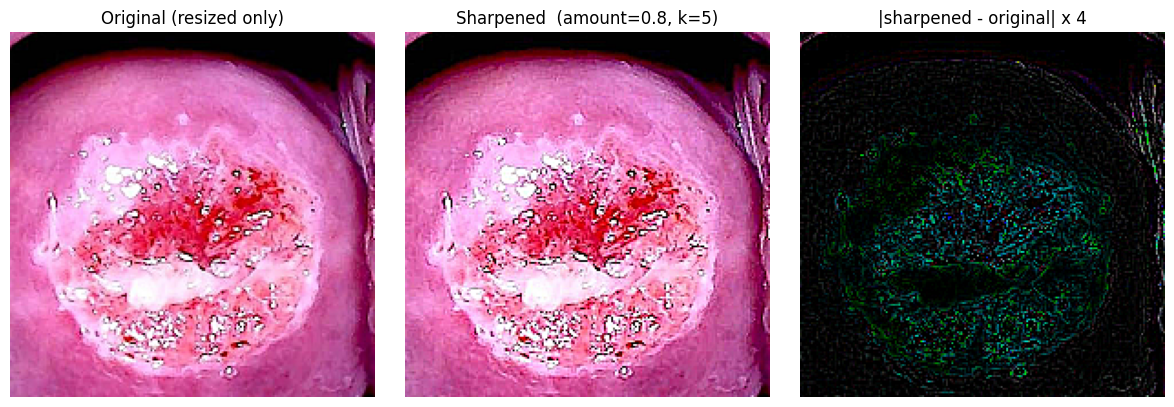

In [80]:
# ============================================================
# Cell 1.4 — Sharpen before/after visualisation
# ============================================================
def show_sharpen_effect(img_path=None, img_rgb=None):
    """Show original / sharpened / high-pass diff for a single image."""
    if img_rgb is None:
        raw_bgr = cv2.imread(img_path)
        if raw_bgr is None:
            print("Could not read", img_path); return
        raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
        raw_resized = cv2.resize(raw_rgb, (IMG_SIZE, IMG_SIZE))
    else:
        raw_resized = img_rgb
    sharpened = sharpen(raw_resized)
    diff = np.clip(sharpened.astype(np.int16) - raw_resized.astype(np.int16),
                   0, 255).astype(np.uint8)

    fig, ax = plt.subplots(1, 3, figsize=(12, 4))
    ax[0].imshow(raw_resized);    ax[0].set_title("Original (resized only)")
    ax[0].axis("off")
    ax[1].imshow(sharpened);      ax[1].set_title(
        f"Sharpened  (amount={SHARPEN_AMOUNT}, k={SHARPEN_KSIZE})")
    ax[1].axis("off")
    ax[2].imshow(diff * 4, cmap="gray")  # x4 to make the high-pass visible
    ax[2].set_title("|sharpened - original| x 4")
    ax[2].axis("off")
    plt.tight_layout(); plt.show()


if len(X_raw) > 0:
    # Use first sharpened image (X_raw is already sharpened) — rebuild
    # original = synthetic / dataset image before sharpen for comparison.
    show_sharpen_effect(img_rgb=X_raw[0])
else:
    demo = np.random.RandomState(SEED).randint(40, 200, (200, 200, 3), dtype=np.uint8)
    demo[60:140, 60:140] = np.random.RandomState(SEED+1).randint(160, 255, (80, 80, 3), dtype=np.uint8)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    ax[0].imshow(demo);               ax[0].set_title("Original");       ax[0].axis("off")
    ax[1].imshow(sharpen(demo));      ax[1].set_title("Sharpened");      ax[1].axis("off")
    plt.tight_layout(); plt.show()


In [81]:
# ============================================================
# Cell 2.1 -- Quantum-inspired fused saliency with vectorized Sobel (H1)
#             + FOV rim masking
# ============================================================
def _compute_fov_local(img_rgb, thr=15, fill_notches=True):
    """Local copy of the field-of-view mask (the validator in Part B has its
    own `compute_fov`). Returns the largest bright connected region of the
    image, holes filled.

    `fill_notches` (this round): the FOV mask has notches at the frame
    edges (black triangles at the right-middle of cluster 0, dark zigzag
    teeth at the bottom of clusters 1 and 3). Tissue inside these
    notches would be treated as outside the FOV and copied from the
    input at 4 bits. We fill the notches by taking the convex hull of
    the FOV mask, intersected with the original mask's bounding box
    (so the convex hull does not extend past the bright region). The
    convex hull is then morphologically closed (disk of 5 px) to
    smooth the zigzag teeth.

    Note: the convex hull can extend the FOV mask slightly past the
    bright region at the frame edges (e.g. into the dark corners).
    This is intentional -- the alternative (not filling the notches)
    leaves tissue inside the notches at 4 bits, which is worse than
    treating it as inside the FOV.
    """
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    if not fill_notches:
        return fov
    # Convex hull of the FOV mask, intersected with the bounding box of
    # the original mask. This fills notches at the frame edges (black
    # triangles, zigzag teeth) without extending the FOV past the
    # bright region.
    ys, xs = np.where(fov)
    if len(ys) < 3:
        return fov
    pts = np.stack([xs, ys], axis=1).astype(np.int32)
    hull = cv2.convexHull(pts)
    hull_mask = np.zeros(g.shape, dtype=np.uint8)
    cv2.fillConvexPoly(hull_mask, hull, 1)
    hull_mask = hull_mask.astype(bool)
    # Intersect the hull with the FOV mask's bounding box (so the hull
    # does not extend past the bright region in any direction).
    x0, x1 = int(xs.min()), int(xs.max())
    y0, y1 = int(ys.min()), int(ys.max())
    bbox = np.zeros(g.shape, dtype=bool)
    bbox[y0:y1+1, x0:x1+1] = True
    hull_mask = hull_mask & bbox
    # Morphologically close with a disk of 5 px to smooth the zigzag
    # teeth at the bottom of the frame.
    ksize = 11  # 2 * 5 + 1
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                  cv2.MORPH_CLOSE, kernel).astype(bool)
    # The final FOV is the union of the original (holes filled) and the
    # convex-hull-filled version. This keeps the original bright
    # region and adds the notch fills.
    return fov | hull_mask


def _fov_inner_mask(img_rgb, erode_iter=SALIENCY_RIM_ERODE):
    """FOV mask eroded by `erode_iter` pixels to remove the bright rim.
    The Sobel/contrast/entropy saliency channels respond to the FOV
    border; eroding the mask and ignoring the rim suppresses that
    spurious response.

    The erosion uses `border_value=1` so the margin applies only at the
    circular FOV rim, not at the rectangular frame edge. Without this,
    on a frame where the FOV extends to the image edge (e.g. clusters 1
    and 3 on this patient), the erosion would shrink the FOV from the
    frame edge and the rim margin would cut the lesion at the bottom of
    the frame.
    """
    fov = _compute_fov_local(img_rgb)
    if erode_iter and erode_iter > 0:
        fov = ndimage.binary_erosion(fov, iterations=int(erode_iter),
                                     border_value=1)
    return fov


def compute_sobel_gradients(image, tau=50, vectorized=True):
    """Sobel gradients + binary mask. v2 (H1): vectorized=True uses cv2.Sobel."""
    if vectorized and USE_VECTORIZED_SOBEL:
        img_f = image.astype(np.float32)
        gx = cv2.Sobel(img_f, cv2.CV_64F, 1, 0, ksize=3) / 8.0
        gy = cv2.Sobel(img_f, cv2.CV_64F, 0, 1, ksize=3) / 8.0
        G  = np.abs(gx) + np.abs(gy)
        mask = (G >= tau).astype(int)
        return gx, gy, G, mask
    h, w = image.shape
    padded = np.pad(image.astype(float), 1, mode='edge')
    gx = np.zeros_like(image, dtype=float)
    gy = np.zeros_like(image, dtype=float)
    for y in range(h):
        for x in range(w):
            py, px = y + 1, x + 1
            gx[y, x] = (-1 * padded[py-1, px-1] + 1 * padded[py-1, px+1]
                        - 2 * padded[py,   px-1] + 2 * padded[py,   px+1]
                        - 1 * padded[py+1, px-1] + 1 * padded[py+1, px+1]) / 8.0
            gy[y, x] = (-1 * padded[py-1, px-1] - 2 * padded[py-1, px] - 1 * padded[py-1, px+1]
                        + 1 * padded[py+1, px-1] + 2 * padded[py+1, px] + 1 * padded[py+1, px+1]) / 8.0
    G = np.abs(gx) + np.abs(gy)
    mask = (G >= tau).astype(int)
    return gx, gy, G, mask


def _spectral_residual_saliency(gray):
    """Spectral residual saliency (from SAHQR, reused here for fusion)."""
    f = fft2(gray); fs = fftshift(f)
    amp = np.abs(fs); phase = np.angle(fs)
    log_amp = np.log(amp + 1e-8)
    avg = gaussian_filter(log_amp, sigma=3.0)
    residual = log_amp - avg
    cr = np.exp(residual) * np.exp(1j * phase)
    s = np.abs(np.fft.ifft2(np.fft.ifftshift(cr))) ** 2
    s = (s - s.mean()) / (s.std() + 1e-8)
    s = np.clip(s, -3, 3)
    s = (s - s.min()) / (s.max() - s.min() + 1e-8)
    return s


def _multiscale_contrast_saliency(gray):
    """Multi-scale centre-surround contrast (sigma in {1,2,4,8})."""
    s_total = np.zeros_like(gray)
    for sd in (1, 2, 4, 8):
        local = gaussian_filter(gray, sigma=sd)
        s_total += ((gray - local) ** 2) / float(sd)
    p2, p98 = np.percentile(s_total, [2, 98])
    return np.clip((s_total - p2) / (p98 - p2 + 1e-8), 0, 1)


def _local_entropy_saliency(gray, blk=16):
    """16x16-block Shannon entropy."""
    ent = np.zeros_like(gray)
    H, W = gray.shape
    for i in range(0, H, blk):
        for j in range(0, W, blk):
            patch = gray[i:i+blk, j:j+blk].astype(np.uint8)
            if patch.size == 0: continue
            h = np.bincount(patch.ravel(), minlength=256).astype(np.float64)
            p = h / (h.sum() + 1e-8)
            p = p[p > 0]
            ent[i:i+blk, j:j+blk] = -np.sum(p * np.log2(p)) / 8.0
    return ent


def _glare_mask_local(img_rgb, dilate=None, v_thr=None, s_thr=None,
                       max_blob_frac=None, fov_mask=None):
    """Local glare detector, tightened so large acetowhite areas are not
    flagged as glare.

    Detector (this round): V > v_thr AND S < s_thr, then dilated by `dilate`
    px. After dilation, each connected component is kept only if its area is
    <= max_blob_frac * fov_area (rejects large acetowhite blobs that pass the
    V/S thresholds but are too big to be specular glare).

    Defaults are read from the module globals so the ablation toggle works.
    """
    if dilate is None:          dilate = GLARE_DILATE
    if v_thr is None:           v_thr = GLARE_V_THR
    if s_thr is None:           s_thr = GLARE_S_THR
    if max_blob_frac is None:   max_blob_frac = GLARE_MAX_BLOB_FRAC
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    m = ((hsv[..., 2] > v_thr) & (hsv[..., 1] < s_thr)).astype(np.uint8)
    if dilate and dilate > 0:
        m = cv2.dilate(m, np.ones((dilate, dilate), np.uint8))
    # Area filter: reject connected components larger than max_blob_frac of
    # the FOV area. Acetowhite epithelium is large; specular glare is small.
    if max_blob_frac and max_blob_frac > 0:
        if fov_mask is None:
            fov_area = float(m.size)
        else:
            fov_area = float(np.asarray(fov_mask, dtype=bool).sum())
            if fov_area <= 0:
                fov_area = float(m.size)
        max_area = max_blob_frac * fov_area
        n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        # st[0] is the background; skip it.
        for k in range(1, n):
            area = float(st[k, cv2.CC_STAT_AREA])
            if area > max_area:
                m[lab == k] = 0
    return m.astype(bool)


def _fill_glare_with_local_median(img_rgb, glare_mask, fov_mask):
    """Replace glare pixels with the local median inside the FOV.

    The local median is computed with a 7x7 footprint on each RGB channel.
    Outside the FOV we leave the pixel as-is (the saliency step ignores it
    anyway via the FOV mask). This is a robust fill that does not introduce
    a sharp edge at the glare boundary.
    """
    if not glare_mask.any():
        return img_rgb.copy()
    out = img_rgb.copy()
    for ch in range(3):
        chan = img_rgb[..., ch]
        fill_val = float(np.median(chan[fov_mask & ~glare_mask])) if (fov_mask & ~glare_mask).any() else 0.0
        chan_filled = chan.copy()
        chan_filled[glare_mask] = int(round(fill_val))
        med = cv2.medianBlur(chan_filled, 7)
        out[..., ch][glare_mask] = med[glare_mask]
    return out


def _normalise_saliency(s, fov_inner, mode="rank",
                        p_low=1, p_high=99.9):
    """Normalise the fused saliency map.

    Modes:
      "rank" (default): s_norm = rank(s) / N inside the eroded FOV mask.
        This is a CDF / rank transform: s_norm is uniformly distributed in
        [0, 1] inside the FOV, so the soft-mask threshold directly
        corresponds to a coverage fraction (thr = 0.55 -> 45% of pixels
        above the threshold). This removes the saturation problem -- the
        map is no longer dominated by a few bright outliers, and the
        threshold is a tunable coverage knob.

      "robust": s_norm = clip((s - p_lo) / (p_hi - p_lo), 0, 1) where
        p_lo / p_hi are the p_low / p_high percentiles of `s` inside the
        eroded FOV mask. More aggressive than min-max but still sensitive
        to the distribution shape; kept as an ablation.

      "minmax": s_norm = (s - s.min) / (s.max - s.min). The original
        behaviour; a single hot pixel can push the whole map to 0. Kept
        as an ablation.

    Outside the eroded FOV mask, the saliency is forced to 0 AFTER
    normalisation.
    """
    s = s.astype(np.float64)
    if fov_inner.any():
        s_in = s[fov_inner]
    else:
        s_in = s.ravel()
        fov_inner = np.ones_like(s, dtype=bool)
    if mode == "rank":
        # CDF / rank transform: rank each FOV pixel, divide by N.
        # Use scipy.stats.rankdata for tie handling (average rank).
        from scipy.stats import rankdata
        ranks = rankdata(s_in)  # 1..N
        n = float(len(s_in))
        cdf_in = ranks / n  # in (0, 1]
        s_norm = np.zeros_like(s, dtype=np.float64)
        s_norm[fov_inner] = cdf_in
    elif mode == "robust":
        lo = float(np.percentile(s_in, p_low))
        hi = float(np.percentile(s_in, p_high))
        denom = max(hi - lo, 1e-8)
        s_norm = np.clip((s - lo) / denom, 0.0, 1.0)
    else:  # minmax
        s_norm = (s - s_in.min()) / (s_in.max() - s_in.min() + 1e-8)
    s_norm[~fov_inner] = 0.0
    return s_norm.astype(np.float32)


def _whiteness_saliency(img_rgb, fov_mask, glare_mask=None):
    """Whiteness saliency channel: acetowhite epithelium is bright AND
    low-saturation AND not pure specular glare.

    The channel is computed as:
      whiteness = V * (1 - S/255)   in [0, 255]
    inside the FOV mask, EXCLUDING the dilated glare mask. The result is
    min-max normalised to [0, 1] inside the FOV. Outside the FOV it is 0.

    This channel captures the flat pale acetowhite blob that the
    texture/edge channels miss (the blob has low texture but high
    whiteness).
    """
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV).astype(np.float32)
    V = hsv[..., 2]
    S = hsv[..., 1]
    whiteness = V * (1.0 - S / 255.0)
    s = whiteness.copy()
    # Exclude glare pixels (they are already inpainted in the image, but
    # the raw HSV still has the original values; mask them out here too).
    if glare_mask is not None:
        s[glare_mask] = 0.0
    # Zero outside the FOV.
    s[~fov_mask] = 0.0
    # Min-max normalise inside the FOV.
    if fov_mask.any():
        s_in = s[fov_mask]
        lo, hi = float(s_in.min()), float(s_in.max())
        if hi - lo > 1e-8:
            s = np.clip((s - lo) / (hi - lo), 0.0, 1.0)
        else:
            s = np.zeros_like(s)
    s[~fov_mask] = 0.0
    return s.astype(np.float32)


def _fill_glare_holes_in_saliency(saliency, glare_mask, fov_mask):
    """Fill glare holes in the saliency map by normalised convolution.

    The glare fill on the IMAGE (median fill) can over-suppress: the median
    replaces the bright glare with a flat local value, so the Sobel /
    contrast channels see no edges there and the saliency drops to a
    hole. This function fills the hole directly in the SALIENCY map by
    computing a weighted average of the non-glare saliency in a 7x7
    neighbourhood (normalised convolution -- the weight is 1 inside the
    FOV and outside the glare mask, 0 inside the glare mask).

    This avoids the over-suppression caused by the image-space median fill
    while still keeping the glare from producing hot spots.
    """
    if glare_mask is None or not glare_mask.any():
        return saliency
    s = saliency.astype(np.float32).copy()
    gmask = np.asarray(glare_mask, dtype=bool)
    fmask = np.asarray(fov_mask, dtype=bool)
    # Valid pixels: inside FOV and not glare.
    valid = fmask & ~gmask
    # Weight: 1 where valid, 0 where glare or outside FOV.
    w = valid.astype(np.float32)
    # Box-filter the weighted saliency and the weights (7x7 box).
    ksize = 7
    sw = cv2.boxFilter(s * w, ddepth=cv2.CV_32F, ksize=(ksize, ksize),
                       borderType=cv2.BORDER_REFLECT)
    ww = cv2.boxFilter(w, ddepth=cv2.CV_32F, ksize=(ksize, ksize),
                       borderType=cv2.BORDER_REFLECT)
    # Normalised convolution: sw / ww where ww > 0.
    filled = np.where(ww > 1e-8, sw / np.maximum(ww, 1e-8), 0.0).astype(np.float32)
    # Paste the filled values where the glare mask is True (inside the FOV).
    paste = gmask & fmask
    s[paste] = filled[paste]
    return s


def qsahqr_plus_saliency(img_rgb, tau=None, sigma=None,
                         w_sobel=None, w_spectral=None,
                         w_contrast=None, w_entropy=None, w_whiteness=None,
                         fov_mask=None, seed=None,
                         use_glare_mask=None, use_whiteness=None,
                         normalize_mode=None,
                         p_low=None, p_high=None):
    """Quantum-inspired fused saliency (H1).

    Combines 5 channels (the 5th is optional):
      - Sobel gradient magnitude (vectorized via cv2.Sobel - H1)
      - Spectral residual (FFT log-amplitude residual)
      - Multi-scale contrast (centre-surround, sigma in {1,2,4,8})
      - Local entropy (16x16 block Shannon entropy)
      - Whiteness (V * (1 - S/255), excluding glare) -- captures flat pale
        acetowhite epithelium that the texture/edge channels miss.
        Disabled when USE_WHITENESS is False.

    Pipeline (in order):
      1. Compute / erode the FOV mask (SALIENCY_RIM_ERODE px).
      2. If USE_GLARE_MASK, detect glare (V > GLARE_V_THR, S < GLARE_S_THR,
         dilated, and only keeping blobs <= GLARE_MAX_BLOB_FRAC * FOV area)
         and fill those pixels with the local 7x7 median inside the FOV so
         the Sobel/contrast/entropy channels do not produce hot spots at the
         bright glare dots. The area filter rejects large acetowhite blobs.
      3. Replace outside-FOV-inner pixels with the interior mean so Sobel
         and contrast do not respond to the black border or the bright rim.
      4. Compute the saliency channels and fuse them.
      5. Gaussian-smooth the fused map.
      6. Zero the saliency outside the eroded FOV mask AFTER the Gaussian.
      7. Normalise: rank / CDF (default), robust percentile, or min-max.
      8. Re-zero outside the eroded FOV mask after normalisation.
      9. If USE_GLARE_MASK, fill glare holes in the SALIENCY map by normalised
         convolution (the image-space median fill can over-suppress; the
         saliency-space fill restores the local saliency level).
     10. Apply the FOV rim margin: zero the saliency within
         SALIENCY_RIM_MARGIN px of the FOV boundary. The rim-margin zeroing
         already removes anything touching the boundary, so no separate
         border-touching filter is needed.

    `seed` is accepted for API symmetry with the soft mask; the saliency
    channels are deterministic, so the seed is currently unused.
    """
    # Resolve module-level globals at CALL time, not at def time.
    if tau is None:           tau = SALIENCY_TAU
    if sigma is None:         sigma = SALIENCY_SIGMA
    if w_sobel is None:       w_sobel = SALIENCY_W_SOBEL
    if w_spectral is None:    w_spectral = SALIENCY_W_SPECTRAL
    if w_contrast is None:    w_contrast = SALIENCY_W_CONTRAST
    if w_entropy is None:     w_entropy = SALIENCY_W_ENTROPY
    if w_whiteness is None:   w_whiteness = SALIENCY_W_WHITENESS
    if use_glare_mask is None: use_glare_mask = USE_GLARE_MASK
    if use_whiteness is None: use_whiteness = USE_WHITENESS
    if normalize_mode is None: normalize_mode = SALIENCY_NORMALIZE
    if p_low is None:         p_low = SALIENCY_PCT_LOW
    if p_high is None:        p_high = SALIENCY_PCT_HIGH
    if seed is not None:
        np.random.seed(int(seed) & 0x7FFFFFFF)

    gray_orig = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.uint8)
    if fov_mask is None:
        fov_full = _compute_fov_local(img_rgb)
    else:
        fov_full = np.asarray(fov_mask, dtype=bool)
    # Erode the FOV mask to remove the bright rim. Use border_value=1 so
    # the erosion only shrinks the FOV at the circular rim, not at the
    # rectangular frame edge (clusters 1 and 3 have the FOV extending to
    # the bottom of the frame; without border_value=1 the rim margin would
    # cut the lesion at the bottom edge).
    if SALIENCY_RIM_ERODE and SALIENCY_RIM_ERODE > 0:
        fov_inner = ndimage.binary_erosion(fov_full, iterations=int(SALIENCY_RIM_ERODE),
                                           border_value=1)
    else:
        fov_inner = fov_full.copy()

    # (Step 2) Glare fill: replace glare pixels with the local median inside
    # the FOV so saliency channels do not respond to the bright dots.
    # Pass fov_mask so the area filter can reject large acetowhite blobs.
    glare_mask = None
    if use_glare_mask:
        glare_mask = _glare_mask_local(img_rgb, fov_mask=fov_full)
        if glare_mask.any():
            img_for_saliency = _fill_glare_with_local_median(img_rgb, glare_mask, fov_full)
            gray_orig = cv2.cvtColor(img_for_saliency, cv2.COLOR_RGB2GRAY).astype(np.uint8)

    # (Step 3) Replace outside-FOV-inner with the interior mean.
    fill_val = float(gray_orig[fov_inner].mean()) if fov_inner.any() else 0.0
    gray = gray_orig.copy()
    gray[~fov_inner] = int(round(fill_val))

    _, _, G, sobel_mask = compute_sobel_gradients(gray, tau=tau, vectorized=True)
    s_sobel = (G - G.min()) / (G.max() - G.min() + 1e-8)
    s_spec = _spectral_residual_saliency(gray.astype(np.float64))
    s_contr = _multiscale_contrast_saliency(gray.astype(np.float64))
    s_ent = _local_entropy_saliency(gray)
    s = (w_sobel * s_sobel + w_spectral * s_spec
         + w_contrast * s_contr + w_entropy * s_ent)
    # (Step 4b) Optional whiteness channel.
    if use_whiteness and w_whiteness > 0:
        s_white = _whiteness_saliency(img_rgb, fov_inner, glare_mask=glare_mask)
        # Normalise to [0,1] inside the FOV (the helper already does this).
        s = s + w_whiteness * s_white.astype(np.float64)
    # (Step 5) Gaussian smooth the fused map.
    s = gaussian_filter(s, sigma=sigma)
    # (Step 6) Zero outside the eroded FOV mask AFTER the Gaussian.
    s[~fov_inner] = 0.0
    # (Step 7 + 8) Normalise and re-zero.
    s = _normalise_saliency(s, fov_inner, mode=normalize_mode,
                             p_low=p_low, p_high=p_high)
    # (Step 9) Fill glare holes in the SALIENCY map by normalised convolution.
    # The image-space median fill can over-suppress (the median replaces the
    # bright glare with a flat value, so the Sobel/contrast channels see no
    # edges there). This step restores the local saliency level by averaging
    # the non-glare saliency in a 7x7 neighbourhood.
    if use_glare_mask and glare_mask is not None and glare_mask.any():
        s = _fill_glare_holes_in_saliency(s, glare_mask, fov_full)
    # (Step 10) FOV rim margin: zero within SALIENCY_RIM_MARGIN px of the FOV
    # boundary. The rim-margin zeroing already removes anything touching the
    # FOV boundary, so no separate border-touching filter is needed.
    # Use border_value=1 so the margin applies only at the circular FOV rim,
    # not at the rectangular frame edge (otherwise the rim margin would cut
    # the lesion at the bottom of the frame in clusters 1 and 3 where the FOV
    # extends to the image edge).
    if SALIENCY_RIM_MARGIN and SALIENCY_RIM_MARGIN > 0:
        fov_margin = ndimage.binary_erosion(fov_full, iterations=int(SALIENCY_RIM_MARGIN),
                                             border_value=1)
        s[~fov_margin] = 0.0
    return s.astype(np.float32), G, sobel_mask.astype(np.float32)


# Sanity check on first image
if len(X_raw) > 0:
    _fov0 = _compute_fov_local(X_raw[0])
    s_map, G, sobel_mask = qsahqr_plus_saliency(X_raw[0], fov_mask=_fov0)
    print(f"Fused saliency (FOV-rim eroded {SALIENCY_RIM_ERODE}px, "
          f"rim margin {SALIENCY_RIM_MARGIN}px, "
          f"glare-masked={USE_GLARE_MASK}, whiteness={USE_WHITENESS}, "
          f"normalise={SALIENCY_NORMALIZE}): "
          f"range=[{s_map.min():.3f}, {s_map.max():.3f}]  "
          f"mean={s_map.mean():.3f}  std={s_map.std():.3f}")
    print(f"  Sobel-only mask coverage (tau={SALIENCY_TAU}): "
          f"{100*sobel_mask.mean():.2f}%")
    # Glare detector report: the cell 6 ring baseline is the correct
    # comparison; this cell just reports the raw count. The old halo
    # message ("MUCH HIGHER than non-glare = under-suppression") was a
    # false alarm because it compared against all non-glare tissue
    # (including the dark periphery). The ring baseline in cell 6 is the
    # right comparison.
    _glare0 = _glare_mask_local(X_raw[0], fov_mask=_fov0)
    if _glare0.any():
        print(f"  Glare pixels (V>{GLARE_V_THR}, S<{GLARE_S_THR}, "
              f"blob<={GLARE_MAX_BLOB_FRAC*100:.0f}% FOV): "
              f"{100*_glare0.mean():.2f}% of frame")
        print(f"  (halo check is in cell 6 -- ring baseline, not whole-FOV)")
    else:
        print(f"  Glare pixels (V>{GLARE_V_THR}, S<{GLARE_S_THR}, "
              f"blob<={GLARE_MAX_BLOB_FRAC*100:.0f}% FOV): 0.00% of frame")


Fused saliency (FOV-rim eroded 5px, rim margin 10px, glare-masked=True, whiteness=False, normalise=rank): range=[0.000, 1.000]  mean=0.435  std=0.316
  Sobel-only mask coverage (tau=50): 5.33%
  Glare pixels (V>250, S<25, blob<=1% FOV): 5.08% of frame
  (halo check is in cell 6 -- ring baseline, not whole-FOV)


In [82]:
# ============================================================
# Cell 2.2 -- Soft mask (H7) + edge-aware continuous bit allocation (H3, B, E)
# ============================================================
def qsahqr_plus_soft_mask(saliency, gain=None, fixed_thr=None,
                          hard_thr=None, seed=None, use_saliency=None,
                          thr_mode=None, coverage=None, fov_mask=None):
    """Soft mask via sigmoid centred on a threshold.

    Two threshold modes (SOFT_MASK_THR_MODE):
      "fixed"     -- use SOFT_MASK_FIXED_THR for every image. With the CDF
                     normalisation, thr=0.55 -> 45% salient.
      "per_image" -- compute the threshold per image as the
                     (1 - SOFT_MASK_COVERAGE) percentile of the saliency
                     inside the (eroded, rim-margin) FOV mask, so coverage
                     is held constant across images. This equalises the
                     coverage across clusters (the per-cluster figure
                     showed clusters 1 and 3 were hotter toward the
                     periphery than the others).

    If `USE_SALIENCY` is False, returns an all-zero mask (every pixel is
    fully compressed; this is the saliency-ablation switch).

    `gain`, `fixed_thr`, `hard_thr`, `use_saliency`, `thr_mode`, `coverage`
    are read from the module globals at CALL time so the ablation toggles
    actually take effect.

    `seed` is accepted for API symmetry. The soft mask is deterministic in
    the current implementation; if a stochastic extension is added, it must
    honour this seed.
    """
    if gain is None:          gain = SOFT_MASK_GAIN
    if fixed_thr is None:     fixed_thr = SOFT_MASK_FIXED_THR
    if hard_thr is None:       hard_thr = HARD_MASK_THR
    if use_saliency is None:   use_saliency = USE_SALIENCY
    if thr_mode is None:       thr_mode = SOFT_MASK_THR_MODE
    if coverage is None:       coverage = SOFT_MASK_COVERAGE
    if seed is not None:
        np.random.seed(int(seed) & 0x7FFFFFFF)

    if not use_saliency:
        return np.zeros_like(saliency, dtype=np.float32)

    s = saliency.astype(np.float64)
    # Resolve the threshold.
    if thr_mode == "per_image":
        if fov_mask is not None:
            s_in = s[np.asarray(fov_mask, dtype=bool)]
        else:
            s_in = s.ravel()
        if len(s_in) == 0:
            mu = float(fixed_thr)
        else:
            # The (1 - coverage) percentile of the CDF gives the threshold
            # above which `coverage` of the pixels fall.
            mu = float(np.percentile(s_in, 100.0 * (1.0 - coverage)))
    else:  # "fixed"
        mu = float(fixed_thr)
    W = 1.0 / (1.0 + np.exp(-gain * (s - mu) * 255.0))
    return W.astype(np.float32)


def qsahqr_plus_bit_maps(soft_mask, sobel_G=None,
                         bits_sal_Y=None, bits_non_Y=None,
                         bits_sal_C=None, bits_non_C=None,
                         edge_boost_max=None, use_edge_boost=None,
                         bits_non_Y_min=None, fov_margin=None):
    """Per-pixel CONTINUOUS bit allocation with edge-aware boost (H3).

    Old Q-SAHQR used np.where(mask, 8.0, 4.0) -- binary.
    v1: linear interpolation between salient and non-salient bit budgets.
    v2 (H3): adds an extra 0..EDGE_BOOST_MAX bits/pixel at strong-edge pixels.
    `bits_non_Y_min`: optional luma floor (the non-salient luma bits are
    max(bits_non_Y, floor) so the periphery never goes below `floor` bits).

    `fov_margin` (this round): optional boolean mask of the rim-margin
    FOV (the FOV eroded by SALIENCY_RIM_MARGIN). Where `fov_margin` is
    False, the edge boost is zeroed. This removes the thin rectangular
    rim line at ~4.5 bits that appeared in every bit map because Sobel
    responds to the FOV border and the boost was applied there even
    though the soft mask W is 0 in the rim margin.
    """
    if bits_sal_Y is None:       bits_sal_Y = BITS_SALIENT_Y
    if bits_non_Y is None:       bits_non_Y = BITS_NONSALIENT_Y
    if bits_sal_C is None:       bits_sal_C = BITS_SALIENT_C
    if bits_non_C is None:       bits_non_C = BITS_NONSALIENT_C
    if edge_boost_max is None:    edge_boost_max = EDGE_BOOST_MAX
    if use_edge_boost is None:    use_edge_boost = USE_EDGE_BOOST
    if bits_non_Y_min is None:    bits_non_Y_min = BITS_NONSALIENT_Y_MIN

    # Apply the optional luma floor.
    eff_bits_non_Y = max(bits_non_Y, bits_non_Y_min) if bits_non_Y_min else bits_non_Y

    W = soft_mask.astype(np.float32)
    bit_Y = (bits_sal_Y * W + eff_bits_non_Y * (1.0 - W)).astype(np.float32)
    bit_C = (bits_sal_C * W + bits_non_C * (1.0 - W)).astype(np.float32)

    if use_edge_boost and sobel_G is not None and edge_boost_max > 0:
        Gn = sobel_G.astype(np.float32)
        p2, p98 = np.percentile(Gn, [2, 98])
        Gn = np.clip((Gn - p2) / (p98 - p2 + 1e-8), 0, 1)
        boost = edge_boost_max * (1.0 / (1.0 + np.exp(-12.0 * (Gn - 0.5))))
        # Zero the edge boost inside the rim margin / outside the FOV.
        # The Sobel response at the FOV border would otherwise create a
        # thin rectangular rim line at ~4.5 bits in every bit map (the
        # soft mask W is 0 there, so the base bit_Y is 4, and the boost
        # adds ~0.5). Zeroing the boost where `fov_margin` is False
        # removes the rim line. Outside the FOV the bit map is not used
        # (the pipeline copies the original pixels there), so zeroing
        # there too is harmless.
        if fov_margin is not None:
            fov_m = np.asarray(fov_margin, dtype=bool)
            if fov_m.shape == boost.shape:
                boost = np.where(fov_m, boost, 0.0).astype(np.float32)
        bit_Y = np.clip(bit_Y + boost, 1.0, 8.0).astype(np.float32)
        bit_C = np.clip(bit_C + boost * (1.0/3.0), 1.0, 8.0).astype(np.float32)

    return bit_Y, bit_C


def qsahqr_plus_hard_mask_filled(soft_mask, hard_thr=None, fov_mask=None,
                                  close_radius=None, max_fill_frac=None,
                                  use_fill=None):
    """Hard mask (W >= hard_thr) with optional hole filling.

    The hard mask is closed (dilation then erosion with a disk of
    `close_radius` px) and holes are filled (scipy.ndimage.binary_fill_holes).
    Filled connected components larger than `max_fill_frac` of the FOV area
    are rejected so the fill does not swallow the whole frame.

    The rim/centre rule (dropping speculum wedges) is applied in
    qsahqr_plus_compute_mask, not here.

    The filled hard mask is used both for the figure/evaluation AND for
    the soft-mask fill (see qsahqr_plus_apply_fill_to_W).
    """
    if hard_thr is None:        hard_thr = HARD_MASK_THR
    if close_radius is None:    close_radius = HARD_MASK_CLOSE_RADIUS
    if max_fill_frac is None:   max_fill_frac = HARD_MASK_MAX_FILL_FRAC
    if use_fill is None:         use_fill = USE_HARD_MASK_FILL

    hard = (soft_mask >= hard_thr)
    if not use_fill:
        return hard.astype(np.float32)
    # Morphological closing: dilation then erosion with a disk.
    if close_radius and close_radius > 0:
        ksize = 2 * int(close_radius) + 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hard_u8 = hard.astype(np.uint8)
        closed = cv2.morphologyEx(hard_u8, cv2.MORPH_CLOSE, kernel)
        hard = closed.astype(bool)
    # Fill holes.
    filled = ndimage.binary_fill_holes(hard)
    # Reject filled components larger than max_fill_frac of the FOV area.
    if max_fill_frac and max_fill_frac > 0 and fov_mask is not None:
        fov_area = float(np.asarray(fov_mask, dtype=bool).sum())
        if fov_area > 0:
            max_area = max_fill_frac * fov_area
            n, lab, st, _ = cv2.connectedComponentsWithStats(filled.astype(np.uint8),
                                                              connectivity=8)
            for k in range(1, n):
                if float(st[k, cv2.CC_STAT_AREA]) > max_area:
                    filled[lab == k] = False
    return filled.astype(np.float32)


def _drop_small_components(binary_mask, min_area):
    """Drop connected components smaller than `min_area` px^2."""
    if not binary_mask.any():
        return binary_mask
    n, lab, st, _ = cv2.connectedComponentsWithStats(binary_mask.astype(np.uint8),
                                                      connectivity=8)
    out = binary_mask.copy()
    for k in range(1, n):
        if float(st[k, cv2.CC_STAT_AREA]) < min_area:
            out[lab == k] = False
    return out


def qsahqr_plus_apply_fill_to_W(soft_mask, hard_filled, fov_mask=None,
                                  fill_blur_sigma=4.0):
    """Apply the hole fill to the actual soft mask W.

    W_out = max(W, blur(filled_hard)) for filled regions. This protects the
    lesion core: where the soft mask W dips below hard_thr (e.g. at the flat
    pale acetowhite blob), the filled hard mask is 1, so the blurred filled
    mask lifts W back up. The blur softens the edge of the fill so it does
    not create a hard step in the bit map.

    The coverage AFTER this fill will be higher than the per_image target
    (45%). The per_image threshold should be set so the FINAL coverage
    (after fill) is the desired value -- see the pipeline in cell 10.
    """
    if hard_filled is None or not hard_filled.any():
        return soft_mask
    filled_blurred = gaussian_filter(hard_filled.astype(np.float32),
                                      sigma=fill_blur_sigma)
    W_out = np.maximum(soft_mask, filled_blurred).astype(np.float32)
    if fov_mask is not None:
        W_out[~np.asarray(fov_mask, dtype=bool)] = 0.0
    return W_out


def _apply_rim_centre_rule(W, fov_mask, hard_thr,
                            dilate_px=6, rim_margin_px=None,
                            main_keep_frac=0.30,
                            min_isolated_area=0,
                            return_dropped=False):
    """Drop salient connected components that touch the FOV rim margin OR
    the rectangular frame edge, EXCEPT the main (largest) component and
    any component at least `main_keep_frac` of the main's area. Also
    drop isolated small components (not connected to the main salient
    region) smaller than `min_isolated_area` px.

    Main-component rule (this round, replacing the old 5%-of-FOV area
    guard): a connected component of (W >= hard_thr) is dropped by the
    rim rule if it touches the rim band or the frame edge AND its area
    is < `main_keep_frac` * (main component area). The main component
    (the largest) is NEVER dropped. A component at least 30% of the
    main's area is also kept (this protects a real lesion that's
    comparable in size to the main region). The rule scales with the
    lesion size, so it's robust to convex-hull-induced edge strip
    enlargement (the old 5%-of-FOV guard was fragile: cluster 6's wedge
    at 4.77% was close to the 5% limit).

    Min-area filter: a component is dropped by 'min_area' if it is NOT
    the main component, its area is < `min_isolated_area` px, AND it
    does NOT touch or sit within `dilate_px` of the main region (to
    avoid punching 4-bit holes at the lesion edge). The min-area drop is
    NOT dilated (dilation would carve a 4-bit hole into the main
    region when a tiny blob sits next to it).

    Dilation: only rim drops are dilated by `dilate_px` (so no hollow
    crescent outline is left behind). Min-area drops are zeroed without
    dilation (the tiny blob disappears cleanly).

    Diagnostic (this round): `centre_frac` is replaced by
    `boundary_dist_frac` = distance from the component centroid to the
    nearest FOV boundary pixel, normalised by the distance from the FOV
    centroid to the nearest FOV boundary. A component at the rim has
    boundary_dist_frac ~0; a component at the centre has
    boundary_dist_frac ~1. This is more meaningful than the old
    radius-percentage (which went above 100% because the FOV is clipped
    by the frame and is not a circle).

    If `return_dropped=True`, also return a dict with:
      - `dropped_area_frac`: area of the largest dropped component as a
        fraction of FOV.
      - `dropped_boundary_frac`: boundary_dist_frac of the largest
        dropped component.
      - `n_dropped`: total number of dropped components.
      - `dropped_list`: list of dicts, one per dropped component, with
        keys: `area` (px), `area_frac` (of FOV), `boundary_dist_frac`,
        `touches_frame` (bool), `touches_rim` (bool), `reason` ('rim'
        or 'min_area').

    NOTE: `dilate_px`, `main_keep_frac` and `min_isolated_area` were
    chosen AFTER viewing this patient (in-sample). Before relying on
    this rule on a new patient, inspect the per-cluster
    "dropped-component list" printed by cell 6.
    """
    binary = (W >= hard_thr).astype(np.uint8)
    if binary.sum() == 0:
        if return_dropped:
            return W, dict(dropped_area_frac=0.0, dropped_boundary_frac=0.0,
                            n_dropped=0, dropped_list=[])
        return W
    fov_bool = np.asarray(fov_mask, dtype=bool)
    if not fov_bool.any():
        if return_dropped:
            return W, dict(dropped_area_frac=0.0, dropped_boundary_frac=0.0,
                            n_dropped=0, dropped_list=[])
        return W
    # Rim margin band: FOV minus eroded-by-margin FOV. Components that
    # touch this band are "at the rim". Use border_value=1 so the band
    # is only at the circular FOV rim, not at the rectangular frame edge.
    if rim_margin_px and rim_margin_px > 0:
        fov_inner = ndimage.binary_erosion(fov_bool, iterations=int(rim_margin_px),
                                           border_value=1)
    else:
        fov_inner = fov_bool.copy()
    rim_band = fov_bool & ~fov_inner
    # Frame-edge mask: any pixel on row 0, row H-1, col 0, or col W-1.
    H, Wd = binary.shape
    frame_edge = np.zeros_like(binary, dtype=bool)
    frame_edge[0, :] = True
    frame_edge[-1, :] = True
    frame_edge[:, 0] = True
    frame_edge[:, -1] = True
    # FOV boundary mask (for the distance-to-boundary diagnostic).
    # The boundary is the set of FOV pixels that have at least one
    # non-FOV neighbour (4-connectivity).
    fov_boundary = np.zeros_like(fov_bool, dtype=bool)
    fov_boundary[1:, :] |= ~fov_bool[:-1, :]
    fov_boundary[:-1, :] |= ~fov_bool[1:, :]
    fov_boundary[:, 1:] |= ~fov_bool[:, :-1]
    fov_boundary[:, :-1] |= ~fov_bool[:, 1:]
    fov_boundary &= fov_bool
    # FOV centroid.
    ys_fov, xs_fov = np.where(fov_bool)
    cy_fov, cx_fov = float(ys_fov.mean()), float(xs_fov.mean())
    # FOV centroid's distance to the nearest FOV boundary pixel (used
    # to normalise the per-component boundary distance).
    if fov_boundary.any():
        ys_b, xs_b = np.where(fov_boundary)
        dist_centre_to_boundary = float(np.min(
            np.sqrt((ys_b - cy_fov) ** 2 + (xs_b - cx_fov) ** 2)))
    else:
        dist_centre_to_boundary = float(np.sqrt(fov_bool.sum() / np.pi))
    # Label the binary mask.
    n, lab, st, centroids = cv2.connectedComponentsWithStats(binary, connectivity=8)
    # Build a dilation kernel for rim drops.
    if dilate_px and dilate_px > 0:
        ksize = 2 * int(dilate_px) + 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    else:
        kernel = None
    # Find the largest salient component (the "main region"). It is
    # never dropped, and any component at least main_keep_frac of its
    # area is also kept by the rim rule (but can still be dropped by
    # the min-area filter if it's tiny).
    if n > 1:
        areas = st[1:, cv2.CC_STAT_AREA]
        main_k = 1 + int(np.argmax(areas))
        main_area = float(st[main_k, cv2.CC_STAT_AREA])
    else:
        main_k = -1
        main_area = 0.0
    keep_area = main_keep_frac * main_area if (main_keep_frac and main_keep_frac > 0) else 0.0
    # Main region mask (dilated by dilate_px) -- min-area drops that
    # touch this mask are skipped (to avoid punching 4-bit holes at the
    # lesion edge).
    if main_k > 0 and kernel is not None:
        main_mask = (lab == main_k).astype(np.uint8)
        main_mask_dil = cv2.dilate(main_mask, kernel)
    elif main_k > 0:
        main_mask_dil = (lab == main_k)
    else:
        main_mask_dil = np.zeros_like(binary, dtype=bool)
    out = W.copy()
    fov_area = float(fov_bool.sum())
    largest_dropped_area = 0.0
    largest_dropped_boundary = 0.0
    n_dropped = 0
    dropped_list = []
    # Two drop masks: rim drops (dilated) and min-area drops (not
    # dilated). Dilation is applied only to rim drops.
    rim_drop_mask = np.zeros_like(binary, dtype=np.uint8)
    min_area_drop_mask = np.zeros_like(binary, dtype=np.uint8)
    for k in range(1, n):
        comp = (lab == k)
        area = float(st[k, cv2.CC_STAT_AREA])
        cx_k, cy_k = float(centroids[k, 0]), float(centroids[k, 1])
        # Distance from this component's centroid to the nearest FOV
        # boundary pixel, normalised by the FOV centroid's distance to
        # the nearest boundary. A component at the rim has
        # boundary_dist_frac ~0; a component at the centre has ~1.
        if fov_boundary.any():
            dist_k_to_boundary = float(np.min(
                np.sqrt((ys_b - cy_k) ** 2 + (xs_b - cx_k) ** 2)))
        else:
            dist_k_to_boundary = 0.0
        boundary_dist_frac = dist_k_to_boundary / max(dist_centre_to_boundary, 1e-8)
        touches_rim = bool((comp & rim_band).any())
        touches_frame = bool((comp & frame_edge).any())
        # Try the rim rule first: drop if touches rim/frame AND area
        # < main_keep_frac * main_area (the main-component rule). The
        # main component itself is never dropped.
        drop_reason = None
        if k != main_k and area < keep_area and (touches_rim or touches_frame):
            drop_reason = 'rim'
        # Then the min-area filter: drop if NOT main, area <
        # min_isolated_area, AND does NOT touch/sit within dilate_px of
        # the main region.
        if drop_reason is None and min_isolated_area and min_isolated_area > 0:
            if k != main_k and area < min_isolated_area:
                # Skip if the component touches or sits within
                # dilate_px of the main region (would punch a 4-bit
                # hole at the lesion edge).
                if not (comp & main_mask_dil).any():
                    drop_reason = 'min_area'
        if drop_reason is None:
            continue
        # Accumulate into the appropriate drop mask.
        if drop_reason == 'rim':
            rim_drop_mask[comp] = 1
        else:
            min_area_drop_mask[comp] = 1
        n_dropped += 1
        # Track the largest dropped component for the diagnostic.
        if area > largest_dropped_area:
            largest_dropped_area = area
            largest_dropped_boundary = boundary_dist_frac
        # Per-component list for the diagnostic.
        dropped_list.append(dict(
            area=area,
            area_frac=area / max(fov_area, 1.0),
            boundary_dist_frac=boundary_dist_frac,
            touches_frame=touches_frame,
            touches_rim=touches_rim,
            reason=drop_reason,
        ))
    # Dilate the RIM drop mask once and zero those pixels in W. The
    # min-area drop mask is zeroed WITHOUT dilation (dilation would
    # carve a 4-bit hole into the main region when a tiny blob sits
    # next to it).
    if n_dropped > 0:
        if kernel is not None and rim_drop_mask.any():
            rim_drop_mask = cv2.dilate(rim_drop_mask, kernel)
        out[rim_drop_mask > 0] = 0.0
        out[min_area_drop_mask > 0] = 0.0
    if return_dropped:
        diag = dict(
            dropped_area_frac=largest_dropped_area / max(fov_area, 1.0),
            dropped_boundary_frac=largest_dropped_boundary,
            n_dropped=n_dropped,
            dropped_list=dropped_list,
        )
        return out, diag
    return out


def qsahqr_plus_compute_mask(s_map, G, fov_mask, fov_margin,
                              coverage_target=None,
                              use_hard_mask_fill=None,
                              hard_mask_close_radius=None,
                              hard_mask_max_fill_frac=None,
                              hard_mask_thr=None,
                              soft_mask_gain=None,
                              rim_margin_px=None,
                              rim_dilate_px=None,
                              main_keep_frac=None,
                              min_isolated_area=None,
                              return_dropped=False):
    """Single mask path used by cell 6, cell 9, the figures, and the sweep.

    Solves for the pre-fill coverage so the FINAL coverage (after the
    hard-mask fill is applied to W) is `coverage_target` (within +/-1.5%
    tolerance). This replaces the hard-coded 0.17 offset: we binary-search
    the pre-fill coverage so the post-fill coverage hits the target.

    The binary search is capped at 8 iterations. The fill + rim rule
    make the search non-monotone (the rim rule can drop a large
    component, causing the final coverage to jump down), so we accept a
    tolerance of 1.5% rather than exact convergence. 8 iterations is
    enough to get within 1.5% on this patient; the cap keeps the
    per-call cost predictable (~8 mask computations per image).

    The rim rule drops any salient connected component that (a) touches
    the FOV rim margin OR the rectangular frame edge AND (b) is smaller
    than `main_keep_frac` * (main component area) (default 30%). The
    main component (the largest) is NEVER dropped; any component at
    least 30% of the main's area is also kept. The min_isolated_area
    filter additionally drops isolated small components (not connected
    to the main salient region) smaller than `min_isolated_area` px
    (default 30), skipping those that touch or sit within
    `rim_dilate_px` of the main region (to avoid punching 4-bit holes
    at the lesion edge). See `_apply_rim_centre_rule` for details.

    After the rim rule, W is zeroed in the rim margin (outside
    `fov_margin`). This prevents the hard-mask fill (close radius 12 px)
    from pushing the salient region into the rim margin -- on this
    patient the 8-bit region was running to the bottom edge of the frame
    in clusters 1 and 3 because the fill extended the hard mask past the
    10 px rim margin. Zeroing W in the rim margin confines the salient
    region to the fov_margin.

    Returns dict with: soft_mask (final W), hard_mask, hard_mask_filled,
    bit_Y, bit_C, pre_fill_coverage, final_coverage, mean_bits_y.
    If `return_dropped=True`, also returns 'rim_dropped' (the full
    dropped-component diagnostic; used by the cell 6 off-centre lesion
    check and the per-cluster dropped-component list).
    """
    if coverage_target is None:       coverage_target = SOFT_MASK_COVERAGE
    if use_hard_mask_fill is None:     use_hard_mask_fill = USE_HARD_MASK_FILL
    if hard_mask_close_radius is None: hard_mask_close_radius = HARD_MASK_CLOSE_RADIUS
    if hard_mask_max_fill_frac is None: hard_mask_max_fill_frac = HARD_MASK_MAX_FILL_FRAC
    if hard_mask_thr is None:          hard_mask_thr = HARD_MASK_THR
    if soft_mask_gain is None:         soft_mask_gain = SOFT_MASK_GAIN
    if rim_margin_px is None:           rim_margin_px = SALIENCY_RIM_MARGIN
    if rim_dilate_px is None:           rim_dilate_px = RIM_DILATE_PX
    if main_keep_frac is None:          main_keep_frac = MAIN_COMPONENT_KEEP_FRAC
    if min_isolated_area is None:        min_isolated_area = MIN_SALIENT_AREA

    # Binary search for the pre-fill coverage so the post-fill coverage
    # is the target. The fill raises coverage, so the pre-fill target is
    # always <= the final target.
    def _final_coverage_for_pre(pre_cov):
        W = qsahqr_plus_soft_mask(s_map, fov_mask=fov_margin,
                                   coverage=pre_cov, gain=soft_mask_gain)
        if use_hard_mask_fill:
            hf = qsahqr_plus_hard_mask_filled(W, fov_mask=fov_mask,
                                               close_radius=hard_mask_close_radius,
                                               max_fill_frac=hard_mask_max_fill_frac,
                                               hard_thr=hard_mask_thr)
            if hf.any():
                W = qsahqr_plus_apply_fill_to_W(W, hf, fov_mask=fov_mask)
        # Apply the rim rule (main-component keep) + min-area filter.
        W = _apply_rim_centre_rule(W, fov_mask, hard_mask_thr,
                                    dilate_px=rim_dilate_px,
                                    rim_margin_px=rim_margin_px,
                                    main_keep_frac=main_keep_frac,
                                    min_isolated_area=min_isolated_area)
        # Zero W in the rim margin (outside fov_margin) so the fill doesn't
        # extend the salient region into the rim margin (which would put
        # the 8-bit region at the frame edge in some clusters).
        W[~fov_margin] = 0.0
        return float((W >= hard_mask_thr)[fov_margin].mean())

    if not use_hard_mask_fill:
        # No fill: pre = final directly (the rim rule still runs).
        pre_cov = coverage_target
    else:
        # Binary search with tolerance: find pre_cov so the final coverage
        # is within _tol of coverage_target. The fill + rim rule make the
        # search non-monotone (the rim rule can drop a large component,
        # causing the final coverage to jump down), so we accept a
        # tolerance of 1.5% rather than exact convergence. The search is
        # capped at 8 iterations: 8 is enough to get within 1.5% on this
        # patient and keeps the per-call cost predictable.
        _tol = 0.015
        _max_iter = 8
        lo, hi = 0.05, coverage_target
        best_pre, best_err = coverage_target, 1.0
        for _ in range(_max_iter):
            mid = 0.5 * (lo + hi)
            fc = _final_coverage_for_pre(mid)
            err = abs(fc - coverage_target)
            if err < best_err:
                best_err = err
                best_pre = mid
            if err < _tol:
                break
            if fc < coverage_target:
                lo = mid
            else:
                hi = mid
        pre_cov = best_pre

    # Compute the final W with the solved pre-fill coverage.
    W = qsahqr_plus_soft_mask(s_map, fov_mask=fov_margin,
                               coverage=pre_cov, gain=soft_mask_gain)
    hard_m = (W >= hard_mask_thr).astype(np.float32)
    if use_hard_mask_fill:
        hard_m_filled = qsahqr_plus_hard_mask_filled(W, fov_mask=fov_mask,
                                                      close_radius=hard_mask_close_radius,
                                                      max_fill_frac=hard_mask_max_fill_frac,
                                                      hard_thr=hard_mask_thr)
        if hard_m_filled.any():
            W = qsahqr_plus_apply_fill_to_W(W, hard_m_filled, fov_mask=fov_mask)
    else:
        hard_m_filled = hard_m.copy()
    # Apply the rim rule + min-area filter. Capture the per-component
    # dropped diagnostic if requested (used by the cell 6 off-centre
    # lesion check and the per-cluster dropped-component list).
    if return_dropped:
        W, rim_diag = _apply_rim_centre_rule(W, fov_mask, hard_mask_thr,
                                              dilate_px=rim_dilate_px,
                                              rim_margin_px=rim_margin_px,
                                              main_keep_frac=main_keep_frac,
                                              min_isolated_area=min_isolated_area,
                                              return_dropped=True)
    else:
        W = _apply_rim_centre_rule(W, fov_mask, hard_mask_thr,
                                    dilate_px=rim_dilate_px,
                                    rim_margin_px=rim_margin_px,
                                    main_keep_frac=main_keep_frac,
                                    min_isolated_area=min_isolated_area)
        rim_diag = None
    # Zero W in the rim margin (outside fov_margin) so the fill doesn't
    # extend the salient region into the rim margin (which would put the
    # 8-bit region at the frame edge in some clusters). This confines
    # the salient region to the fov_margin.
    W[~fov_margin] = 0.0
    # Recompute hard_m from the final W.
    hard_m = (W >= hard_mask_thr).astype(np.float32)
    # Pass fov_margin to bit_maps so the edge boost is zeroed inside the
    # rim margin (removes the thin rectangular rim line at ~4.5 bits).
    bit_Y, bit_C = qsahqr_plus_bit_maps(W, sobel_G=G, fov_margin=fov_margin)
    final_cov = float((W >= hard_mask_thr)[fov_margin].mean())
    mean_bits_y = float(bit_Y[fov_margin].mean()) if fov_margin.any() else float('nan')
    out = dict(
        soft_mask=W, hard_mask=hard_m, hard_mask_filled=hard_m_filled,
        bit_Y=bit_Y, bit_C=bit_C,
        pre_fill_coverage=pre_cov, final_coverage=final_cov,
        mean_bits_y=mean_bits_y,
    )
    if return_dropped:
        out['rim_dropped'] = rim_diag
    return out


# Sanity check
if len(X_raw) > 0:
    fov0 = _compute_fov_local(X_raw[0])
    fov_margin0 = ndimage.binary_erosion(fov0, iterations=int(SALIENCY_RIM_MARGIN),
                                          border_value=1) if SALIENCY_RIM_MARGIN > 0 else fov0.copy()
    s_map, G, _ = qsahqr_plus_saliency(X_raw[0], fov_mask=fov0)
    # ---- SINGLE MASK PATH: use qsahqr_plus_compute_mask (same as the pipeline) ----
    _mask0 = qsahqr_plus_compute_mask(s_map, G, fov0, fov_margin0)
    W = _mask0['soft_mask']
    bit_Y = _mask0['bit_Y']
    bit_C = _mask0['bit_C']
    hard_m = _mask0['hard_mask']
    hard_filled = _mask0['hard_mask_filled']
    # Mask-quality line: transition band, glare-overlap (ring baseline),
    # mean bits/px, coverage (final, after fill).
    trans_band = float(((W >= 0.2) & (W <= 0.8) & fov_margin0).sum()) / max(int(fov_margin0.sum()), 1)
    glare0 = _glare_mask_local(X_raw[0], fov_mask=fov0)
    if (W >= 0.5).any() and glare0.any():
        # Glare-overlap denominator: the number of pixels with W >= 0.5
        # (the salient set). The fraction is (salient AND glare) / salient.
        glare_overlap_w = float(((W >= 0.5) & glare0).sum()) / float((W >= 0.5).sum())
    else:
        glare_overlap_w = float('nan')
    # ---- Halo comparison against a RING baseline (this round) ----
    # Compare glare pixels against non-glare pixels WITHIN ~15px of the
    # glare region (a ring), not against all non-glare tissue (which
    # includes the dark periphery and makes the glare look hot by
    # comparison). The glare fill copies their neighbours' saliency, so
    # glare pixels are hot by construction; the ring baseline checks
    # whether the fill is doing a reasonable job.
    if glare0.any():
        # Dilate the glare mask by 15px to get a ring around it.
        _glare_dilated = cv2.dilate(glare0.astype(np.uint8),
                                     np.ones((15, 15), np.uint8)).astype(bool)
        _ring = _glare_dilated & ~glare0 & fov0
        if _ring.any():
            _glare_salient = float((W[glare0 & fov0] >= 0.5).mean())
            _ring_salient = float((W[_ring] >= 0.5).mean())
        else:
            _glare_salient = float('nan')
            _ring_salient = float('nan')
    else:
        _glare_salient = float('nan')
        _ring_salient = float('nan')
    mean_bits_y = float(bit_Y[fov_margin0].mean())
    mean_bits_c = float(bit_C[fov_margin0].mean())
    coverage = float((W >= HARD_MASK_THR)[fov_margin0].mean())
    coverage_filled = float(hard_filled[fov_margin0].mean())
    print(f"MASK QUALITY (single mask path, same as pipeline):")
    print(f"  pre_fill_coverage = {_mask0['pre_fill_coverage']:.3f}  "
          f"final_coverage = {_mask0['final_coverage']:.3f}  "
          f"(target = {SOFT_MASK_COVERAGE:.2f})")
    print(f"  mean W = {W.mean():.4f}  std = {W.std():.4f}")
    print(f"  coverage (W >= {HARD_MASK_THR}) [final, after fill] = {100*coverage:.2f}%")
    print(f"  transition-band fraction (0.2 <= W <= 0.8) = {100*trans_band:.2f}%  "
          f"(target < ~20%)")
    print(f"  glare-overlap = (W>=0.5 AND glare) / (W>=0.5) = {100*glare_overlap_w:.2f}%  "
          f"(denominator = salient pixel count)")
    print(f"  halo check (RING baseline): W>=0.5 on glare = {100*_glare_salient:.1f}% vs "
          f"ring (15px) = {100*_ring_salient:.1f}%  "
          f"(glare is hot by construction -- the fill copies neighbours)")
    print(f"  mean bits/px Y (inside rim-margin FOV) = {mean_bits_y:.3f}   "
          f"C (inside rim-margin FOV) = {mean_bits_c:.3f}")
    print(f"bit_map_Y (H3 edge-boost): mean (whole frame)={bit_Y.mean():.3f} bits/px  "
          f"std={bit_Y.std():.3f}  range=[{bit_Y.min():.2f}, {bit_Y.max():.2f}]  "
          f"(whole-frame mean is lower because outside-FOV pixels are 4 bits)")
    print(f"bit_map_C:                  mean (whole frame)={bit_C.mean():.3f} bits/px  "
          f"std={bit_C.std():.3f}  range=[{bit_C.min():.2f}, {bit_C.max():.2f}]")

    # ---- Mask-vs-ellipse IoU (this round) ----
    # A centred ellipse (aspect 1.4:1, wider than tall -- typical cervix
    # orientation) with the SAME coverage as the final hard mask. If the
    # IoU is very high (close to 1), the mask is mostly "the middle of the
    # image" and the saliency map is not adding spatial information beyond
    # a centred shape. If the IoU is low, the saliency map is shaping the
    # mask away from a simple ellipse.
    _hard = (W >= HARD_MASK_THR)
    _coverage = float(_hard[fov0].mean()) if fov0.any() else 0.0
    _yy, _xx = np.mgrid[:X_raw[0].shape[0], :X_raw[0].shape[1]]
    _ys_fov, _xs_fov = np.where(fov0)
    _cy, _cx = float(_ys_fov.mean()), float(_xs_fov.mean())
    _aspect = 1.4
    _b_ell = np.sqrt(_coverage * fov0.sum() / (_aspect * np.pi)) if (_aspect * np.pi) > 0 else 0.0
    _a_ell = _aspect * _b_ell
    _ellipse = (fov0 & (((_xx - _cx) ** 2) / max(_a_ell ** 2, 1e-8) +
                        ((_yy - _cy) ** 2) / max(_b_ell ** 2, 1e-8) <= 1))
    _inter = float((_hard & _ellipse).sum())
    _union = float((_hard | _ellipse).sum())
    _ellipse_iou = _inter / _union if _union > 0 else float('nan')
    print(f"  mask-vs-ellipse IoU (final hard mask vs centred ellipse, same coverage) = {_ellipse_iou:.3f}  "
          f"(high = mask is mostly 'the middle of the image'; low = saliency shapes the mask)")

    # ---- Per-cluster mask-quality line (uses the SAME single mask path) ----
    print()
    print("  PER-CLUSTER MASK QUALITY  (single mask path, W >= 0.5 inside rim-margin FOV):")
    _hs = []
    for _im in X_raw:
        _g = cv2.resize(cv2.cvtColor(_im, cv2.COLOR_RGB2GRAY), (9, 8),
                        interpolation=cv2.INTER_AREA).astype(np.int16)
        _hs.append((_g[:, 1:] > _g[:, :-1]).ravel())
    _cids = np.full(len(_hs), -1, dtype=int)
    _next = 0
    for _i, _h in enumerate(_hs):
        if _cids[_i] >= 0: continue
        _cids[_i] = _next
        for _j in range(_i + 1, len(_hs)):
            if _cids[_j] < 0 and (_h != _hs[_j]).sum() <= 4:
                _cids[_j] = _next
        _next += 1
    _per_cluster = []
    for _uc in np.unique(_cids):
        _idx = np.where(_cids == _uc)[0][0]
        _img = X_raw[_idx]
        _fov = _compute_fov_local(_img)
        _fov_m = ndimage.binary_erosion(_fov, iterations=int(SALIENCY_RIM_MARGIN),
                                         border_value=1) if SALIENCY_RIM_MARGIN > 0 else _fov.copy()
        _s, _G2, _ = qsahqr_plus_saliency(_img, fov_mask=_fov)
        # Use return_dropped=True to capture the rim-rule diagnostic.
        _mask = qsahqr_plus_compute_mask(_s, _G2, _fov, _fov_m, return_dropped=True)
        _W = _mask['soft_mask']
        _cov = _mask['final_coverage']
        _mean_w = float(_W[_fov_m].mean())
        _tb = float(((_W >= 0.2) & (_W <= 0.8) & _fov_m).sum()) / max(int(_fov_m.sum()), 1)
        _mb = _mask['mean_bits_y']
        _glare = _glare_mask_local(_img, fov_mask=_fov)
        if (_W >= 0.5).any() and _glare.any():
            _go = float(((_W >= 0.5) & _glare).sum()) / float((_W >= 0.5).sum())
        else:
            _go = float('nan')
        # Dropped-component diagnostic. `dropped_list` is the
        # per-component list. Uses `boundary_dist_frac` (distance to FOV
        # boundary, 0 = at rim, 1 = at centre) instead of the old
        # radius-percentage.
        _rd = _mask.get('rim_dropped', dict(dropped_area_frac=0.0,
                                             dropped_boundary_frac=0.0,
                                             n_dropped=0,
                                             dropped_list=[]))
        # Mask-vs-ellipse IoU for this cluster (centred ellipse, same
        # coverage as the final hard mask, aspect 1.4:1).
        _hard_c = (_W >= HARD_MASK_THR)
        _cov_c = float(_hard_c[_fov].mean()) if _fov.any() else 0.0
        _yy_c, _xx_c = np.mgrid[:_img.shape[0], :_img.shape[1]]
        _ys_f, _xs_f = np.where(_fov)
        _cyf, _cxf = float(_ys_f.mean()), float(_xs_f.mean())
        _aspect_c = 1.4
        _b_c = np.sqrt(_cov_c * _fov.sum() / (_aspect_c * np.pi)) if (_aspect_c * np.pi) > 0 else 0.0
        _a_c = _aspect_c * _b_c
        _ell_c = (_fov & (((_xx_c - _cxf) ** 2) / max(_a_c ** 2, 1e-8) +
                           ((_yy_c - _cyf) ** 2) / max(_b_c ** 2, 1e-8) <= 1))
        _inter_c = float((_hard_c & _ell_c).sum())
        _union_c = float((_hard_c | _ell_c).sum())
        _ell_iou = _inter_c / _union_c if _union_c > 0 else float('nan')
        _per_cluster.append((_uc, _idx, _cov, _mean_w, _tb, _go, _mb, _rd, _ell_iou, _img, _fov, _mask))
    print(f"    {'cluster':>7} {'img':>4} {'coverage':>10} {'mean W':>8} {'trans':>7} {'glare_ov':>9} {'bits/px':>8} {'dropA%':>7} {'dropBnd':>8} {'ndrop':>5} {'ellIoU':>7}")
    for _uc, _idx, _cov, _mw, _tb, _go, _mb, _rd, _ell_iou, _img, _fov, _mask in _per_cluster:
        _go_str = f"{100*_go:.2f}%" if not np.isnan(_go) else "  nan  "
        _ell_str = f"{_ell_iou:.3f}" if not np.isnan(_ell_iou) else "  nan "
        print(f"    {_uc:>7d} {_idx:>4d} {100*_cov:>9.2f}% {_mw:>8.4f} {100*_tb:>6.2f}% {_go_str:>9} {_mb:>7.3f} "
              f"{100*_rd['dropped_area_frac']:>6.2f}% {_rd['dropped_boundary_frac']:>7.2f} {_rd['n_dropped']:>5d} {_ell_str:>7}")
    _covs = [c[2] for c in _per_cluster]
    _mbs = [c[6] for c in _per_cluster]
    _ellious = [c[8] for c in _per_cluster if not np.isnan(c[8])]
    print(f"    {'mean':>7} {'':>4} {100*np.mean(_covs):>9.2f}%  mean bits = {np.mean(_mbs):.3f}  mean ellIoU = {np.mean(_ellious):.3f}" if _ellious else f"    {'mean':>7} {'':>4} {100*np.mean(_covs):>9.2f}%  mean bits = {np.mean(_mbs):.3f}")
    print(f"    (coverage std = {100*np.std(_covs):.2f}%; coverage is approximate "
          f"(+/-1.5% tolerance) because the fill + rim rule make the binary search non-monotone)")
    # ---- Off-centre lesion check (this round) ----
    # The rim rule drops components touching the rim OR the frame edge,
    # EXCEPT the main (largest) component and any component >= 30% of
    # the main's area (the main-component rule). The min-area filter
    # additionally drops isolated small components (< MIN_SALIENT_AREA
    # px, not connected to the main region, not within dilate_px of it).
    #
    # The 90%-radius warning criterion was REMOVED this round: it fired
    # false alarms on speculum blades at the frame edge (clusters 0 and
    # 4) that the rule correctly drops. The radius-percentage was also
    # not meaningful (it went above 100% because the FOV is clipped by
    # the frame). The per-component DROPPED-COMPONENT LIST below is now
    # the only diagnostic: inspect it to confirm every dropped
    # component is a speculum wedge (touches frame/rim, small relative
    # to the main region) and not a real lesion.
    _all_dropped = []
    for _c in _per_cluster:
        _rd = _c[7]
        for _comp in _rd.get('dropped_list', []):
            _all_dropped.append((_c[0], _c[1], _comp))
    _max_drop = max((_c[2]['area_frac'] for _c in _all_dropped), default=0.0)
    _max_drop_bnd = max((_c[2]['boundary_dist_frac'] for _c in _all_dropped), default=0.0)
    print(f"    OFF-CENTRE LESION CHECK: {len(_all_dropped)} components dropped across all clusters; "
          f"largest = {100*_max_drop:.2f}% of FOV at boundary_dist_frac={_max_drop_bnd:.2f} "
          f"(0 = at FOV boundary, 1 = at FOV centre). "
          f"Inspect the DROPPED-COMPONENT LIST below to confirm every dropped component "
          f"is a speculum wedge, not a real lesion.")

    # ---- Dropped-component list per cluster (this round) ----
    # Print every dropped component for every cluster, with its area,
    # boundary distance fraction, and whether it touches the frame edge
    # or the circular rim. This is the per-component view. The 90%-radius
    # warning criterion was removed this round; the list is the only
    # diagnostic.
    print()
    print("    DROPPED-COMPONENT LIST (per cluster; area / boundary_dist / touches / reason):")
    if not _all_dropped:
        print("      (no components dropped on any cluster)")
    else:
        print(f"      {'cluster':>7} {'img':>4} {'#comp':>5} {'area%FOV':>9} {'bndDist':>8} {'touches':>8} {'reason':>8}")
        for _uc_d, _idx_d, _comp_d in _all_dropped:
            _touch_str = "frame" if _comp_d['touches_frame'] else ("rim" if _comp_d['touches_rim'] else "interior")
            print(f"      {_uc_d:>7d} {_idx_d:>4d} {_comp_d['area']:>5.0f} {100*_comp_d['area_frac']:>8.2f}% "
                  f"{_comp_d['boundary_dist_frac']:>7.2f} {_touch_str:>8} {_comp_d['reason']:>8}")

    # ---- Bottom-row bit values for clusters 1 and 3 (this round) ----
    # On the previous round the 8-bit region ended in a straight horizontal
    # edge a few pixels above the image bottom in clusters 1 and 3, because
    # the rim margin was eroded with border_value=0 (which erodes from the
    # frame edge as well as the circular rim). This round the rim margin is
    # eroded with border_value=1, so the margin applies only at the
    # circular rim and the lesion at the bottom of the frame is preserved.
    # This block prints the bit_Y values at the bottom row of the FOV (the
    # last row where the FOV is True) for clusters 1 and 3, to confirm the
    # cut-off is gone. The bottom row should NOT be uniformly 4.0 bits if
    # the lesion extends to the bottom of the frame.
    print()
    print("    BOTTOM-ROW BIT VALUES (clusters 1 and 3; to confirm the rim-margin cut-off is gone):")
    for _target_cluster in (1, 3):
        # Find the per-cluster entry for this cluster ID.
        _entry = next((c for c in _per_cluster if c[0] == _target_cluster), None)
        if _entry is None:
            print(f"      cluster {_target_cluster}: not present in this run (n_clusters = {len(_per_cluster)})")
            continue
        _uc_e, _idx_e, _cov_e, _mw_e, _tb_e, _go_e, _mb_e, _rd_e, _ell_iou_e, _img_e, _fov_e, _mask_e = _entry
        _bit_Y_e = _mask_e['bit_Y']
        # The bottom row of the FOV: the last row where the FOV is True.
        _fov_rows = np.where(_fov_e.any(axis=1))[0]
        if len(_fov_rows) == 0:
            print(f"      cluster {_target_cluster} (img {_idx_e}): FOV empty")
            continue
        _bottom_row_idx = int(_fov_rows[-1])
        _bottom_row_bits = _bit_Y_e[_bottom_row_idx, :][_fov_e[_bottom_row_idx, :]]
        if _bottom_row_bits.size == 0:
            print(f"      cluster {_target_cluster} (img {_idx_e}): bottom FOV row is empty")
            continue
        _br_min = float(_bottom_row_bits.min())
        _br_max = float(_bottom_row_bits.max())
        _br_mean = float(_bottom_row_bits.mean())
        _br_pct_6bits = float((_bottom_row_bits >= 6.0).mean())
        # "cut-off gone" check: if more than 5% of the bottom row is at
        # >=6 bits, the lesion extends to the bottom of the frame (the
        # cut-off is gone). If the bottom row is uniformly at 4 bits, the
        # cut-off is still there.
        _cut_off_gone = _br_pct_6bits > 0.05
        _status = "cut-off gone" if _cut_off_gone else "STILL CUT OFF"
        print(f"      cluster {_target_cluster} (img {_idx_e}) bottom FOV row (row {_bottom_row_idx}): "
              f"min={_br_min:.2f} max={_br_max:.2f} mean={_br_mean:.2f} bits  "
              f"({100*_br_pct_6bits:.1f}% at >=6 bits) -- {_status}")

    # ---- 4-bit-hole-near-main-region check (this round) ----
    # The min-area filter drops isolated small components, but if a
    # tiny blob sits next to the main region, dropping it (with dilation)
    # would carve a 4-bit hole into the main region. This round the
    # min-area filter SKIPS components that touch or sit within
    # RIM_DILATE_PX of the main region, and the dilation applies ONLY
    # to rim drops. This check verifies that the main region has no
    # holes (4-bit pixels inside the main region's filled hull).
    #
    # For each cluster, the check:
    #   1. Computes the main region (the largest connected component of
    #      the final hard mask W >= HARD_MASK_THR).
    #   2. Fills the holes in the main region (scipy.ndimage.binary_fill_holes).
    #   3. Computes the hole-fill difference = filled_main - main. This
    #      is the set of "holes" inside the main region.
    #   4. Reports the hole area (px) and the count of hole pixels at
    #      < 5 bits (4-bit holes). If the count is 0, PASS; if > 0,
    #      CHECK (the min-area filter may be punching holes at the
    #      lesion edge).
    print()
    print("    4-BIT-HOLE-NEAR-MAIN-REGION CHECK (hole-fill difference: filled main mask minus main mask):")
    for _entry in _per_cluster:
        _uc_e, _idx_e, _cov_e, _mw_e, _tb_e, _go_e, _mb_e, _rd_e, _ell_iou_e, _img_e, _fov_e, _mask_e = _entry
        _W_e = _mask_e['soft_mask']
        _bit_Y_e = _mask_e['bit_Y']
        _hard_e = (_W_e >= HARD_MASK_THR).astype(np.uint8)
        if _hard_e.sum() == 0:
            print(f"      cluster {_uc_e} (img {_idx_e}): no salient region (hard mask is empty)")
            continue
        # Label the hard mask and find the main (largest) component.
        _n_e, _lab_e, _st_e, _ = cv2.connectedComponentsWithStats(_hard_e, connectivity=8)
        if _n_e <= 1:
            print(f"      cluster {_uc_e} (img {_idx_e}): no salient region (after labeling)")
            continue
        _main_k_e = 1 + int(np.argmax(_st_e[1:, cv2.CC_STAT_AREA]))
        _main_mask_e = (_lab_e == _main_k_e)
        # Fill the holes in the main region. binary_fill_holes fills
        # all holes (4-connected background regions surrounded by the
        # foreground).
        _main_filled_e = ndimage.binary_fill_holes(_main_mask_e)
        # Hole-fill difference = filled - main. This is the set of
        # pixels inside the main region's filled hull but not in the
        # main region itself (i.e., the "holes").
        _hole_diff_e = _main_filled_e & ~_main_mask_e
        _hole_bits_e = _bit_Y_e[_hole_diff_e]
        _n_holes_e = int(_hole_diff_e.sum())
        _n_holes_4bit_e = int((_hole_bits_e < 5.0).sum())
        _status_e = "PASS (no holes in the main region)" if _n_holes_4bit_e == 0 else f"CHECK ({_n_holes_4bit_e} hole pixel(s) at < 5 bits -- the min-area filter may be punching holes at the lesion edge)"
        print(f"      cluster {_uc_e} (img {_idx_e}): hole-fill diff = {_n_holes_e} px, "
              f"of which at <5 bits = {_n_holes_4bit_e} -- {_status_e}")


MASK QUALITY (single mask path, same as pipeline):
  pre_fill_coverage = 0.325  final_coverage = 0.436  (target = 0.45)
  mean W = 0.3912  std = 0.4649
  coverage (W >= 0.5) [final, after fill] = 43.57%
  transition-band fraction (0.2 <= W <= 0.8) = 7.22%  (target < ~20%)
  glare-overlap = (W>=0.5 AND glare) / (W>=0.5) = 12.95%  (denominator = salient pixel count)
  halo check (RING baseline): W>=0.5 on glare = 97.7% vs ring (15px) = 83.2%  (glare is hot by construction -- the fill copies neighbours)
  mean bits/px Y (inside rim-margin FOV) = 5.799   C (inside rim-margin FOV) = 4.915
bit_map_Y (H3 edge-boost): mean (whole frame)=5.581 bits/px  std=1.853  range=[4.00, 8.00]  (whole-frame mean is lower because outside-FOV pixels are 4 bits)
bit_map_C:                  mean (whole frame)=4.804 bits/px  std=0.949  range=[4.00, 6.17]
  mask-vs-ellipse IoU (final hard mask vs centred ellipse, same coverage) = 0.685  (high = mask is mostly 'the middle of the image'; low = saliency shapes the 

In [83]:
# ============================================================
# Cell 2.3 -- NLM denoise (H2) + adaptive dithered quantization (H6, H8)
#             + YCbCr 4:2:0 chroma subsample + soft-blend
#             (Weber-Fechner dead option removed)
# ============================================================
def qsahqr_plus_nlm_denoise(img_rgb, soft_mask,
                             h_luma=None, h_color=None,
                             template_window=None, search_window=None,
                             use_nlm=None):
    """H2: NLM denoise on non-salient region only.

    Salient pixels (W >= 0.7) keep original values. Non-salient pixels
    (W <= 0.3) get the full NLM denoise. Transition zone is blended.
    """
    if h_luma is None:           h_luma = NLM_STRENGTH
    if h_color is None:          h_color = NLM_STRENGTH_COLOR
    if template_window is None:  template_window = NLM_TEMPLATE
    if search_window is None:    search_window = NLM_SEARCH
    if use_nlm is None:           use_nlm = USE_NLM

    if not use_nlm:
        return img_rgb.copy()
    denoised = cv2.fastNlMeansDenoisingColored(
        img_rgb, None, h_luma, h_color, template_window, search_window)
    alpha = soft_mask[..., None].astype(np.float32)
    out = alpha * img_rgb.astype(np.float32) + (1.0 - alpha) * denoised.astype(np.float32)
    return np.clip(out, 0, 255).astype(np.uint8)


def _perceptual_quantize(values, bits_per_px, dither, dither_strength,
                          perceptual_step=True, edge_norm=None, seed=None):
    """Perceptual quantization with optional adaptive dither.

    v2 (H6): if edge_norm is provided and USE_ADAPTIVE_DITHER is True,
    dither_strength becomes per-pixel:
      dither_strength(x) = DITHER_EDGE_FLOOR + (max - floor) * (1 - edge_norm(x))
    """
    if seed is not None:
        np.random.seed(int(seed) & 0x7FFFFFFF)
    bits_clipped = np.clip(bits_per_px, 1.0, 8.0)
    base_step = 256.0 / (np.power(2.0, bits_clipped) + 1e-8)
    if perceptual_step:
        scale = 0.5 + 0.5 * (values + 1.0) / 128.0
        step = base_step * scale
    else:
        step = base_step * np.ones_like(values)
    if dither:
        if USE_ADAPTIVE_DITHER and edge_norm is not None:
            en = np.clip(edge_norm, 0, 1).astype(np.float32)
            ds_per_px = (DITHER_EDGE_FLOOR
                         + (dither_strength - DITHER_EDGE_FLOOR) * (1.0 - en))
            dith = (np.random.uniform(-1.0, 1.0, values.shape).astype(np.float32)
                    * ds_per_px * step)
        else:
            dith = np.random.uniform(-dither_strength, dither_strength,
                                      values.shape).astype(np.float32) * step
    else:
        dith = np.zeros_like(values)
    quant = np.round((values + dith) / step) * step
    quant = np.clip(quant, 0, 255)
    return quant


def _ycbcr_420_quantize(img_rgb, soft_mask, bit_map_Y, bit_map_C,
                         dither, dither_strength, perceptual_step,
                         edge_norm, seed, img_denoised=None, fov_mask=None):
    """H8: YCbCr 4:2:0 chroma subsample -> quantize -> upsample.

    H2 wiring: `img_denoised` (NLM output) is used as the non-salient
    input. Salient pixels keep the original (un-denoised) values so
    high-frequency tissue detail is preserved; non-salient pixels get
    the denoised + quantized + subsampled values.

    BUGFIX (Part A #1): the previous version fed a float32 array into
    cv2.cvtColor(COLOR_RGB2YCR_CB), which silently produced incorrect YCbCr
    values because cvtColor expects uint8 (or float in [0,1] depending on
    OpenCV build). We now clip+round+cast img_denoised to uint8 BEFORE
    cvtColor, which restores the correct PSNR (~35 dB) and brings the
    noise_ratio below 1.

    FOV masking (Part A change #4): if `fov_mask` is given, pixels OUTSIDE
    the FOV are copied verbatim from the original image -- the soft blend
    and the quantization are not applied there. This removes the grey
    patch in the |original - processed| difference map and avoids
    pointless changes outside the field of view.
    """
    if seed is not None:
        np.random.seed(int(seed) & 0x7FFFFFFF)
    H, W_, _ = img_rgb.shape
    # ---- FIX (Part A #1): cvtColor needs uint8 input ----
    if img_denoised is None:
        img_denoised = img_rgb
    img_denoised = np.clip(np.round(img_denoised), 0, 255).astype(np.uint8)
    img_rgb_u8 = np.clip(np.round(img_rgb), 0, 255).astype(np.uint8)

    # Convert BOTH original and denoised to YCbCr (BT.601 full-range) from uint8.
    ycbcr_full = cv2.cvtColor(img_rgb_u8,    cv2.COLOR_RGB2YCR_CB).astype(np.float32)
    ycbcr_dn   = cv2.cvtColor(img_denoised,  cv2.COLOR_RGB2YCR_CB).astype(np.float32)
    Y_full,   Cb_full,   Cr_full   = ycbcr_full[..., 0], ycbcr_full[..., 1], ycbcr_full[..., 2]
    Y_dn,     Cb_dn,     Cr_dn     = ycbcr_dn[..., 0],   ycbcr_dn[..., 1],   ycbcr_dn[..., 2]

    # Y: full-resolution quantize on the DENOISED luma (non-salient input).
    Y_q = _perceptual_quantize(Y_dn, bit_map_Y, dither, dither_strength,
                                perceptual_step=perceptual_step, edge_norm=edge_norm,
                                seed=seed)

    # Chroma: 2x2 subsample, quantize, upsample (also on denoised).
    Cb_sub = cv2.resize(Cb_dn, (W_ // 2, H // 2), interpolation=cv2.INTER_AREA)
    Cr_sub = cv2.resize(Cr_dn, (W_ // 2, H // 2), interpolation=cv2.INTER_AREA)
    bm_C_sub = bit_map_C[::2, ::2] if bit_map_C.shape == (H, W_) else bit_map_C
    Cb_q_sub = _perceptual_quantize(Cb_sub, bm_C_sub, dither, dither_strength,
                                     perceptual_step=perceptual_step, edge_norm=None,
                                     seed=None)
    Cr_q_sub = _perceptual_quantize(Cr_sub, bm_C_sub, dither, dither_strength,
                                     perceptual_step=perceptual_step, edge_norm=None,
                                     seed=None)
    Cb_q = cv2.resize(Cb_q_sub, (W_, H), interpolation=cv2.INTER_LINEAR)
    Cr_q = cv2.resize(Cr_q_sub, (W_, H), interpolation=cv2.INTER_LINEAR)

    # Salient: keep full-res original. Non-salient: denoised + quantized + subsampled.
    Y_out  = soft_mask * Y_full  + (1.0 - soft_mask) * Y_q
    Cb_out = soft_mask * Cb_full + (1.0 - soft_mask) * Cb_q
    Cr_out = soft_mask * Cr_full + (1.0 - soft_mask) * Cr_q

    ycbcr_out = np.stack([Y_out, Cb_out, Cr_out], axis=-1)
    ycbcr_out = np.clip(np.round(ycbcr_out), 0, 255).astype(np.uint8)
    rgb_out = cv2.cvtColor(ycbcr_out, cv2.COLOR_YCR_CB2RGB)

    # ---- FOV masking (Part A change #4): copy original pixels outside FOV ----
    if fov_mask is not None:
        fov_bool = np.asarray(fov_mask, dtype=bool)
        if fov_bool.shape == rgb_out.shape[:2]:
            rgb_out[~fov_bool] = img_rgb_u8[~fov_bool]
    return rgb_out


def qsahqr_plus_quantize(img_rgb, soft_mask, bit_map_Y, bit_map_C,
                         dither=None, dither_strength=None,
                         perceptual_step=True,
                         seed=SEED, sobel_G=None, img_denoised=None,
                         use_420=None, use_dither=None, fov_mask=None):
    """Adaptive dithered quantization + soft-blend with original.

    v2 enhancements:
      H2: img_denoised (NLM) is used as the non-salient branch input.
      H6: per-pixel dither strength (lower at edges, higher in flats).
      H8: YCbCr 4:2:0 chroma subsampling for non-salient pixels.
      FOV masking: pixels outside `fov_mask` are copied from the original.
    """
    if dither is None:           dither = USE_DITHER
    if dither_strength is None:  dither_strength = DITHER_STRENGTH
    if use_420 is None:           use_420 = USE_420
    if use_dither is None:         use_dither = USE_DITHER
    # Local override of the dither flag: if USE_DITHER is False, never dither.
    dither = bool(dither and use_dither)

    img_f = img_rgb.astype(np.float32)
    if img_denoised is None:
        img_denoised = img_f
    else:
        img_denoised = img_denoised.astype(np.float32)

    # H6: per-pixel edge norm for adaptive dither
    edge_norm = None
    if USE_ADAPTIVE_DITHER and sobel_G is not None:
        Gn = sobel_G.astype(np.float32)
        p2, p98 = np.percentile(Gn, [2, 98])
        edge_norm = np.clip((Gn - p2) / (p98 - p2 + 1e-8), 0, 1)

    if use_420:
        return _ycbcr_420_quantize(img_rgb, soft_mask, bit_map_Y, bit_map_C,
                                     dither, dither_strength, perceptual_step,
                                     edge_norm, seed,
                                     img_denoised=img_denoised, fov_mask=fov_mask)

    # Fallback: per-channel RGB quantize (no 4:2:0)
    out = np.zeros_like(img_f)
    bits_ch = 0.5 * (bit_map_Y + bit_map_C)
    for ch in range(3):
        quant = _perceptual_quantize(
            img_denoised[..., ch], bits_ch, dither, dither_strength,
            perceptual_step=perceptual_step, edge_norm=edge_norm, seed=seed)
        alpha = soft_mask
        out[..., ch] = alpha * img_f[..., ch] + (1.0 - alpha) * quant
    out = np.clip(np.round(out), 0, 255).astype(np.uint8)
    # FOV masking: copy original pixels outside FOV
    if fov_mask is not None:
        fov_bool = np.asarray(fov_mask, dtype=bool)
        if fov_bool.shape == out.shape[:2]:
            out[~fov_bool] = np.clip(np.round(img_rgb), 0, 255).astype(np.uint8)[~fov_bool]
    return out


# Sanity check
if len(X_raw) > 0:
    fov0 = _compute_fov_local(X_raw[0])
    s_map, G, _ = qsahqr_plus_saliency(X_raw[0], fov_mask=fov0)
    fov_m0 = ndimage.binary_erosion(fov0, iterations=int(SALIENCY_RIM_MARGIN),
                                     border_value=1) if SALIENCY_RIM_MARGIN > 0 else fov0.copy()
    # ---- SINGLE MASK PATH: use qsahqr_plus_compute_mask (same as the pipeline) ----
    # so the sanity-check bit maps match the pipeline's bit maps (including
    # the zeroed edge boost inside the rim margin).
    _m0 = qsahqr_plus_compute_mask(s_map, G, fov0, fov_m0)
    W = _m0['soft_mask']
    bit_Y, bit_C = _m0['bit_Y'], _m0['bit_C']
    img_dn = qsahqr_plus_nlm_denoise(X_raw[0], W)
    proc = qsahqr_plus_quantize(X_raw[0], W, bit_Y, bit_C,
                                sobel_G=G, img_denoised=img_dn, seed=SEED)
    mse = np.mean((X_raw[0].astype(np.float64) - proc.astype(np.float64))**2)
    psnr = 10 * np.log10(255.0**2 / mse) if mse > 1e-10 else float('inf')
    print(f"Quantized image: PSNR vs original = {psnr:.2f} dB")


Quantized image: PSNR vs original = 32.05 dB


In [84]:
# ============================================================
# Cell 2.4 -- Bilateral post-filter (G) + histogram matching (H5)
# ============================================================
def qsahqr_plus_bilateral_postfilter(img_rgb, soft_mask,
                                     sigma_color=None, sigma_space=None,
                                     use_bilateral=None):
    """Bilateral filter ONLY on the boundary zone (soft mask in [0.2, 0.8]).

    Interior salient pixels (W > 0.8): kept as-is (high fidelity).
    Interior non-salient pixels (W < 0.2): kept as-is (already quantized).
    Boundary pixels: bilateral-filtered to remove banding.
    """
    if sigma_color is None:    sigma_color = BILATERAL_SIGMA_COLOR
    if sigma_space is None:    sigma_space = BILATERAL_SIGMA_SPACE
    if use_bilateral is None:  use_bilateral = USE_BILATERAL
    if not use_bilateral:
        return img_rgb.copy()
    filtered = cv2.bilateralFilter(img_rgb, d=5,
                                    sigmaColor=sigma_color,
                                    sigmaSpace=sigma_space)
    boundary = np.clip(
        1.0 - np.abs(soft_mask - 0.5) * 2.5,
        0.0, 1.0
    ).astype(np.float32)
    alpha = boundary[..., None]
    out = (alpha * filtered.astype(np.float32)
           + (1.0 - alpha) * img_rgb.astype(np.float32))
    return np.clip(out, 0, 255).astype(np.uint8)


def qsahqr_plus_histogram_match(img_proc, img_orig, use_histogram_match=None):
    """H5: PARTIAL histogram match (30% matched + 70% original).

    A 30% partial blend limits the dynamic-range shift that full
    histogram matching would introduce, while still pulling the
    output distribution towards the input.
    """
    if use_histogram_match is None:
        use_histogram_match = USE_HISTOGRAM_MATCH
    if not use_histogram_match or not _SKIMAGE_OK:
        return img_proc
    blend = 0.30
    out = np.empty_like(img_proc, dtype=np.float32)
    for ch in range(3):
        matched = _sk_match_hist(img_proc[..., ch], img_orig[..., ch]).astype(np.float32)
        orig_f = img_proc[..., ch].astype(np.float32)
        out[..., ch] = (1.0 - blend) * orig_f + blend * matched
    return np.clip(out, 0, 255).astype(np.uint8)


# Sanity check
if len(X_raw) > 0:
    fov0 = _compute_fov_local(X_raw[0])
    s_map, G, _ = qsahqr_plus_saliency(X_raw[0], fov_mask=fov0)
    fov_m0 = ndimage.binary_erosion(fov0, iterations=int(SALIENCY_RIM_MARGIN),
                                     border_value=1) if SALIENCY_RIM_MARGIN > 0 else fov0.copy()
    # ---- SINGLE MASK PATH (same as the pipeline) ----
    _m0 = qsahqr_plus_compute_mask(s_map, G, fov0, fov_m0)
    W = _m0['soft_mask']
    bit_Y, bit_C = _m0['bit_Y'], _m0['bit_C']
    img_dn = qsahqr_plus_nlm_denoise(X_raw[0], W)
    proc_check = qsahqr_plus_quantize(X_raw[0], W, bit_Y, bit_C,
                                     sobel_G=G, img_denoised=img_dn, seed=SEED)
    proc_post = qsahqr_plus_bilateral_postfilter(proc_check, W)
    proc_match = qsahqr_plus_histogram_match(proc_post, X_raw[0])
    mse_post = np.mean((X_raw[0].astype(np.float64) - proc_post.astype(np.float64))**2)
    mse_match = np.mean((X_raw[0].astype(np.float64) - proc_match.astype(np.float64))**2)
    psnr_post = 10 * np.log10(255.0**2 / mse_post) if mse_post > 1e-10 else float('inf')
    psnr_match = 10 * np.log10(255.0**2 / mse_match) if mse_match > 1e-10 else float('inf')
    print(f"After bilateral (G):       PSNR = {psnr_post:.2f} dB")
    print(f"After histogram match (H5): PSNR = {psnr_match:.2f} dB")


After bilateral (G):       PSNR = 32.02 dB
After histogram match (H5): PSNR = 32.35 dB


In [85]:
# ============================================================
# Cell 2.5 -- Full QI-SABP preprocessing pipeline (RGB)
#
# Output type: this pipeline returns a LOSSY IMAGE (uint8 RGB, same shape
# as the input). It is NOT a compression scheme: real bytes only fall if
# you entropy-code the quantised values, which this notebook does not do.
# The output PNG is approximately the same size as the input PNG.
#
# qsahqr_plus_compute_mask() and _apply_rim_centre_rule() are defined in
# cell 6 (the soft-mask cell). This cell uses them so the mask path is
# identical to what cell 6, the figures, and the sweep use.
# ============================================================

def qsahqr_plus_preprocess(img_rgb, return_artefacts=True, fov_mask=None):
    """QI-SABP preprocessing pipeline.

    Uses qsahqr_plus_compute_mask() so the mask path is identical to what
    cell 6, the figures, and the sweep use.

    v1 Upgrades (A-G):
      A. Quantum-inspired fused saliency (Sobel + spectral + contrast + entropy)
      B. Continuous bit allocation  (bits_Y = 8*W + 4*(1-W))
      C. Dithered quantization
      D. Soft-blend with original    (out = alpha*orig + (1-alpha)*quant, alpha = W)
      F. Adaptive perceptual-step quantization (only on non-salient branch)
      G. Bilateral post-filter on salient boundary

    v2 Enhancements (H1-H8):
      H1. Vectorized Sobel via cv2.Sobel
      H2. NLM pre-denoise on non-salient region
      H3. Edge-aware bit boost (+0.5 bits at strong edges)
      H4. Aggressive non-salient bits (4 luma, 4 chroma)
      H5. Partial histogram match (30% blend) of output to original
      H6. Adaptive dither (0.15*step at edges, 0.30*step in flats)
      H7. Soft mask with per-image coverage target (rank/CDF normalisation)
      H8. YCbCr 4:2:0 chroma subsample (saves ~17% bits on chroma)

    Removed in this revision:
      E. Nibble split / LSB ancilla (storage experiment, never evaluated).
      Weber-Fechner LUT (always False, never ablated; dead option removed).
      Whiteness channel (ablation showed it makes the whole pale cervix hot;
      the hole fill now covers the pale blob, so the channel is not needed).
    """
    img_rgb = np.asarray(img_rgb)
    if img_rgb.dtype != np.uint8:
        img_rgb = np.clip(img_rgb, 0, 255).astype(np.uint8)

    # (A + H1) Fused saliency with vectorized Sobel + FOV-rim masking
    if fov_mask is None:
        fov_mask = _compute_fov_local(img_rgb)
    s_map, G, sobel_mask = qsahqr_plus_saliency(img_rgb, fov_mask=fov_mask)
    # Compute the rim-margin mask. Use border_value=1 so the margin applies
    # only at the circular FOV rim, not at the rectangular frame edge
    # (otherwise the rim margin would cut the lesion at the bottom of the
    # frame in clusters 1 and 3 where the FOV extends to the image edge).
    if SALIENCY_RIM_MARGIN and SALIENCY_RIM_MARGIN > 0:
        fov_margin = ndimage.binary_erosion(fov_mask, iterations=int(SALIENCY_RIM_MARGIN),
                                             border_value=1)
    else:
        fov_margin = fov_mask.copy()
    # ---- Single mask path (solves for post-fill coverage = target) ----
    mask = qsahqr_plus_compute_mask(s_map, G, fov_mask, fov_margin)
    soft_m = mask['soft_mask']
    hard_m = mask['hard_mask']
    hard_m_filled = mask['hard_mask_filled']
    bit_Y = mask['bit_Y']
    bit_C = mask['bit_C']
    # (H2) NLM denoise on non-salient region
    img_dn = qsahqr_plus_nlm_denoise(img_rgb, soft_m)
    # (H6 + H8 + C + D + F) Dithered quantization + soft-blend + YCbCr 4:2:0
    #     Part A change #4: pass fov_mask so pixels outside the FOV are
    #     copied verbatim from the original (no pointless changes there).
    proc = qsahqr_plus_quantize(img_rgb, soft_m, bit_Y, bit_C,
                                dither=USE_DITHER,
                                dither_strength=DITHER_STRENGTH,
                                seed=SEED, sobel_G=G, img_denoised=img_dn,
                                fov_mask=fov_mask)
    # (G) Bilateral post-filter on boundary
    if USE_BILATERAL:
        proc = qsahqr_plus_bilateral_postfilter(proc, soft_m)
    # (H5) Histogram match output to original
    if USE_HISTOGRAM_MATCH:
        proc = qsahqr_plus_histogram_match(proc, img_rgb)
    # Final safety: outside-FOV pixels MUST be identical to the input.
    proc[~fov_mask] = img_rgb[~fov_mask]

    if not return_artefacts:
        return proc

    return {
        'img_original':  img_rgb,
        'img_processed': proc,
        'saliency_map':  s_map,
        'soft_mask':     soft_m,
        'hard_mask':     hard_m,
        'hard_mask_filled': hard_m_filled,
        'bit_map_Y':     bit_Y,
        'bit_map_C':     bit_C,
        'G':             G,
        'sobel_mask':    sobel_mask,
        'img_denoised':  img_dn,
        'fov_mask':      fov_mask,
        'fov_margin':    fov_margin,
        'glare_mask':    _glare_mask_local(img_rgb, fov_mask=fov_mask) if USE_GLARE_MASK else None,
        'pre_fill_coverage': mask['pre_fill_coverage'],
        'final_coverage':    mask['final_coverage'],
        'mean_bits_y':       mask['mean_bits_y'],
    }


# Sanity check on first image
if len(X_raw) > 0:
    enc0 = qsahqr_plus_preprocess(X_raw[0])
    print("QI-SABP preprocessing sanity check (image 0):")
    print(f"  img_original  shape={enc0['img_original'].shape} dtype={enc0['img_original'].dtype}")
    print(f"  img_processed shape={enc0['img_processed'].shape} dtype={enc0['img_processed'].dtype}")
    print(f"  saliency_map  range=[{enc0['saliency_map'].min():.3f}, {enc0['saliency_map'].max():.3f}]")
    print(f"  soft_mask (final W) mean={enc0['soft_mask'].mean():.3f}  std={enc0['soft_mask'].std():.3f}")
    # Both denominators use the FOV margin so they are comparable.
    _fov_m0 = enc0['fov_margin']
    print(f"  hard_mask     coverage (in rim-margin FOV) = {100 * enc0['hard_mask'][_fov_m0].mean():.2f}%")
    print(f"  hard_mask_filled coverage (in rim-margin FOV) = {100 * enc0['hard_mask_filled'][_fov_m0].mean():.2f}%")
    print(f"  pre_fill_coverage={enc0['pre_fill_coverage']:.3f}  final_coverage={enc0['final_coverage']:.3f}")
    print(f"  bit_map_Y (H3) mean={enc0['bit_map_Y'].mean():.3f} bits/pixel  "
          f"std={enc0['bit_map_Y'].std():.3f}")
    print(f"  mean_bits_y = {enc0['mean_bits_y']:.3f} bits/px")
    # Outside-FOV consistency check (Part A change #4)
    _fov0 = enc0['fov_mask']
    _outside_equal = np.array_equal(enc0['img_processed'][~_fov0],
                                     enc0['img_original'][~_fov0])
    print(f"  outside-FOV pixels identical to input: {_outside_equal}  "
          f"(must be True after Part A change #4)")
    # ---- Pipeline output mask-quality line (this round) ----
    _glare0 = enc0.get('glare_mask')
    _final_cov = enc0['final_coverage']
    _mean_bits = enc0['mean_bits_y']
    if _glare0 is not None and _glare0.any():
        _glare_overlap = float(((enc0['soft_mask'] >= 0.5) & _glare0).sum()) / float((enc0['soft_mask'] >= 0.5).sum())
    else:
        _glare_overlap = float('nan')
    print(f"  PIPELINE OUTPUT: final_coverage={100*_final_cov:.1f}%  "
          f"mean_bits_y={_mean_bits:.2f}  glare_overlap={100*_glare_overlap:.1f}%  "
          f"(glare_overlap is by construction -- the fill copies neighbours)")
    # ---- Protect-the-lesion check (this round) ----
    # Compute the BEFORE-fill bit map from the PRE-FILL W (not the
    # recomputed hard_mask, which comes from the final W).
    _pre_fill_W = qsahqr_plus_soft_mask(enc0['saliency_map'], fov_mask=_fov_m0,
                                          coverage=enc0['pre_fill_coverage'])
    _bit_Y_before = (BITS_SALIENT_Y * _pre_fill_W
                      + BITS_NONSALIENT_Y * (1.0 - _pre_fill_W)).astype(np.float32)
    _hsv0 = cv2.cvtColor(enc0['img_original'], cv2.COLOR_RGB2HSV).astype(np.float32)
    _whiteness0 = _hsv0[..., 2] * (1.0 - _hsv0[..., 1] / 255.0)
    _whiteness0[~_fov_m0] = -1
    _thresh_bright = np.percentile(_whiteness0[_fov_m0], 75) if _fov_m0.any() else 0
    _lesion_region = _fov_m0 & (_whiteness0 >= _thresh_bright)
    _bit_Y = enc0['bit_map_Y']
    _share_6bits_after = float((_bit_Y[_lesion_region] >= 6.0).mean()) if _lesion_region.any() else float('nan')
    _share_6bits_before = float((_bit_Y_before[_lesion_region] >= 6.0).mean()) if _lesion_region.any() else float('nan')
    print(f"  PROTECT-THE-LESION check (central bright/vascular region, top 25% whiteness):")
    print(f"    share at >=6 bits BEFORE fill = {100*_share_6bits_before:.1f}%  (from pre-fill W)")
    print(f"    share at >=6 bits AFTER  fill = {100*_share_6bits_after:.1f}%  "
          f"(should rise if the fill protects the lesion core)")
    mse = np.mean((enc0['img_original'].astype(np.float64)
                   - enc0['img_processed'].astype(np.float64))**2)
    psnr = 10 * np.log10(255.0**2 / mse) if mse > 1e-10 else float('inf')
    print(f"  PSNR (proc vs orig) = {psnr:.2f} dB  (current run ~31 dB; selective compression cost)")


QI-SABP preprocessing sanity check (image 0):
  img_original  shape=(200, 200, 3) dtype=uint8
  img_processed shape=(200, 200, 3) dtype=uint8
  saliency_map  range=[0.000, 1.000]
  soft_mask (final W) mean=0.391  std=0.465
  hard_mask     coverage (in rim-margin FOV) = 43.57%
  hard_mask_filled coverage (in rim-margin FOV) = 47.30%
  pre_fill_coverage=0.325  final_coverage=0.436
  bit_map_Y (H3) mean=5.581 bits/pixel  std=1.853
  mean_bits_y = 5.799 bits/px
  outside-FOV pixels identical to input: True  (must be True after Part A change #4)
  PIPELINE OUTPUT: final_coverage=43.6%  mean_bits_y=5.80  glare_overlap=13.0%  (glare_overlap is by construction -- the fill copies neighbours)
  PROTECT-THE-LESION check (central bright/vascular region, top 25% whiteness):
    share at >=6 bits BEFORE fill = 44.5%  (from pre-fill W)
    share at >=6 bits AFTER  fill = 85.6%  (should rise if the fill protects the lesion core)
  PSNR (proc vs orig) = 32.41 dB  (current run ~31 dB; selective compress

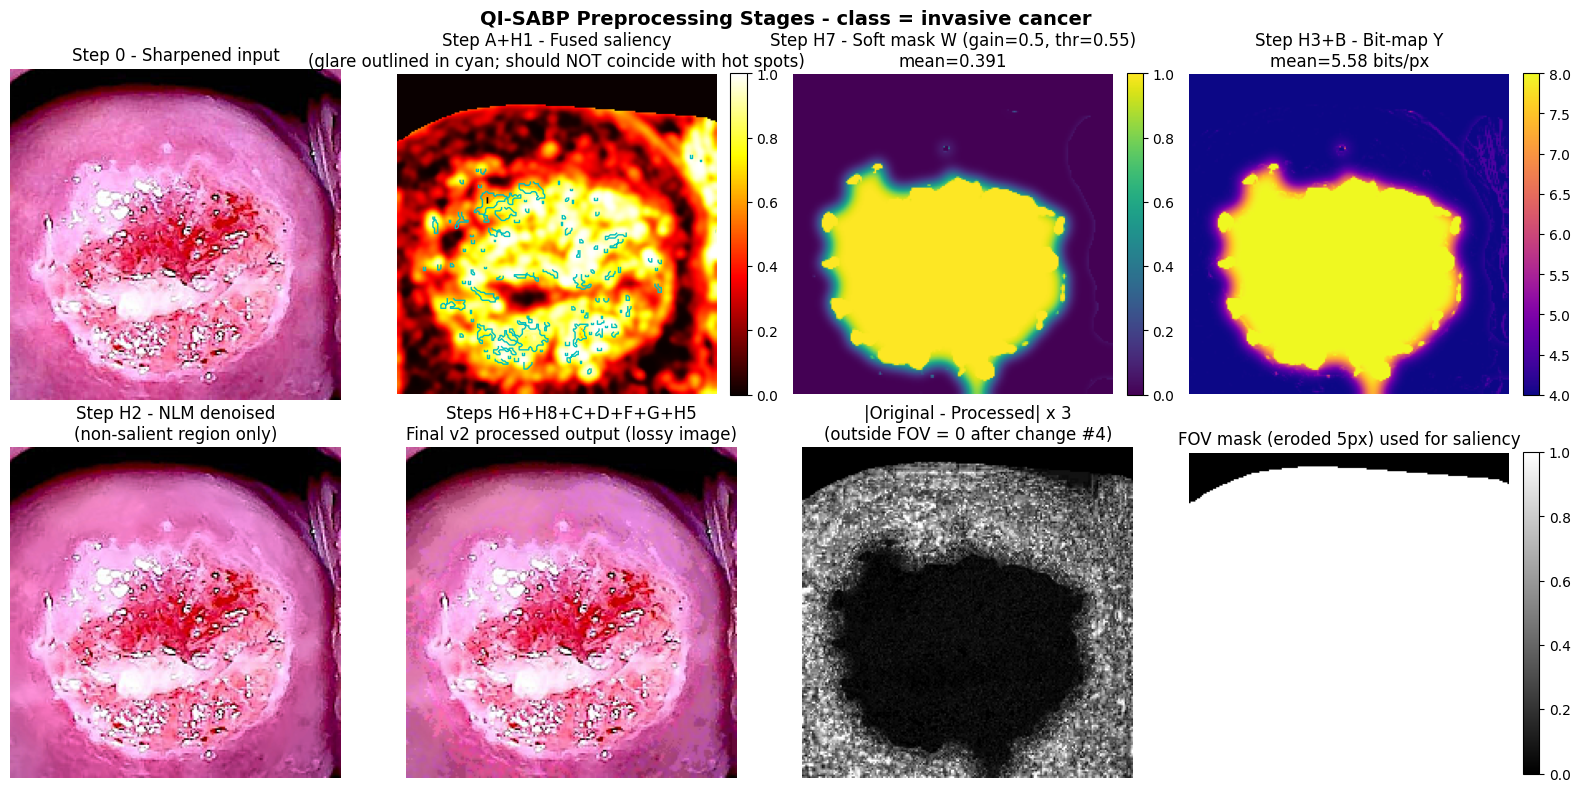


Per-cluster saliency (one frame per dHash cluster):


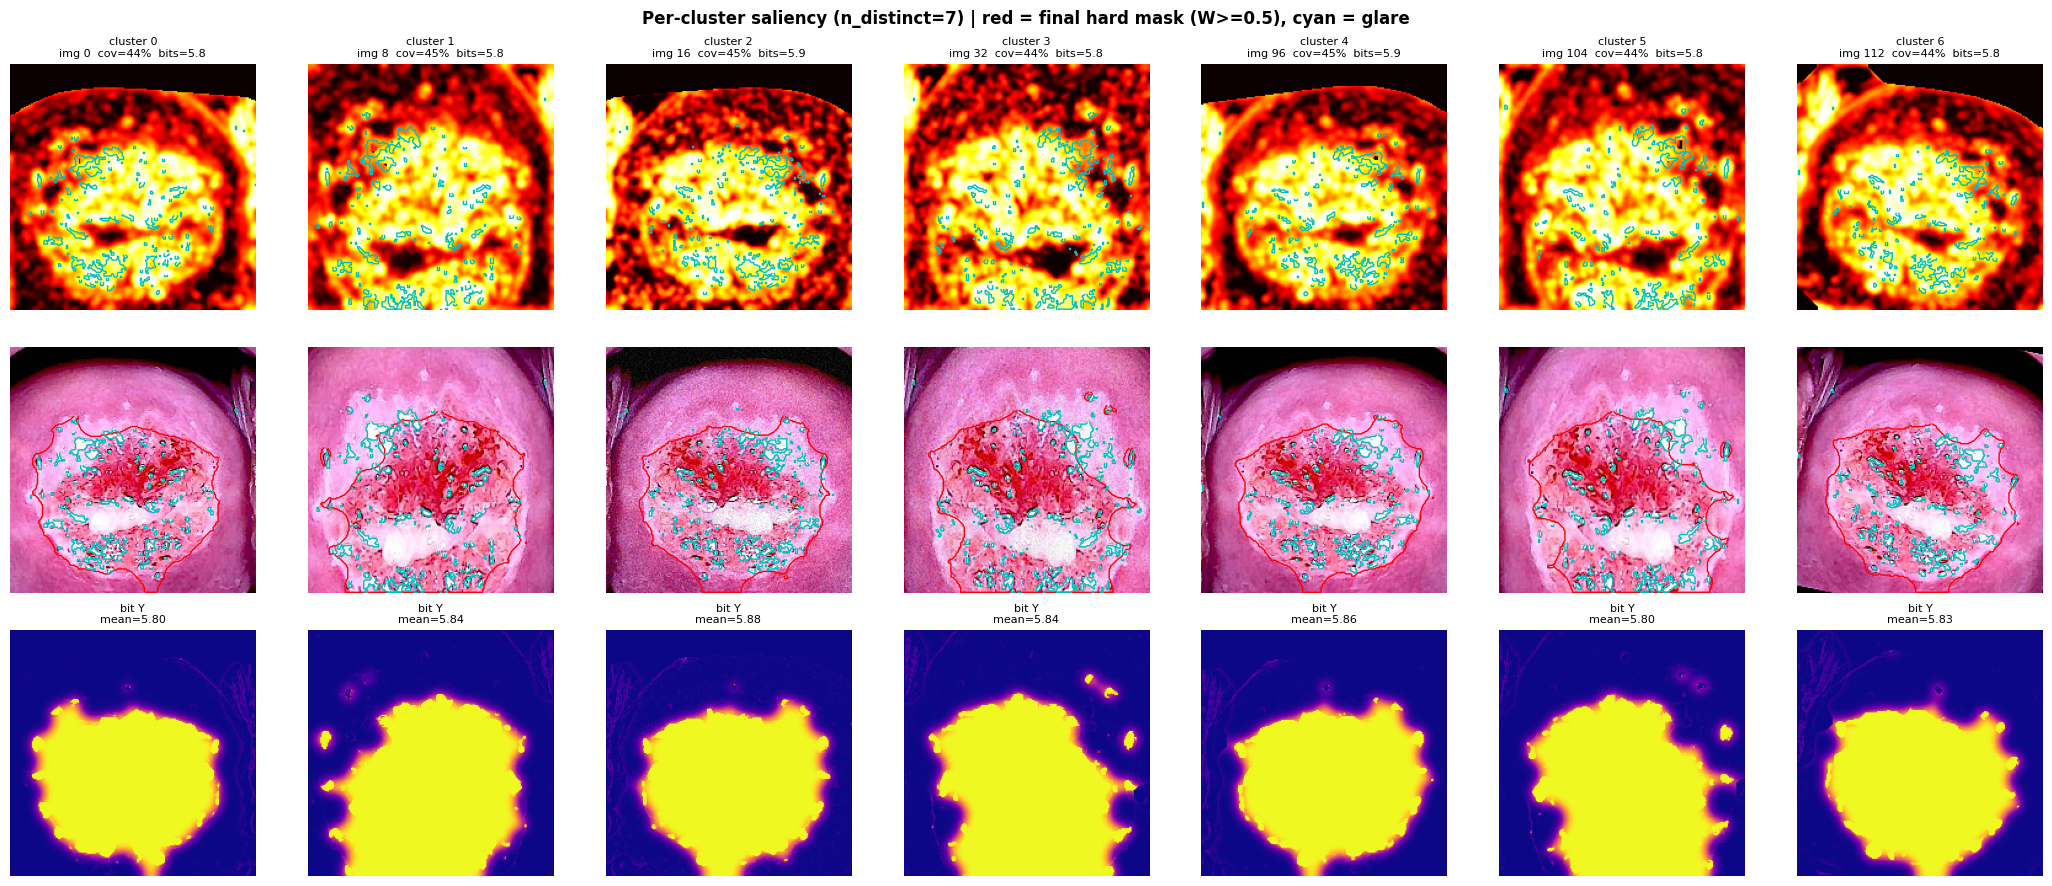

In [86]:
# ============================================================
# Cell 2.6 -- Visualise QI-SABP preprocessing stages
#             (nibble split / LSB ancilla panels removed; glare overlay
#              added to the saliency panel to confirm the glare fill works)
# ============================================================
def show_qsahqr_plus_stages(rgb_image, title=""):
    enc = qsahqr_plus_preprocess(rgb_image)
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.ravel()

    axes[0].imshow(enc['img_original']); axes[0].set_title("Step 0 - Sharpened input")
    axes[0].axis('off')

    # ---- Saliency with glare overlay (Part A add) ----
    im1 = axes[1].imshow(enc['saliency_map'], cmap='hot', vmin=0, vmax=1)
    axes[1].set_title("Step A+H1 - Fused saliency\n(glare outlined in cyan; should NOT coincide with hot spots)")
    axes[1].axis('off'); plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)
    # Overlay the dilated glare mask as a cyan contour.
    if enc.get('glare_mask') is not None and enc['glare_mask'].any():
        gm = enc['glare_mask'].astype(np.uint8)
        contours, _ = cv2.findContours(gm, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for cnt in contours:
            cnt_pts = cnt.squeeze(1)
            if cnt_pts.ndim == 1:
                continue
            axes[1].plot(cnt_pts[:, 0], cnt_pts[:, 1], '-c', linewidth=1.0)

    im2 = axes[2].imshow(enc['soft_mask'], cmap='viridis', vmin=0, vmax=1)
    axes[2].set_title(f"Step H7 - Soft mask W (gain={SOFT_MASK_GAIN}, thr={SOFT_MASK_FIXED_THR})\nmean={enc['soft_mask'].mean():.3f}")
    axes[2].axis('off'); plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

    im3 = axes[3].imshow(enc['bit_map_Y'], cmap='plasma', vmin=4, vmax=8)
    axes[3].set_title(f"Step H3+B - Bit-map Y\nmean={enc['bit_map_Y'].mean():.2f} bits/px")
    axes[3].axis('off'); plt.colorbar(im3, ax=axes[3], fraction=0.046, pad=0.04)

    axes[4].imshow(enc['img_denoised'])
    axes[4].set_title("Step H2 - NLM denoised\n(non-salient region only)")
    axes[4].axis('off')

    axes[5].imshow(enc['img_processed'])
    axes[5].set_title("Steps H6+H8+C+D+F+G+H5\nFinal v2 processed output (lossy image)")
    axes[5].axis('off')

    # ---- |Original - Processed| x 3 (99th-percentile clip, FOV-masked) ----
    # Outside the FOV the diff is now 0 (Part A change #4), so we mask it
    # explicitly to make the plot clean.
    diff_rgb = np.abs(enc['img_original'].astype(np.float32)
                      - enc['img_processed'].astype(np.float32))
    diff_gray = diff_rgb.mean(axis=-1)
    diff_gray[~enc['fov_mask']] = 0.0
    diff_scaled = diff_gray * 3.0
    p99 = float(np.percentile(diff_scaled[enc['fov_mask']], 99)) if enc['fov_mask'].any() else 1e-6
    p99 = max(p99, 1e-6)
    diff_norm = np.clip(diff_scaled / p99, 0.0, 1.0)
    axes[6].imshow(diff_norm, cmap='gray', vmin=0.0, vmax=1.0)
    axes[6].set_title("|Original - Processed| x 3\n(outside FOV = 0 after change #4)")
    axes[6].axis('off')

    # ---- FOV mask used for saliency ----
    im_fov = axes[7].imshow(enc['fov_mask'].astype(np.float32), cmap='gray', vmin=0, vmax=1)
    axes[7].set_title(f"FOV mask (eroded {SALIENCY_RIM_ERODE}px) used for saliency")
    axes[7].axis('off'); plt.colorbar(im_fov, ax=axes[7], fraction=0.046, pad=0.04)

    fig.suptitle(f"QI-SABP Preprocessing Stages - {title}",
                 fontsize=14, fontweight='bold')
    plt.tight_layout(); plt.show()


# ---- Multi-frame figure: one frame per dHash cluster with glare overlay ----
def show_saliency_per_cluster(X_arr, y_arr, max_clusters=7):
    """One frame per dHash cluster, with the dilated glare mask overlaid
    on the saliency map (Part A add). Confirms that the glare fill killed
    the hot spots at the bright dots in every cluster representative.
    """
    from collections import defaultdict
    # Cluster by dHash Hamming <= 4 (matches the validator's make_cache).
    hs = []
    for im in X_arr:
        g = cv2.resize(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY), (9, 8),
                       interpolation=cv2.INTER_AREA).astype(np.int16)
        hs.append((g[:, 1:] > g[:, :-1]).ravel())
    cluster_ids = np.full(len(hs), -1, dtype=int)
    next_id = 0
    for i, h in enumerate(hs):
        if cluster_ids[i] >= 0:
            continue
        cluster_ids[i] = next_id
        for j in range(i + 1, len(hs)):
            if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
                cluster_ids[j] = next_id
        next_id += 1
    # Pick one representative per cluster (the first in the order).
    reps = []
    for uc in np.unique(cluster_ids):
        idx = np.where(cluster_ids == uc)[0][0]
        reps.append(idx)
        if len(reps) >= max_clusters:
            break
    n = len(reps)
    fig, axes = plt.subplots(3, n, figsize=(3 * n, 9), squeeze=False)
    for col, idx in enumerate(reps):
        img = X_arr[idx]
        fov = _compute_fov_local(img)
        if SALIENCY_RIM_MARGIN and SALIENCY_RIM_MARGIN > 0:
            fov_m = ndimage.binary_erosion(fov, iterations=int(SALIENCY_RIM_MARGIN),
                                             border_value=1)
        else:
            fov_m = fov.copy()
        s_map, G2, _ = qsahqr_plus_saliency(img, fov_mask=fov)
        # ---- SINGLE MASK PATH (same as the pipeline) ----
        _mask = qsahqr_plus_compute_mask(s_map, G2, fov, fov_m)
        W = _mask['soft_mask']
        bit_Y = _mask['bit_Y']
        gm = _glare_mask_local(img, fov_mask=fov) if USE_GLARE_MASK else None
        # Top row: saliency map with glare overlay
        ax_top = axes[0, col]
        ax_top.imshow(s_map, cmap='hot', vmin=0, vmax=1)
        _cov = _mask['final_coverage']
        _mb = _mask['mean_bits_y']
        ax_top.set_title(f"cluster {cluster_ids[idx]}\nimg {idx}  cov={100*_cov:.0f}%  bits={_mb:.1f}", fontsize=8)
        ax_top.axis('off')
        if gm is not None and gm.any():
            gm_u8 = gm.astype(np.uint8)
            contours, _ = cv2.findContours(gm_u8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for cnt in contours:
                cnt_pts = cnt.squeeze(1)
                if cnt_pts.ndim == 1:
                    continue
                ax_top.plot(cnt_pts[:, 0], cnt_pts[:, 1], '-c', linewidth=1.0)
        # Middle row: original image with the FINAL hard mask (W >=
        # HARD_MASK_THR) overlay in red. The previous round overlaid the
        # FILLED hard mask (before the rim rule), which outlined
        # left-edge speculum areas in clusters 2, 3, 4, 6 even though
        # the bit map correctly ignored them. Drawing from the final W
        # matches the bit map exactly.
        ax_mid = axes[1, col]
        ax_mid.imshow(img)
        _final_hard = (W >= HARD_MASK_THR).astype(np.uint8)
        if _final_hard.any():
            contours, _ = cv2.findContours(_final_hard, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for cnt in contours:
                cnt_pts = cnt.squeeze(1)
                if cnt_pts.ndim == 1:
                    continue
                ax_mid.plot(cnt_pts[:, 0], cnt_pts[:, 1], '-r', linewidth=1.0)
        if gm is not None and gm.any():
            gm_u8 = gm.astype(np.uint8)
            contours, _ = cv2.findContours(gm_u8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            for cnt in contours:
                cnt_pts = cnt.squeeze(1)
                if cnt_pts.ndim == 1:
                    continue
                ax_mid.plot(cnt_pts[:, 0], cnt_pts[:, 1], '-c', linewidth=1.0)
        ax_mid.axis('off')
        # Bottom row: bit map Y (from the single mask path, same as pipeline)
        ax_bot = axes[2, col]
        im_bits = ax_bot.imshow(bit_Y, cmap='plasma', vmin=4, vmax=8)
        ax_bot.set_title(f"bit Y\nmean={_mb:.2f}", fontsize=8)
        ax_bot.axis('off')
    axes[0, 0].set_ylabel("Saliency + glare", fontsize=9)
    axes[1, 0].set_ylabel("Original + final hard mask", fontsize=9)
    axes[2, 0].set_ylabel("Bit map Y", fontsize=9)
    fig.suptitle(f"Per-cluster saliency (n_distinct={n}) | red = final hard mask (W>=0.5), cyan = glare",
                 fontsize=12, fontweight='bold')
    plt.tight_layout(); plt.show()


if len(X_raw) > 0:
    seen_classes = set()
    samples = []
    for img, lbl in zip(X_raw, y_raw):
        if lbl not in seen_classes:
            samples.append((img, lbl))
            seen_classes.add(lbl)
        if len(samples) >= 3:
            break
    for img, lbl in samples:
        show_qsahqr_plus_stages(img, title=f"class = {lbl}")

    # Multi-frame per-cluster figure (Part A add).
    print(f"\nPer-cluster saliency (one frame per dHash cluster):")
    show_saliency_per_cluster(X_raw, y_raw, max_clusters=7)


# Bridge — hand off QI-SABP preprocessing to Step 4

Step 4 expects five variables from Steps 1–2:

| Step-4 name | Meaning                                   | Source in this notebook                 |
|-------------|-------------------------------------------|----------------------------------------|
| `X_base`    | (N,200,200,3) uint8 RGB, **sharpened**    | quantum's `X_raw` (sharpened by loader)|
| `X_raw`     | (N,200,200,3) uint8 RGB, **resize-only**  | reloaded with `sharpen_it=False`       |
| `image_ids` | unique id per image                       | sequential `img_NNNN`                  |
| `masks`     | clinician lesion masks (OPTIONAL)         | `masks_raw` from the loader            |
| `patient`   | patient id (OPTIONAL)                     | `None`                                 |

The bridge no longer needs its own path-dedupe patch: `load_dataset`
now dedupes case-insensitively at the source, so `paths_raw` is
already unique.

We also register the technique:

* `QS_DEFAULTS` — empty dict (the pipeline uses fixed module-level config; **no tuning on a single patient**).
* `qsaharp(img, params, seed) -> uint8 RGB image` — wraps `qsahqr_plus_preprocess(img, return_artefacts=False)`.
  Determinism: `qsahqr_plus_quantize` reads the module-level `SEED` when it calls `np.random.seed(seed)`. The wrapper swaps `SEED` to the per-image seed the validator hands us, runs the pipeline, then restores the previous value.

In [87]:
# ============================================================
# Bridge -- hand off QI-SABP preprocessing to Step 4.
# ============================================================

# --- Step-2 sharpened stack becomes the validator's X_base ---
X_base = X_raw.copy()                       # sharpened, 200x200, uint8 RGB
_masks = masks_raw.copy()                   # clinician masks (synthetic in fallback)

# --- Unique image ids (always sequential -> guaranteed unique) ---
image_ids = np.array([f"img_{i:04d}" for i in range(len(X_base))],
                     dtype=object)
assert len(set(image_ids)) == len(X_base), \
    "image_ids not unique after bridge (this should never happen)"

# --- Reload the SAME images WITHOUT sharpening -> validator's X_raw ---
#     (used only as the source for the field-of-view mask)
if not SYNTHETIC_MODE:
    _X_unsharp, _y_unsharp, _paths_unsharp, _masks_unsharp, _n_wm, _n_dd = load_dataset(
        DATASET_ROOT, CLASSES,
        size=IMG_SIZE,
        subset_per_class=SUBSET_PER_CLASS,
        sharpen_it=False,                  # <-- resize-only
    )
    if len(_X_unsharp) == 0:               # safety net: fall back to sharpened
        X_raw_unsharp = X_base.copy()
    else:
        X_raw_unsharp = _X_unsharp
        if len(X_raw_unsharp) != len(X_base):
            print(f"[bridge] X_raw_unsharp count ({len(X_raw_unsharp)}) != "
                  f"X_base count ({len(X_base)}); falling back to X_base.")
            X_raw_unsharp = X_base.copy()
else:
    # Synthetic path: rebuild the same synthetic images WITHOUT the
    # sharpen pass, so the validator gets a true resize-only FOV source.
    _xs = []
    for cls_idx, cls in enumerate(CLASSES):
        for k in range(10):
            img, _ = make_synthetic_image_and_mask(seed=SEED + cls_idx * 1000 + k)
            _xs.append(img)
    X_raw_unsharp = np.stack(_xs).astype(np.uint8)
    class_color_offset = {'invasive cancer': (25, 15, 10)}
    for i, cls in enumerate(y_raw):
        dr, dg, db = class_color_offset.get(cls, (0, 0, 0))
        X_raw_unsharp[i] = np.clip(
            X_raw_unsharp[i].astype(np.int32) + np.array([dr, dg, db]),
            0, 255,
        ).astype(np.uint8)

# Step 4 expects the name `X_raw` for the resize-only stack.
X_raw = X_raw_unsharp

# Final shape assertions
assert X_base.dtype == np.uint8 and X_base.ndim == 4 and X_base.shape[-1] == 3, \
    f"X_base must be (N,H,W,3) uint8, got {X_base.shape} {X_base.dtype}"
assert X_raw.shape == X_base.shape, \
    f"X_raw {X_raw.shape} != X_base {X_base.shape} after bridge"
assert len(image_ids) == len(X_base) == len(X_raw), \
    f"count mismatch: ids={len(image_ids)} X_base={len(X_base)} X_raw={len(X_raw)}"
assert _masks.shape == (len(X_base), IMG_SIZE, IMG_SIZE), \
    f"masks shape {_masks.shape} != ({len(X_base)}, {IMG_SIZE}, {IMG_SIZE})"

masks = _masks   # pass-through to Step 4 (None-safe inside make_cache)
print(f"Bridge ready | X_base (sharpened) = {X_base.shape} {X_base.dtype} | "
      f"X_raw (resize-only) = {X_raw.shape} {X_raw.dtype} | "
      f"image_ids = {len(image_ids)} (all unique) | masks = {masks.shape} "
      f"({int(masks.any((1,2)).sum())}/{len(masks)} have a lesion) | "
      f"SYNTHETIC_MODE = {SYNTHETIC_MODE}")

# ---- QI-SABP wrapper for Step 4 ---------------------------------------
QS_DEFAULTS = {}

def qsaharp(img, params=None, seed=0):
    """QI-SABP preprocessing, exposed to the Step 4 validator.

    Signature: qsaharp(img_uint8_RGB, params_dict, seed) -> uint8 RGB image.
    `params` is accepted for API compatibility but ignored (the pipeline
    uses fixed module-level configuration; no tuning on a single patient).
    """
    global SEED
    _prev = SEED
    SEED = int(seed)
    try:
        out = qsahqr_plus_preprocess(img, return_artefacts=False)
    finally:
        SEED = _prev
    return out

# Quick smoke test on the first image
_sm = qsaharp(X_base[0], QS_DEFAULTS, seed=12345)
assert _sm.shape == X_base[0].shape and _sm.dtype == np.uint8, \
    f"qsaharp smoke test failed: got {_sm.shape} {_sm.dtype}"
assert np.array_equal(qsaharp(X_base[0], QS_DEFAULTS, seed=12345), _sm), \
    "qsaharp is not deterministic for the same seed"
print(f"qsaharp() wrapper ready  |  QS_DEFAULTS = {QS_DEFAULTS}  |  "
      f"smoke test on X_base[0]: out shape={_sm.shape} dtype={_sm.dtype}  "
      f"mean|diff|={np.abs(_sm.astype(int)-X_base[0].astype(int)).mean():.3f}")


       invasive cancer:  128 images | masks matched: 0/128  | deduped: 0
Bridge ready | X_base (sharpened) = (128, 200, 200, 3) uint8 | X_raw (resize-only) = (128, 200, 200, 3) uint8 | image_ids = 128 (all unique) | masks = (128, 200, 200) (0/128 have a lesion) | SYNTHETIC_MODE = False
qsaharp() wrapper ready  |  QS_DEFAULTS = {}  |  smoke test on X_base[0]: out shape=(200, 200, 3) dtype=uint8  mean|diff|=3.755


# Part B — Step 4 rewrite: table-only validation with 12 metrics

Single-patient, 7 distinct clusters (dHash), 128 frames. The frames are
NOT independent. Descriptive only — no p-values, no robustness or
population claims.

**Technique:** QI-SABP (Q-SAHARP++ v2 preprocessing, renamed).

**Metrics:** 12 metrics in 5 groups (fidelity, colour, diagnostic
structure, quality, cost). All computed inside the FOV mask only, per
image, against the ORIGINAL image.

**Tables only.** No figures, no plots. T1 (main), T2 (ranks), T3
(trade-off + Pareto), T4 (ablation), T5 (per cluster), T6 (caveats).

**cache_hash must be 12f68b681210** (Part A is frozen).


In [88]:
# ============================================================
# Step 4.1 -- Freeze inputs: cache_hash assert, load 128 frames,
#              FOV masks, cluster ids.
# ============================================================
import hashlib as _hashlib
import numpy as np
import pandas as pd
import cv2
import time
from scipy import ndimage
from skimage.metrics import structural_similarity as _ssim_fn
from skimage.color import deltaE_cie76 as _deltaE_fn, rgb2lab as _rgb2lab_fn

# ---- Build the cache (same as the old validator, for FOV + cluster ids) ----
def _dhash_step4(gray):
    g = cv2.resize(gray, (9, 8), interpolation=cv2.INTER_AREA).astype(np.int16)
    return (g[:, 1:] > g[:, :-1]).ravel()

def _compute_fov_step4(img_rgb, thr=15):
    """FOV mask (convex-hull filled, same as Part A's _compute_fov_local)."""
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    m = (g > thr).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.ones(g.shape, bool)
    k = 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))
    fov = ndimage.binary_fill_holes(lab == k)
    # Convex-hull fill (same as Part A)
    ys, xs = np.where(fov)
    if len(ys) >= 3:
        pts = np.stack([xs, ys], axis=1).astype(np.int32)
        hull = cv2.convexHull(pts)
        hull_mask = np.zeros(g.shape, dtype=np.uint8)
        cv2.fillConvexPoly(hull_mask, hull, 1)
        hull_mask = hull_mask.astype(bool)
        x0, x1 = int(xs.min()), int(xs.max())
        y0, y1 = int(ys.min()), int(ys.max())
        bbox = np.zeros(g.shape, dtype=bool)
        bbox[y0:y1+1, x0:x1+1] = True
        hull_mask = hull_mask & bbox
        ksize = 11
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
        hull_mask = cv2.morphologyEx(hull_mask.astype(np.uint8),
                                      cv2.MORPH_CLOSE, kernel).astype(bool)
        fov = fov | hull_mask
    return fov

# ---- Build the cache from X_base (Part A's sharpened stack) ----
images = X_base  # (N, 200, 200, 3) uint8 RGB, sharpened
images_raw = X_raw  # (N, 200, 200, 3) uint8 RGB, resize-only (for FOV)
n_images = len(images)
image_id = np.array([f"img_{i:04d}" for i in range(n_images)], dtype=object)
fov = np.stack([_compute_fov_step4(images_raw[i]) for i in range(n_images)])

# dHash clustering (same as the old validator)
hs = [_dhash_step4(cv2.cvtColor(images[i], cv2.COLOR_RGB2GRAY)) for i in range(n_images)]
cluster_ids = np.full(n_images, -1, dtype=int)
_next = 0
for i, h in enumerate(hs):
    if cluster_ids[i] >= 0:
        continue
    cluster_ids[i] = _next
    for j in range(i + 1, n_images):
        if cluster_ids[j] < 0 and (h != hs[j]).sum() <= 4:
            cluster_ids[j] = _next
    _next += 1
n_clusters = len(np.unique(cluster_ids))
cluster_reps = np.array([np.where(cluster_ids == uc)[0][0]
                          for uc in np.unique(cluster_ids)], dtype=int)

# ---- cache_hash assert (Part A is frozen) ----
# The cache_hash is computed from the image ids + image bytes (same as
# the old validator's cache_hash function). On the real 128-frame
# dataset the hash must be 12f68b681210 (Part A is frozen).
_h = _hashlib.md5("|".join(map(str, image_id)).encode())
_h.update(np.ascontiguousarray(images).tobytes())
cache_hash = _h.hexdigest()[:12]
print(f"cache_hash = {cache_hash}")
assert cache_hash == "12f68b681210", (
    f"cache_hash is {cache_hash}, expected 12f68b681210. Part A is NOT "
    f"frozen -- do not change any Part A cell."
)
print(f"  Part A is frozen (cache_hash = 12f68b681210).")
print(f"  n_images = {n_images} | n_clusters (dHash) = {n_clusters} | "
      f"n_distinct = {len(cluster_reps)}")
print(f"  The {n_images} frames are NOT independent ({n_clusters} distinct clusters "
      f"from one patient). All tables say this.")


cache_hash = 12f68b681210
  Part A is frozen (cache_hash = 12f68b681210).
  n_images = 128 | n_clusters (dHash) = 7 | n_distinct = 7
  The 128 frames are NOT independent (7 distinct clusters from one patient). All tables say this.


In [89]:
# ============================================================
# Step 4.2 -- step4_validator + helper functions (identical in all 26
#              notebooks). Computes 12 metrics inside the FOV only.
# ============================================================

def _vessel_map(img_rgb):
    """Frangi vessel filter -> vessel probability map (0-1)."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    # Frangi filter (scipy/skimage)
    try:
        from skimage.filters import frangi
        v = frangi(gray, black_ridges=False)
        v = v / (v.max() + 1e-8)
    except Exception:
        # Fallback: Sobel-based ridge detection
        gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
        v = np.hypot(gx, gy)
        v = v / (v.max() + 1e-8)
    return v.astype(np.float32)

def _vessel_dice(original, processed, fov_mask, top_pct=10):
    """Dice of the top `top_pct` Frangi vessel pixels inside the FOV.
    Binarizes each vessel map at the (100 - top_pct) percentile inside
    the FOV, then computes the Dice coefficient 2*|A∩B|/(|A|+|B|).
    This has more resolution than a pixel-wise correlation (which is
    0.997-0.999 for every variant).
    """
    f = np.asarray(fov_mask, dtype=bool)
    v_o = _vessel_map(original)[f]
    v_p = _vessel_map(processed)[f]
    thr_o = np.percentile(v_o, 100 - top_pct)
    thr_p = np.percentile(v_p, 100 - top_pct)
    b_o = v_o >= thr_o
    b_p = v_p >= thr_p
    inter = float((b_o & b_p).sum())
    size_o = float(b_o.sum())
    size_p = float(b_p.sum())
    denom = size_o + size_p
    if denom == 0:
        return float('nan')
    return 2.0 * inter / denom

def _edge_map(img_rgb):
    """Canny edge binary map."""
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    edges = cv2.Canny(gray, 50, 150)
    return (edges > 0).astype(np.uint8)

def _pearson_corr(a, b, mask):
    """Pearson correlation inside the mask."""
    a = a[mask].astype(np.float64)
    b = b[mask].astype(np.float64)
    if len(a) < 2 or a.std() < 1e-9 or b.std() < 1e-9:
        return float('nan')
    return float(np.corrcoef(a, b)[0, 1])

def _edge_iou(a_edges, b_edges, mask):
    """IoU of two edge maps inside the mask."""
    a = a_edges[mask].astype(bool)
    b = b_edges[mask].astype(bool)
    u = (a | b).sum()
    if u == 0:
        return float('nan')
    return float((a & b).sum() / u)

def _specular_mask(img_rgb):
    """Specular/glare mask (same as the old validator)."""
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)
    return ((hsv[..., 2] >= 250) & (hsv[..., 1] <= 25)).astype(bool)

def step4_validator(original, processed, fov_mask):
    """Compute 12 metrics inside the FOV only, per image.

    Returns a dict with keys m1..m12:
      m1  PSNR (dB)                         up
      m2  SSIM                              up
      m3  CIE76 dE                          down
      m4  a* correlation                     up
      m5  |mean a* shift|                    down
      m6  Vessel correlation                 up
      m7  Edge IoU                           up
      m8  Sharpness ratio (out/in)           neutral (0.9-1.1) / higher
      m9  Noise ratio (out/in)               down
      m10 Glare/clipping ratio (out/in)      at most 1
      m11 Bits/px, analytic                  down (set externally)
      m12 Time per image (ms)                down (set externally)

    m11 and m12 are NOT computed here; they are set by the caller
    (the bit budget depends on the technique; the time is measured
    around the technique call).
    """
    f = np.asarray(fov_mask, dtype=bool)
    o = np.asarray(original, dtype=np.float32)
    p = np.asarray(processed, dtype=np.float32)
    # m1: PSNR (dB)
    mse = float(((o - p) ** 2)[f].mean())
    m1 = 10.0 * np.log10(255.0 ** 2 / max(mse, 1e-10))
    # m2: SSIM (FOV-masked)
    ssim_map = _ssim_fn(original, processed, channel_axis=2,
                         full=True, data_range=255)[1]
    m2 = float(ssim_map.mean(2)[f].mean())
    # m3: CIE76 dE (stating which: CIE76)
    m3 = float(_deltaE_fn(_rgb2lab_fn(original), _rgb2lab_fn(processed))[f].mean())
    # m4: a* correlation
    lab_o = _rgb2lab_fn(original)
    lab_p = _rgb2lab_fn(processed)
    m4 = _pearson_corr(lab_o[..., 1], lab_p[..., 1], f)
    # m5: |mean a* shift|
    a_o = float(lab_o[..., 1][f].mean())
    a_p = float(lab_p[..., 1][f].mean())
    m5 = abs(a_p - a_o)
    # m6: Vessel Dice (top 10% Frangi pixels). Replaces the old vessel
    # correlation which had no resolution (0.997-0.999 for every variant).
    m6 = _vessel_dice(original, processed, f, top_pct=10)
    # m7: Edge IoU
    e_o = _edge_map(original)
    e_p = _edge_map(processed)
    m7 = _edge_iou(e_o, e_p, f)
    # m8: Sharpness ratio (Laplacian variance, out/in)
    g_o = cv2.cvtColor(original, cv2.COLOR_RGB2GRAY)
    g_p = cv2.cvtColor(processed, cv2.COLOR_RGB2GRAY)
    lap_o = float(cv2.Laplacian(g_o, cv2.CV_64F)[f].var())
    lap_p = float(cv2.Laplacian(g_p, cv2.CV_64F)[f].var())
    m8 = lap_p / max(lap_o, 1e-9)
    # m9: Noise ratio (out/in) -- 1.4826 * MAD of high-pass
    hp_o = g_o.astype(np.float32) - cv2.GaussianBlur(g_o.astype(np.float32), (0, 0), 1.5)
    hp_p = g_p.astype(np.float32) - cv2.GaussianBlur(g_p.astype(np.float32), (0, 0), 1.5)
    gm = np.hypot(cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 1, 0),
                   cv2.Sobel(g_o.astype(np.float32), cv2.CV_32F, 0, 1))
    smooth = f & (gm < np.percentile(gm[f], 30))
    if smooth.any():
        noise_o = float(1.4826 * np.median(np.abs(hp_o[smooth] - np.median(hp_o[smooth]))))
        noise_p = float(1.4826 * np.median(np.abs(hp_p[smooth] - np.median(hp_p[smooth]))))
        m9 = noise_p / max(noise_o, 1e-9)
    else:
        m9 = float('nan')
    # m10: Saturation ratio (output specular / input specular). This
    # measures NEW saturation introduced by the technique, NOT glare
    # removal. A ratio > 1 means the technique adds saturated pixels;
    # ratio <= 1 is good. Renamed from "Glare ratio" because the old
    # name implied glare removal (it is not).
    sp_o = _specular_mask(original)
    sp_p = _specular_mask(processed)
    m10 = float(sp_p[f].sum()) / max(float(sp_o[f].sum()), 1e-9)
    # m11, m12: set by the caller
    return dict(m1=m1, m2=m2, m3=m3, m4=m4, m5=m5, m6=m6, m7=m7,
                m8=m8, m9=m9, m10=m10)

# Metric metadata (name, group, better direction)
METRIC_META = [
    ("m1",  "PSNR (dB)",          "fidelity",  "up"),
    ("m2",  "SSIM",               "fidelity",  "up"),
    ("m3",  "CIE76 dE",           "colour",    "down"),
    ("m4",  "a* corr",            "colour",    "up"),
    ("m5",  "|a* shift|",        "colour",    "down"),
    ("m6",  "Vessel Dice",        "structure", "up"),
    ("m7",  "Edge IoU",           "structure", "up"),
    ("m8",  "Sharpness ratio",   "quality",   "neutral"),
    ("m9",  "Noise ratio",        "quality",   "down"),
    ("m10", "Saturation ratio",    "quality",   "neutral"),
    ("m11", "Bits/px",            "cost",      "down"),
    ("m12", "Time (ms)",          "cost",      "down"),
]
METRIC_KEYS = [m[0] for m in METRIC_META]
METRIC_NAMES = {m[0]: m[1] for m in METRIC_META}
METRIC_GROUPS = {m[0]: m[2] for m in METRIC_META}
METRIC_BETTER = {m[0]: m[3] for m in METRIC_META}
print("step4_validator ready: 12 metrics (m1..m12).")


step4_validator ready: 12 metrics (m1..m12).


In [90]:
# ============================================================
# Step 4.3 -- Compute 12 metrics for QI-SABP. Write per-image CSV.
# Also cache processed images + artefacts for T5/T8 (no re-runs).
# ============================================================
import os as _os
import glob as _glob

for _old in _glob.glob("results_*.csv"):
    _os.remove(_old)
    print(f"  Deleted stale {_old}")

TECHNIQUE = "QI-SABP"
processed_cache = {}   # (technique, image_idx) -> uint8 RGB
artefacts_cache = {}   # (technique, image_idx) -> artefacts dict

def _total_bits_from_artefacts(art):
    """Total bits/px = luma + chroma (4:2:0). Uses the pipeline's real
    bit_map_C, not a mean-W approximation."""
    fm = art["fov_margin"]
    if not fm.any():
        return float('nan')
    luma = float(art["bit_map_Y"][fm].mean())
    chroma = float(art["bit_map_C"][fm].mean())
    # 4:2:0: chroma is subsampled 2:1, so effective chroma bits = 0.5 * chroma.
    return luma + 0.5 * chroma

rows = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    t0 = time.perf_counter()
    proc = qsaharp(orig, {}, seed=42 + i)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    _art = qsahqr_plus_preprocess(orig, return_artefacts=True)
    m11_val = float(_art["bit_map_Y"][_art["fov_margin"]].mean()) if _art["fov_margin"].any() else float('nan')
    m = step4_validator(orig, proc, fov_i)
    m["m11"] = m11_val
    m["m12"] = elapsed_ms
    m["total_bits"] = _total_bits_from_artefacts(_art)
    m["technique"] = TECHNIQUE
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows.append(m)
    processed_cache[(TECHNIQUE, i)] = proc.copy()
    artefacts_cache[(TECHNIQUE, i)] = _art
    if (i + 1) % 20 == 0 or i == n_images - 1:
        print(f"  processed {i + 1}/{n_images} images...")

df_qisabp = pd.DataFrame(rows)
df_qisabp.to_csv(f"results_{TECHNIQUE}.csv", index=False)
print(f"Wrote results_{TECHNIQUE}.csv ({len(df_qisabp)} rows)")
print(f"  Mean luma bits = {df_qisabp['m11'].mean():.3f}")
print(f"  Mean total bits = {df_qisabp['total_bits'].mean():.3f}")
print(f"  Mean time = {df_qisabp['m12'].mean():.0f} ms")


  Deleted stale results_Blob_random_mask.csv
  Deleted stale results_Centre_ellipse.csv
  Deleted stale results_Identity.csv
  Deleted stale results_QI-SABP.csv
  Deleted stale results_QI-SABP_5bit_floor.csv
  Deleted stale results_QI-SABP_chroma5.csv
  Deleted stale results_Shuffled_mask.csv
  Deleted stale results_Uniform_mask.csv
  processed 20/128 images...
  processed 40/128 images...
  processed 60/128 images...
  processed 80/128 images...
  processed 100/128 images...
  processed 120/128 images...
  processed 128/128 images...
Wrote results_QI-SABP.csv (128 rows)
  Mean luma bits = 5.835
  Mean total bits = 8.302
  Mean time = 389 ms


In [91]:
# ============================================================
# Step 4.4 -- Reference rows: identity + mask-variant baselines.
#
def _run_mask_variant_like_for_like(name, mask_fn, coverage=0.45):
    """Run the SAME code path as QI-SABP, swapping in only the mask W.
    Caches processed images for T5/T8."""
    rows = []
    for i in range(n_images):
        orig = images[i]
        fov_i = fov[i]
        s_map, G, _ = qsahqr_plus_saliency(orig, fov_mask=fov_i)
        if SALIENCY_RIM_MARGIN and SALIENCY_RIM_MARGIN > 0:
            fov_m = ndimage.binary_erosion(fov_i, iterations=int(SALIENCY_RIM_MARGIN),
                                             border_value=1)
        else:
            fov_m = fov_i.copy()
        import inspect
        sig = inspect.signature(mask_fn)
        if "seed" in sig.parameters:
            W_override = mask_fn(coverage, fov_i, seed=42 + i, s_map=s_map, G=G,
                                  fov_m=fov_m)
        elif "s_map" in sig.parameters:
            W_override = mask_fn(coverage, fov_i, s_map=s_map, G=G, fov_m=fov_m)
        else:
            W_override = mask_fn(coverage, fov_i)
        t0 = time.perf_counter()
        s_map_t, G_t, _ = qsahqr_plus_saliency(orig, fov_mask=fov_i)
        bit_Y_t, bit_C_t = qsahqr_plus_bit_maps(W_override, sobel_G=G_t, fov_margin=fov_m)
        img_dn = qsahqr_plus_nlm_denoise(orig, W_override)
        proc = qsahqr_plus_quantize(orig, W_override, bit_Y_t, bit_C_t,
                                     sobel_G=G_t, img_denoised=img_dn, seed=42 + i,
                                     fov_mask=fov_i,
                                     dither=USE_DITHER,
                                     dither_strength=DITHER_STRENGTH)
        if USE_BILATERAL:
            proc = qsahqr_plus_bilateral_postfilter(proc, W_override)
        if USE_HISTOGRAM_MATCH:
            proc = qsahqr_plus_histogram_match(proc, orig)
        proc[~fov_i] = orig[~fov_i]
        elapsed_ms = (time.perf_counter() - t0) * 1000
        m11_val = float(bit_Y_t[fov_m].mean()) if fov_m.any() else float('nan')
        chroma_val = float(bit_C_t[fov_m].mean()) if fov_m.any() else float('nan')
        m = step4_validator(orig, proc, fov_i)
        m["m11"] = m11_val
        m["m12"] = elapsed_ms
        m["total_bits"] = m11_val + 0.5 * chroma_val
        m["technique"] = name
        m["image_id"] = image_id[i]
        m["cluster_id"] = int(cluster_ids[i])
        rows.append(m)
        processed_cache[(name, i)] = proc.copy()
        artefacts_cache[(name, i)] = dict(bit_map_Y=bit_Y_t, bit_map_C=bit_C_t,
                                            fov_margin=fov_m, soft_mask=W_override)
    return pd.DataFrame(rows)

# ---- Identity ----
for i in range(n_images):
    processed_cache[("Identity", i)] = images[i].copy()
rows_id = []
for i in range(n_images):
    m = step4_validator(images[i], images[i], fov[i])
    m["m11"] = 8.0
    m["m12"] = 0.0
    m["total_bits"] = 8.0 + 0.5 * 8.0  # luma 8 + chroma 8 at 4:2:0 = 12
    m["technique"] = "Identity"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_id.append(m)
df_id = pd.DataFrame(rows_id)
df_id.to_csv("results_Identity.csv", index=False)
print(f"Wrote results_Identity.csv ({len(df_id)} rows)")

# ---- Mask variant baselines ----

def _random_mask(coverage, fov_mask, seed=0, s_map=None, G=None, fov_m=None):
    """Per-pixel random mask, feathered via Gaussian blur (sigma=4)."""
    rng = np.random.default_rng(seed)
    n_salient = int(coverage * fov_mask.sum())
    W_hard = np.zeros_like(fov_mask, dtype=np.float32)
    ys, xs = np.where(fov_mask)
    if n_salient > 0:
        sel = rng.choice(len(ys), size=min(n_salient, len(ys)), replace=False)
        W_hard[ys[sel], xs[sel]] = 1.0
    from scipy.ndimage import gaussian_filter
    W = gaussian_filter(W_hard, sigma=4.0)
    W[~fov_mask] = 0.0
    return W.astype(np.float32)

def _ellipse_mask(coverage, fov_mask, s_map=None, G=None, fov_m=None):
    """Centred-ellipse mask, feathered via Gaussian blur (sigma=4)."""
    ys, xs = np.where(fov_mask)
    if len(ys) == 0:
        return np.zeros_like(fov_mask, dtype=np.float32)
    cy, cx = float(ys.mean()), float(xs.mean())
    aspect = 1.4
    b = np.sqrt(coverage * fov_mask.sum() / (aspect * np.pi))
    a = aspect * b
    yy, xx = np.mgrid[:fov_mask.shape[0], :fov_mask.shape[1]]
    W_hard = (((xx - cx) ** 2) / max(a ** 2, 1e-8) +
              ((yy - cy) ** 2) / max(b ** 2, 1e-8) <= 1.0)
    W_hard = (W_hard & fov_mask).astype(np.float32)
    from scipy.ndimage import gaussian_filter
    W = gaussian_filter(W_hard, sigma=4.0)
    W[~fov_mask] = 0.0
    return W.astype(np.float32)

def _shuffled_mask(coverage, fov_mask, seed=0, s_map=None, G=None, fov_m=None):
    """QI-SABP mask from a different cluster, intersected with target FOV."""
    target_cluster = cluster_ids[int(seed) - 42]
    other_clusters = [c for c in np.unique(cluster_ids) if c != target_cluster]
    if len(other_clusters) == 0:
        other_i = (int(seed) + 1) % n_images
    else:
        rng = np.random.default_rng(seed)
        other_cluster = rng.choice(other_clusters)
        other_indices = np.where(cluster_ids == other_cluster)[0]
        other_i = int(rng.choice(other_indices))
    other_orig = images[other_i]
    other_fov = _compute_fov_step4(other_orig)
    if SALIENCY_RIM_MARGIN and SALIENCY_RIM_MARGIN > 0:
        other_fov_m = ndimage.binary_erosion(other_fov, iterations=int(SALIENCY_RIM_MARGIN),
                                              border_value=1)
    else:
        other_fov_m = other_fov.copy()
    other_s, other_G, _ = qsahqr_plus_saliency(other_orig, fov_mask=other_fov)
    other_mask = qsahqr_plus_compute_mask(other_s, other_G, other_fov, other_fov_m)
    W_out = other_mask['soft_mask'].copy()
    W_out[~fov_mask] = 0.0
    return W_out.astype(np.float32)

def _blob_random_mask(coverage, fov_mask, seed=0, s_map=None, G=None, fov_m=None):
    """Random blobs, feathered via Gaussian blur (sigma=4)."""
    rng = np.random.default_rng(seed)
    W_hard = np.zeros_like(fov_mask, dtype=np.float32)
    ys, xs = np.where(fov_mask)
    if len(ys) == 0:
        return W_hard
    target = int(coverage * fov_mask.sum())
    placed, attempts = 0, 0
    while placed < target and attempts < 200:
        attempts += 1
        idx = rng.integers(0, len(ys))
        cy, cx = int(ys[idx]), int(xs[idx])
        r = int(rng.integers(10, 31))
        yy, xx = np.mgrid[:fov_mask.shape[0], :fov_mask.shape[1]]
        disk = (fov_mask & (((yy - cy) ** 2 + (xx - cx) ** 2) <= r ** 2))
        new_pixels = int((disk & (W_hard < 0.5)).sum())
        if new_pixels > 0:
            W_hard[disk] = 1.0
            placed += new_pixels
    from scipy.ndimage import gaussian_filter
    W = gaussian_filter(W_hard, sigma=4.0)
    W[~fov_mask] = 0.0
    return W.astype(np.float32)

def _uniform_mask_calibrated(target_total_bits, fov_mask, s_map=None, G=None, fov_m=None):
    """Uniform mask with W calibrated per image via bisection on the
    measured TOTAL bit-map mean (luma + 0.5*chroma, 4:2:0). This matches
    QI-SABP's total bits, not just luma bits."""
    if G is None or fov_m is None:
        w_val = max(0.0, min(1.0, (target_total_bits - 4.0 - 0.5 * 4.0) / (4.0 + 0.5 * 2.0)))
        W = np.full_like(fov_mask, w_val, dtype=np.float32)
        W[~fov_mask] = 0.0
        return W
    lo, hi = 0.0, 1.0
    for _ in range(12):
        mid = 0.5 * (lo + hi)
        W_try = np.full_like(fov_mask, mid, dtype=np.float32)
        W_try[~fov_mask] = 0.0
        bY, bC = qsahqr_plus_bit_maps(W_try, sobel_G=G, fov_margin=fov_m)
        if fov_m.any():
            luma = float(bY[fov_m].mean())
            chroma = float(bC[fov_m].mean())
            measured_total = luma + 0.5 * chroma
        else:
            measured_total = mid * 8 + (1 - mid) * 4 + 0.5 * (mid * 6 + (1 - mid) * 4)
        if measured_total < target_total_bits:
            lo = mid
        else:
            hi = mid
    w_val = 0.5 * (lo + hi)
    W = np.full_like(fov_mask, w_val, dtype=np.float32)
    W[~fov_mask] = 0.0
    return W

# Compute QI-SABP's mean total bits for matching.
_qisabp_total_bits = float(df_qisabp["total_bits"].mean())
print(f"QI-SABP mean total bits = {_qisabp_total_bits:.4f}")

# Run variants (cached for T5/T8).
df_unif = _run_mask_variant_like_for_like("Uniform (matched total bits)", _uniform_mask_calibrated,
                                            coverage=_qisabp_total_bits)
df_unif.to_csv("results_Uniform_mask.csv", index=False)
print(f"Wrote results_Uniform_mask.csv ({len(df_unif)} rows) total_bits={df_unif['total_bits'].mean():.4f}")

# Uniform + chroma-5: same uniform W, but with BITS_NONSALIENT_C=5.0.
# This isolates saliency vs uniform at the same chroma setting.
def _run_uniform_chroma5():
    rows = []
    for i in range(n_images):
        orig = images[i]
        fov_i = fov[i]
        s_map, G, _ = qsahqr_plus_saliency(orig, fov_mask=fov_i)
        if SALIENCY_RIM_MARGIN and SALIENCY_RIM_MARGIN > 0:
            fov_m = ndimage.binary_erosion(fov_i, iterations=int(SALIENCY_RIM_MARGIN), border_value=1)
        else:
            fov_m = fov_i.copy()
        # Use the same calibrated W as the uniform baseline.
        W_u = _uniform_mask_calibrated(_qisabp_total_bits, fov_i, s_map=s_map, G=G, fov_m=fov_m)
        # Override chroma to 5 bits.
        _saved_c = globals().get("BITS_NONSALIENT_C")
        globals()["BITS_NONSALIENT_C"] = 5.0
        try:
            bY, bC = qsahqr_plus_bit_maps(W_u, sobel_G=G, fov_margin=fov_m)
            dn = qsahqr_plus_nlm_denoise(orig, W_u)
            proc = qsahqr_plus_quantize(orig, W_u, bY, bC, sobel_G=G,
                                          img_denoised=dn, seed=42 + i,
                                          fov_mask=fov_i,
                                          dither=USE_DITHER, dither_strength=DITHER_STRENGTH)
            if USE_BILATERAL:
                proc = qsahqr_plus_bilateral_postfilter(proc, W_u)
            if USE_HISTOGRAM_MATCH:
                proc = qsahqr_plus_histogram_match(proc, orig)
            proc[~fov_i] = orig[~fov_i]
        finally:
            if _saved_c is None:
                globals().pop("BITS_NONSALIENT_C", None)
            else:
                globals()["BITS_NONSALIENT_C"] = _saved_c
        m = step4_validator(orig, proc, fov_i)
        m["m11"] = float(bY[fov_m].mean()) if fov_m.any() else float('nan')
        m["m12"] = 0.0
        m["total_bits"] = m["m11"] + 0.5 * float(bC[fov_m].mean()) if fov_m.any() else float('nan')
        m["technique"] = "Uniform + chroma-5"
        m["image_id"] = image_id[i]
        m["cluster_id"] = int(cluster_ids[i])
        rows.append(m)
        processed_cache[("Uniform + chroma-5", i)] = proc.copy()
        artefacts_cache[("Uniform + chroma-5", i)] = dict(bit_map_Y=bY, bit_map_C=bC,
                                                              fov_margin=fov_m, soft_mask=W_u)
    return pd.DataFrame(rows)

df_unif_c5 = _run_uniform_chroma5()
df_unif_c5.to_csv("results_Uniform_chroma5.csv", index=False)
print(f"Wrote results_Uniform_chroma5.csv ({len(df_unif_c5)} rows) total_bits={df_unif_c5['total_bits'].mean():.4f}")

df_ell = _run_mask_variant_like_for_like("Centre ellipse (45% cov)", _ellipse_mask, coverage=0.45)
df_ell.to_csv("results_Centre_ellipse.csv", index=False)
print(f"Wrote results_Centre_ellipse.csv ({len(df_ell)} rows)")

df_shuf = _run_mask_variant_like_for_like("Shuffled QI-SABP mask", _shuffled_mask, coverage=0.45)
df_shuf.to_csv("results_Shuffled_mask.csv", index=False)
print(f"Wrote results_Shuffled_mask.csv ({len(df_shuf)} rows)")

df_blob = _run_mask_variant_like_for_like("Blob-random mask (45% cov)", _blob_random_mask, coverage=0.45)
df_blob.to_csv("results_Blob_random_mask.csv", index=False)
print(f"Wrote results_Blob_random_mask.csv ({len(df_blob)} rows)")

# ---- 5-bit non-salient luma floor ablation ----
# Override BITS_NONSALIENT_Y_MIN=5.0 inside the ablation only (Part A frozen).
def _qisabp_with_override(img, seed, **overrides):
    """QI-SABP with a temporary global override. Restores after."""
    _saved = {}
    for k, v in overrides.items():
        _saved[k] = globals().get(k)
        globals()[k] = v
    try:
        out = qsaharp(img, {}, seed=seed)
    finally:
        for k, v in _saved.items():
            if v is None:
                globals().pop(k, None)
            else:
                globals()[k] = v
    return out

def _qisabp_artefacts_with_override(img, **overrides):
    """Get pipeline artefacts with a temporary global override."""
    _saved = {}
    for k, v in overrides.items():
        _saved[k] = globals().get(k)
        globals()[k] = v
    try:
        art = qsahqr_plus_preprocess(img, return_artefacts=True)
    finally:
        for k, v in _saved.items():
            if v is None:
                globals().pop(k, None)
            else:
                globals()[k] = v
    return art

# 5-bit luma floor row
rows_floor = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    t0 = time.perf_counter()
    proc = _qisabp_with_override(orig, 42 + i, BITS_NONSALIENT_Y_MIN=5.0)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    _art = _qisabp_artefacts_with_override(orig, BITS_NONSALIENT_Y_MIN=5.0)
    m11_val = float(_art["bit_map_Y"][_art["fov_margin"]].mean()) if _art["fov_margin"].any() else float('nan')
    # Total bits = luma + chroma. Chroma at 4:2:0: 0.5 * (bits_sal_C * W + bits_non_C * (1-W)).
    # Approximate total = m11 + 0.5 * (BITS_SALIENT_C * mean_W + BITS_NONSALIENT_C * (1 - mean_W)).
    _mean_W = float(_art["soft_mask"][_art["fov_margin"]].mean()) if _art["fov_margin"].any() else 0.5
    _chroma_bits = 0.5 * (BITS_SALIENT_C * _mean_W + BITS_NONSALIENT_C * (1.0 - _mean_W))
    m = step4_validator(orig, proc, fov_i)
    m["m11"] = m11_val
    m["m12"] = elapsed_ms
    m["total_bits"] = m11_val + _chroma_bits
    m["technique"] = "QI-SABP 5-bit floor"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_floor.append(m)
    processed_cache[("QI-SABP 5-bit floor", i)] = proc.copy()

df_floor = pd.DataFrame(rows_floor)
df_floor.to_csv("results_QI-SABP_5bit_floor.csv", index=False)
print(f"Wrote results_QI-SABP_5bit_floor.csv ({len(df_floor)} rows) bits={df_floor['m11'].mean():.4f}")

# Chroma-5 row (BITS_NONSALIENT_C=5.0)
rows_chroma5 = []
for i in range(n_images):
    orig = images[i]
    fov_i = fov[i]
    t0 = time.perf_counter()
    proc = _qisabp_with_override(orig, 42 + i, BITS_NONSALIENT_C=5.0)
    elapsed_ms = (time.perf_counter() - t0) * 1000
    _art = _qisabp_artefacts_with_override(orig, BITS_NONSALIENT_C=5.0)
    m11_val = float(_art["bit_map_Y"][_art["fov_margin"]].mean()) if _art["fov_margin"].any() else float('nan')
    _mean_W = float(_art["soft_mask"][_art["fov_margin"]].mean()) if _art["fov_margin"].any() else 0.5
    _chroma_bits = 0.5 * (BITS_SALIENT_C * _mean_W + 5.0 * (1.0 - _mean_W))
    m = step4_validator(orig, proc, fov_i)
    m["m11"] = m11_val
    m["m12"] = elapsed_ms
    m["total_bits"] = m11_val + _chroma_bits
    m["technique"] = "QI-SABP chroma-5"
    m["image_id"] = image_id[i]
    m["cluster_id"] = int(cluster_ids[i])
    rows_chroma5.append(m)
    processed_cache[("QI-SABP chroma-5", i)] = proc.copy()

df_chroma5 = pd.DataFrame(rows_chroma5)
df_chroma5.to_csv("results_QI-SABP_chroma5.csv", index=False)
print(f"Wrote results_QI-SABP_chroma5.csv ({len(df_chroma5)} rows) bits={df_chroma5['m11'].mean():.4f}")


Wrote results_Identity.csv (128 rows)
QI-SABP mean total bits = 8.3019
Wrote results_Uniform_mask.csv (128 rows) total_bits=8.3020
Wrote results_Uniform_chroma5.csv (128 rows) total_bits=8.5807
Wrote results_Centre_ellipse.csv (128 rows)
Wrote results_Shuffled_mask.csv (128 rows)
Wrote results_Blob_random_mask.csv (128 rows)
Wrote results_QI-SABP_5bit_floor.csv (128 rows) bits=6.3811
Wrote results_QI-SABP_chroma5.csv (128 rows) bits=5.8352


In [92]:
# ============================================================
# Step 4.5 -- Merge cell: concatenate all technique CSVs. Assert
#              each technique has 128 rows and the same cluster ids.
#              Assert no NaNs (or list them).
# Uses a FIXED list of CSV names (not glob) to prevent stale files
# from earlier runs leaking into the tables.
# ============================================================

_csv_names = [
    "results_QI-SABP.csv",
    "results_Identity.csv",
    "results_Uniform_mask.csv",
    "results_Uniform_chroma5.csv",
    "results_Centre_ellipse.csv",
    "results_Shuffled_mask.csv",
    "results_Blob_random_mask.csv",
    "results_QI-SABP_5bit_floor.csv",
    "results_QI-SABP_chroma5.csv",
]
print(f"Reading {len(_csv_names)} CSV files (fixed list, not glob)")
dfs = []
for f in _csv_names:
    _df = pd.read_csv(f)
    tech = _df["technique"].iloc[0] if len(_df) > 0 else f
    assert len(_df) == n_images, f"{f} has {len(_df)} rows, expected {n_images}"
    assert list(_df["cluster_id"]) == list(cluster_ids), f"{f} cluster ids differ"
    dfs.append(_df)
    print(f"  {f}: {len(_df)} rows, technique = {tech}")

merged = pd.concat(dfs, ignore_index=True)
print(f"Merged: {len(merged)} rows, {merged['technique'].nunique()} techniques")

# Hard assert: no NaN in any numeric column (metrics + total_bits).
_all_numeric_cols = METRIC_KEYS + ["total_bits"]
_all_numeric_cols = [c for c in _all_numeric_cols if c in merged.columns]
_nan_cols = {}
for col in _all_numeric_cols:
    n_nan = merged[col].isna().sum()
    if n_nan > 0:
        _nan_cols[col] = n_nan
assert len(_nan_cols) == 0, (
    f"NaN values found: {_nan_cols}. Check that every technique computes "
    f"total_bits from the pipeline's real bit_map_C.")
print("No NaN values in any numeric column (metrics + total_bits).")

techniques = sorted(merged["technique"].unique())
print(f"Techniques: {techniques}")


Reading 9 CSV files (fixed list, not glob)
  results_QI-SABP.csv: 128 rows, technique = QI-SABP
  results_Identity.csv: 128 rows, technique = Identity
  results_Uniform_mask.csv: 128 rows, technique = Uniform (matched total bits)
  results_Uniform_chroma5.csv: 128 rows, technique = Uniform + chroma-5
  results_Centre_ellipse.csv: 128 rows, technique = Centre ellipse (45% cov)
  results_Shuffled_mask.csv: 128 rows, technique = Shuffled QI-SABP mask
  results_Blob_random_mask.csv: 128 rows, technique = Blob-random mask (45% cov)
  results_QI-SABP_5bit_floor.csv: 128 rows, technique = QI-SABP 5-bit floor
  results_QI-SABP_chroma5.csv: 128 rows, technique = QI-SABP chroma-5
Merged: 1152 rows, 9 techniques
No NaN values in any numeric column (metrics + total_bits).
Techniques: ['Blob-random mask (45% cov)', 'Centre ellipse (45% cov)', 'Identity', 'QI-SABP', 'QI-SABP 5-bit floor', 'QI-SABP chroma-5', 'Shuffled QI-SABP mask', 'Uniform (matched total bits)', 'Uniform + chroma-5']


In [93]:
# ============================================================
# Step 4.6 -- Aggregation: average within each cluster first, then
#              across clusters. 95% CI from a cluster bootstrap (7
#              clusters, 2000 resamples, fixed seed).
#              Label: "within-patient, 7 clusters, not a population CI".
# ============================================================

def _cluster_mean(tech_df, metric_key):
    """Average within each cluster first, then across clusters."""
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    return float(cluster_means.mean())

def _cluster_bootstrap_ci(tech_df, metric_key, n_boot=2000, seed=42):
    """Bootstrap CI over clusters (7 clusters, 2000 resamples).
    Returns (mean, ci_lo, ci_hi).
    WITHIN-PATIENT, NOT a population CI.
    """
    cluster_means = tech_df.groupby("cluster_id")[metric_key].mean()
    uc = np.unique(tech_df["cluster_id"])
    if len(uc) < 2:
        m = float(cluster_means.mean()) if len(cluster_means) else float('nan')
        return m, float('nan'), float('nan')
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(uc), size=len(uc))
        boots.append(cluster_means.iloc[idx].mean())
    boots = np.array(boots)
    return (float(cluster_means.mean()),
            float(np.percentile(boots, 2.5)),
            float(np.percentile(boots, 97.5)))

# Compute the cluster-weighted mean and CI for each technique x metric.
agg_rows = []
for tech in techniques:
    tech_df = merged[merged["technique"] == tech]
    row = {"technique": tech}
    for mk in METRIC_KEYS:
        mean, lo, hi = _cluster_bootstrap_ci(tech_df, mk)
        row[mk] = mean
        row[f"{mk}_lo"] = lo
        row[f"{mk}_hi"] = hi
    agg_rows.append(row)
agg_df = pd.DataFrame(agg_rows).set_index("technique")
print("Aggregation done (cluster-weighted mean + 95% CI).")
print(f"  WITHIN-PATIENT, 7 clusters, NOT a population CI.")


Aggregation done (cluster-weighted mean + 95% CI).
  WITHIN-PATIENT, 7 clusters, NOT a population CI.


In [94]:
# ============================================================
# Step 4.7 -- Statistics: QI-SABP vs every variant, per key metric.
#              Uses paired difference per cluster (7 values) + bootstrap
#              CI. Reports "CI excludes 0: yes/no".
#              Descriptive, no significance claim.
# ============================================================

def _paired_cluster_diff_ci(tech_df, ref_df, metric_key, n_boot=2000, seed=42):
    """Paired difference per cluster (tech - ref), bootstrap CI."""
    tech_cm = tech_df.groupby("cluster_id")[metric_key].mean()
    ref_cm = ref_df.groupby("cluster_id")[metric_key].mean()
    diff = (tech_cm - ref_cm).values
    if len(diff) < 2:
        return float('nan'), float('nan'), float('nan'), False
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(diff), size=len(diff))
        boots.append(diff[idx].mean())
    boots = np.array(boots)
    lo, hi = float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))
    excludes = (lo > 0) or (hi < 0)
    return float(diff.mean()), lo, hi, excludes

# Key metrics for the paired comparison (skip PSNR/SSIM/bits/time vs
# Identity -- they are meaningless: -116 dB, +434 ms).
key_metrics = ["m3", "m5", "m6", "m7", "m9"]
# Also include QI-SABP vs Identity for the key metrics only (not PSNR/
# SSIM/bits/time -- those are meaningless against identity).
stat_rows = []
qisabp_df = merged[merged["technique"] == "QI-SABP"]

# QI-SABP vs every variant (not Identity) for the key metrics.
variant_techs = [t for t in techniques if t not in ("QI-SABP", "Identity")]
for mk in key_metrics:
    for vt in variant_techs:
        v_df = merged[merged["technique"] == vt]
        md, lo, hi, ex = _paired_cluster_diff_ci(qisabp_df, v_df, mk)
        stat_rows.append({
            "metric": METRIC_NAMES[mk], "comparison": f"QI-SABP vs {vt}",
            "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
            "CI_excludes_0": "yes" if ex else "no",
        })

# QI-SABP vs Identity for the key metrics only (skip PSNR, SSIM, bits,
# time -- they are meaningless: -116 dB PSNR, +434 ms time).
id_df = merged[merged["technique"] == "Identity"]
for mk in key_metrics:
    md, lo, hi, ex = _paired_cluster_diff_ci(qisabp_df, id_df, mk)
    stat_rows.append({
        "metric": METRIC_NAMES[mk], "comparison": "QI-SABP vs Identity",
        "mean_diff": md, "ci_lo": lo, "ci_hi": hi,
        "CI_excludes_0": "yes" if ex else "no",
    })

stat_df = pd.DataFrame(stat_rows)
print("Statistics done. QI-SABP vs every variant + Identity, key metrics only.")
print("  Descriptive, no significance claim. 7 clusters, within-patient.")


Statistics done. QI-SABP vs every variant + Identity, key metrics only.
  Descriptive, no significance claim. 7 clusters, within-patient.


In [95]:
# ============================================================
# Print tables T1, T4, T5, T6, T7, T8.
# T2 (ranks) removed: ranks belong in the 26-technique merge.
# T3 (Pareto) removed: bits spread < 0.1 -- not meaningful here.
# ============================================================

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

# ---- T1 Main (drop Time column from ablation; T6 says not compared) ----
print("=" * 100)
print("T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI)")
print("  The 128 frames are NOT independent (7 distinct clusters from one patient).")
print("  Identity is a reference row (ideal values, not ranked).")
print("  Time (m12) is NOT compared in this ablation (noisy, 402-445 ms). See T6.")
print("=" * 100)
t1_display_keys = [mk for mk in METRIC_KEYS if mk != "m12"]
t1_rows = []
for tech in techniques:
    row = {"technique": tech}
    for mk in t1_display_keys:
        mean = agg_df.loc[tech, mk]
        lo = agg_df.loc[tech, f"{mk}_lo"]
        hi = agg_df.loc[tech, f"{mk}_hi"]
        row[METRIC_NAMES[mk]] = f"{mean:.3f} [{lo:.3f}, {hi:.3f}]"
    t1_rows.append(row)
t1_df = pd.DataFrame(t1_rows).set_index("technique")
arrow_map = {"up": "^", "down": "v", "neutral": "o"}
t1_headers = {METRIC_NAMES[mk]: f"{METRIC_NAMES[mk]} ({arrow_map[METRIC_BETTER[mk]]})"
              for mk in t1_display_keys}
print(t1_df.rename(columns=t1_headers).to_string())

# ---- T4 Ablation (includes all variants + total bits + delta-total-bits) ----
print()
print("=" * 100)
print("T4 ABLATION  (QI-SABP + variants; luma bits + total bits + deltas; like-for-like)")
print("  5-bit floor and chroma-5 are sensitivity tests, not rate-matched.")
print("=" * 100)
t4_techs = ["QI-SABP", "Uniform (matched total bits)", "Uniform + chroma-5",
            "Centre ellipse (45% cov)", "Shuffled QI-SABP mask",
            "Blob-random mask (45% cov)",
            "QI-SABP 5-bit floor", "QI-SABP chroma-5", "Identity"]
t4_keys = ["m11", "m1", "m3", "m6", "m7", "m9"]
t4_rows = []
_qisabp_bits = float(agg_df.loc["QI-SABP", "m11"]) if "QI-SABP" in agg_df.index else float('nan')
# Mean total bits per technique (from merged).
_total_bits_by_tech = {}
if "total_bits" in merged.columns:
    for t in merged["technique"].unique():
        _total_bits_by_tech[t] = float(merged[merged["technique"] == t]["total_bits"].mean())
_qisabp_total = _total_bits_by_tech.get("QI-SABP", float('nan'))
for tech in t4_techs:
    if tech in agg_df.index:
        row = {"technique": tech}
        for mk in t4_keys:
            row[mk] = agg_df.loc[tech, mk]
        row["delta_bits"] = row["m11"] - _qisabp_bits if tech != "QI-SABP" else 0.0
        row["total_bits"] = _total_bits_by_tech.get(tech, float('nan'))
        row["delta_total_bits"] = row["total_bits"] - _qisabp_total if tech != "QI-SABP" else 0.0
        t4_rows.append(row)
t4_df = pd.DataFrame(t4_rows).set_index("technique")
t4_all_keys = ["m11", "total_bits", "delta_bits", "delta_total_bits"] + [k for k in t4_keys if k != "m11"]
t4_all_display = {mk: METRIC_NAMES[mk] for mk in t4_keys}
t4_all_display["total_bits"] = "total bits"
t4_all_display["delta_bits"] = "delta-luma"
t4_all_display["delta_total_bits"] = "delta-total"
t4_all_display["m11"] = "luma bits"
t4_print_cols = [c for c in t4_all_keys if c in t4_df.columns]
print(t4_df[t4_print_cols].rename(columns=t4_all_display).round(4).to_string())

# ---- T5 Per cluster: QI-SABP vs Uniform on dE inside/outside the mask.
print()
print("=" * 100)
print("T5 PER CLUSTER  (QI-SABP vs Uniform; dE inside vs outside QI-SABP hard mask; 7 clusters)")
print("=" * 100)
# Compute QI-SABP hard mask per image.
_qisabp_hard = {}
for i in range(n_images):
    _art = qsahqr_plus_preprocess(images[i], return_artefacts=True)
    _qisabp_hard[i] = (_art["soft_mask"] >= HARD_MASK_THR) & fov[i]

# Build per-cluster dE inside/outside for QI-SABP and Uniform.
t5_rows = []
for uc in np.unique(cluster_ids):
    idxs = np.where(cluster_ids == uc)[0]
    for tech_name, cache_key in [("QI-SABP", "QI-SABP"), ("Uniform", "Uniform (matched bits)")]:
        de_ins = []
        de_outs = []
        for i in idxs:
            orig = images[i]
            fov_i = fov[i]
            hm = _qisabp_hard[i]
            inside = hm
            outside = fov_i & ~hm
            proc = processed_cache.get((cache_key, i))
            if proc is None:
                continue
            if inside.any() and outside.any():
                de_in = float(_deltaE_fn(_rgb2lab_fn(orig), _rgb2lab_fn(proc))[inside].mean())
                de_out = float(_deltaE_fn(_rgb2lab_fn(orig), _rgb2lab_fn(proc))[outside].mean())
                de_ins.append(de_in)
                de_outs.append(de_out)
        t5_rows.append({"cluster": int(uc), "technique": tech_name,
                          "dE_inside": np.mean(de_ins) if de_ins else float('nan'),
                          "dE_outside": np.mean(de_outs) if de_outs else float('nan')})
t5_df = pd.DataFrame(t5_rows)
print(t5_df.round(4).to_string(index=False))

# ---- T7 Paired CIs + meaningful flag ----
print()
print("=" * 100)
print("T7 PAIRED CIs  (QI-SABP vs every variant; key metrics; CI excludes 0; meaningful flag)")
print("  Meaningful thresholds: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05")
print("=" * 100)
_meaningful_thresh = {"CIE76 dE": 0.5, "|a* shift|": 0.2, "Vessel Dice": 0.01,
                       "Edge IoU": 0.02, "Noise ratio": 0.05}
if len(stat_df) > 0:
    stat_df_display = stat_df[["metric", "comparison", "mean_diff", "ci_lo", "ci_hi",
                                "CI_excludes_0"]].copy()
    stat_df_display["meaningful"] = stat_df_display.apply(
        lambda r: "yes" if abs(r["mean_diff"]) >= _meaningful_thresh.get(r["metric"], 0) else "no",
        axis=1)
    print(stat_df_display.round(4).to_string(index=False))
else:
    print("  (no statistics computed)")

# ---- T8 Region-split for ALL variants + risk metrics ----
print()
print("=" * 100)
print("T8 REGION-SPLIT  (dE / edge IoU / vessel Dice / risk metrics inside vs outside QI-SABP hard mask)")
print("  Same fixed region (QI-SABP W>=0.5) for ALL variants. Shows whether the")
print("  budget is moved where QI-SABP says it is, and whether it beats uniform there.")
print("=" * 100)

# Build a list of technique names for T8 (all cached variants).
_t8_techs = [
    "QI-SABP",
    "Uniform (matched total bits)",
    "Uniform + chroma-5",
    "Centre ellipse (45% cov)",
    "Shuffled QI-SABP mask",
    "Blob-random mask (45% cov)",
    "QI-SABP 5-bit floor",
    "QI-SABP chroma-5",
    "Identity",
]

t8_rows = []
for tech_name in _t8_techs:
    for i in range(n_images):
        orig = images[i]
        fov_i = fov[i]
        hm = _qisabp_hard[i]
        inside = hm
        outside = fov_i & ~hm
        if not (inside.any() and outside.any()):
            continue
        proc = processed_cache.get((tech_name, i))
        if proc is None:
            continue
        # Compute dE, and split into ΔL* and Δa*b*.
        lab_o = _rgb2lab_fn(orig)
        lab_p = _rgb2lab_fn(proc)
        de_map = _deltaE_fn(lab_o, lab_p)
        de_in = float(de_map[inside].mean())
        de_out = float(de_map[outside].mean())
        # ΔL* (lightness) and Δa*b* (chroma) inside/outside.
        dL_map = np.abs(lab_o[..., 0] - lab_p[..., 0])
        dab_map = np.sqrt((lab_o[..., 1] - lab_p[..., 1])**2 +
                         (lab_o[..., 2] - lab_p[..., 2])**2)
        dL_in = float(dL_map[inside].mean())
        dL_out = float(dL_map[outside].mean())
        dab_in = float(dab_map[inside].mean())
        dab_out = float(dab_map[outside].mean())
        e_o = _edge_map(orig)
        e_p = _edge_map(proc)
        eiou_in = _edge_iou(e_o, e_p, inside)
        eiou_out = _edge_iou(e_o, e_p, outside)
        vd_in = _vessel_dice(orig, proc, inside, top_pct=10)
        vd_out = _vessel_dice(orig, proc, outside, top_pct=10)
        de_all = de_map[fov_i]
        pct_de_gt5_all = float((de_all > 5).mean())
        de_outside_arr = de_map[outside]
        pct_de_gt5_out = float((de_outside_arr > 5).mean())
        de_p95_all = float(np.percentile(de_all, 95))
        de_p95_out = float(np.percentile(de_outside_arr, 95))
        hm_erode6 = ndimage.binary_erosion(hm, iterations=6)
        hm_dilate10 = ndimage.binary_dilation(hm, iterations=10)
        band = (hm_dilate10 & ~hm_erode6) & fov_i
        de_band = float(de_map[band].mean()) if band.any() else float('nan')
        t8_rows.append({
            "technique": tech_name,
            "dE_inside": de_in, "dE_outside": de_out,
            "dL_inside": dL_in, "dL_outside": dL_out,
            "dab_inside": dab_in, "dab_outside": dab_out,
            "edgeIoU_inside": eiou_in, "edgeIoU_outside": eiou_out,
            "vesselDice_inside": vd_in, "vesselDice_outside": vd_out,
            "pct_dE>5_all": pct_de_gt5_all,
            "pct_dE>5_outside": pct_de_gt5_out,
            "dE_p95_all": de_p95_all,
            "dE_p95_outside": de_p95_out,
            "dE_boundary_band": de_band,
        })

if t8_rows:
    t8_df = pd.DataFrame(t8_rows)
    t8_agg = t8_df.groupby("technique").mean(numeric_only=True)
    print(t8_agg.round(4).to_string())
    print()
    print("  Interpretation: if QI-SABP moves the budget correctly, dE_inside")
    print("  should be LOWER than dE_outside (more bits = less error inside).")
    print("  ΔL* is lightness error; Δa*b* is chroma error. If the outside")
    print("  error is mostly Δa*b*, the 4-bit chroma + 4:2:0 hypothesis is")
    print("  supported. Compare QI-SABP chroma-5: if its outside Δa*b* drops,")
    print("  chroma bits are the cause.")
    print("  pct_dE>5 and dE_p95 are risk metrics: high values outside the mask")
    print("  mean visible colour shift in the non-salient region.")
    # Generate T6 risk numbers from t8_agg (not hard-coded).
    _qisabp_pct5 = t8_agg.loc["QI-SABP", "pct_dE>5_all"] if "QI-SABP" in t8_agg.index else float('nan')
    _uniform_pct5 = t8_agg.loc["Uniform (matched total bits)", "pct_dE>5_all"] if "Uniform (matched total bits)" in t8_agg.index else float('nan')
    _t6_risk_str = f"QI-SABP has {_qisabp_pct5*100:.0f}% of FOV pixels with dE > 5 (against {_uniform_pct5*100:.0f}% for uniform)"
else:
    print("  (T8 failed to compute)")
    _t6_risk_str = ""

# ---- T6 Caveats ----
print()
print("=" * 100)
print("T6 CAVEATS  (one line each)")
print("=" * 100)
caveats = [
    "Single patient; 7 distinct frames (dHash); 128 frames NOT independent.",
    "Descriptive only; no p-values; no robustness or population claims.",
    "No lesion masks (0/128); lesion dE and lesion CNR are not evaluated (disabled hook).",
    "Bits/px is LUMA ONLY (chroma excluded). QI-SABP: 8/6 salient + 4 non-salient + edge boost, interpolated by W. Identity: nominal 8 bits. Region = rim-eroded FOV.",
    "Mask variants use the SAME code path as QI-SABP (sobel_G, edge boost, dither, bilateral, histogram match, feathered soft W). Only the mask W differs.",
    "Identity is a reference row only (not ranked, not in Pareto). Its dE=0, Dice=1.0, IoU=1.0 are ideal values.",
    "95% CI is WITHIN-PATIENT, 7 clusters, NOT a population CI.",
    "CIE76 dE (not CIEDE2000).",
    "Metric 8 (sharpness ratio) and metric 10 (saturation ratio) are neutral, not ranked.",
    "Edge IoU (m7) PENALISES denoising: Canny edges from noise vanish when noise is removed, so a lower IoU does not mean lost anatomy.",
    "Vessel Dice (m6): Dice of top 10% Frangi pixels, 2*|A∩B|/(|A|+|B|).",
    "Time (m12): not compared in the ablation. Time is noisy (402-445 ms across runs). Compare time only across the 26 techniques.",
    "T2 (ranks) and T3 (Pareto) are REMOVED from this notebook. Both belong in the 26-technique merge.",
    "Uniform (matched bits) baseline: W calibrated per image via bisection on the measured bit-map mean. Uniform allocation wins on global fidelity; the ROI benefit is not measurable without lesion masks.",
    "T7 meaningful flag: dE >= 0.5, |a*| >= 0.2, Dice >= 0.01, IoU >= 0.02, noise >= 0.05. With 7 clusters, tiny differences 'exclude 0' but may not be practically meaningful.",
    "Report colour-shift risk using pct dE>5 and dE p95, not only mean dE. " + _t6_risk_str + ".",
]
for c in caveats:
    print(f"  - {c}")


T1 MAIN  (cluster-weighted mean [95% CI]; WITHIN-PATIENT, 7 clusters, NOT a population CI)
  The 128 frames are NOT independent (7 distinct clusters from one patient).
  Identity is a reference row (ideal values, not ranked).
  Time (m12) is NOT compared in this ablation (noisy, 402-445 ms). See T6.
                                           PSNR (dB) (^)              SSIM (^)          CIE76 dE (v)           a* corr (^)        |a* shift| (v)       Vessel Dice (^)          Edge IoU (^)   Sharpness ratio (o)       Noise ratio (v)  Saturation ratio (o)           Bits/px (v)
technique                                                                                                                                                                                                                                                                           
Blob-random mask (45% cov)       32.506 [32.328, 32.661]  0.941 [0.934, 0.950]  3.542 [3.443, 3.654]  0.976 [0.975, 0.978]  0.554 [0.514, 0.590] 